# Scalar-induced gravitational waves for a general equation of state

Updated implementation notes:

- The scalar transfer function is stored as the Newtonian potential per unit curvature perturbation, so the primordial spectrum functions below should return `P_zeta(k)`.
- `Phi_mat_*` and `Phi_prime_mat_*` are saved in separate chunks. `Phi_prime` is the conformal-time derivative `dPhi/deta`, matching the source term.
- The tensor Green function is built for the variable `g = a h`, following the form used in arXiv:2307.01653.
- Heavy precomputation cells are guarded by flags. Set them to `True` only when you want to regenerate the transfer/function or kernel cache.


In [89]:
# for latex rendering


import matplotlib as mpl
import matplotlib.pyplot as plt
plt.rcParams['savefig.dpi'] = 75
mpl.rcParams.update({'font.size': 22, 'font.family': 'serif'})
plt.rcParams['figure.autolayout'] = False
plt.rcParams['figure.figsize'] = 10, 6 #6.4, 4.8
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['font.size'] = 16
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['lines.markersize'] = 8
plt.rcParams['legend.fontsize'] = 15
mpl.rc('axes',edgecolor='k')
plt.rcParams['xtick.color'] = 'k'
plt.rcParams['ytick.color'] = 'k'
plt.rcParams["axes.axisbelow"] = False
plt.rcParams["xtick.major.size"] = 6
plt.rcParams["xtick.minor.size"] = 3
plt.rcParams["ytick.major.size"] = 6
plt.rcParams["ytick.minor.size"] = 3
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['text.usetex'] = True 
colors = plt.get_cmap('tab10')


In [90]:
from pathlib import Path
from dataclasses import dataclass
from concurrent.futures import ThreadPoolExecutor
import json
import math
import warnings

import numpy as np
from scipy.integrate import simpson, solve_ivp, trapezoid
from scipy.optimize import minimize_scalar
from scipy.interpolate import CubicHermiteSpline, CubicSpline, RectBivariateSpline, RegularGridInterpolator
from numpy.polynomial.legendre import leggauss
import matplotlib.pyplot as plt

# Resolve this notebook's model tables, including when launched from project root.
import hashlib
PROJECT_CANDIDATES = [
    Path.cwd(), Path.cwd() / 'sigw' / 'SIGW_EOS' / 'SIGW_EOS',
    Path.cwd() / 'SIGW_EOS' / 'SIGW_EOS', Path.cwd() / 'SIGW_EOS',
    Path.cwd().parent,
]
PROJECT_DIR = next((p.resolve() for p in PROJECT_CANDIDATES
                    if (p / 'transferfunction').exists()
                    and (p / 'SIGW_EoS_model.ipynb').exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Start Jupyter in this project or set PROJECT_DIR to the model notebook directory.')
TRANSFER_DIR = PROJECT_DIR / 'transferfunction'
DATA_DIR = PROJECT_DIR / 'data'
# Isolate all production caches from the old T=C/eta background.
# Changes to tables, thermal code, background settings, Phi or Green definitions
# select a new directory; unchanged inputs reuse it. Existing files are preserved.
# Cache version for the local thermal, transfer, and model definitions.
_digest = hashlib.sha256(b'model-inline-background-v1')
for _name in ('w_model.csv', 'cs2_model.csv'):
    _digest.update((TRANSFER_DIR / _name).read_bytes())
BACKGROUND_FINGERPRINT = _digest.hexdigest()
CACHE_CASE = 'cache_model'
TENSOR_INCLUDE_W_CORRECTION = True
CACHE_DIR = DATA_DIR / CACHE_CASE
PHI_CACHE_DIR = CACHE_DIR / 'phi'
GREEN_CACHE_DIR = CACHE_DIR / 'green'
KERNEL_CACHE_DIR = CACHE_DIR / 'kernel'
for directory in (DATA_DIR, CACHE_DIR, PHI_CACHE_DIR, GREEN_CACHE_DIR, KERNEL_CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print('PROJECT_DIR =', PROJECT_DIR)
print('TRANSFER_DIR =', TRANSFER_DIR)


PROJECT_DIR = C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS
TRANSFER_DIR = C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\transferfunction


In [91]:
# Thermal background equations used by this notebook.


MEV_TO_MPC_INV = 5.067730716e12 * 3.085677581491367e22


def load_thermal_eos(w_path, cs2_path, temperature_constant):
    """Recover w(T), cs2(T) from matching legacy C/T tables."""
    tables = [np.loadtxt(p, delimiter=',') for p in (w_path, cs2_path)]
    for table in tables:
        if table.ndim != 2 or table.shape[1] != 2 or not np.all(np.isfinite(table)):
            raise ValueError('EoS tables require two finite numeric columns.')
        table[:] = table[np.argsort(table[:, 0])]
        if np.any(table[:, 0] <= 0) or np.any(np.diff(table[:, 0]) <= 0):
            raise ValueError('Legacy coordinates must be positive and distinct.')
    w, cs2 = tables
    if w.shape != cs2.shape or not np.allclose(w[:, 0], cs2[:, 0], rtol=1e-12, atol=0):
        raise ValueError('w and cs2 must have the same legacy coordinate grid.')
    if temperature_constant <= 0 or np.any(cs2[:, 1] <= 0):
        raise ValueError('Require positive C and cs2 for thermal evolution.')
    temperature = temperature_constant / w[::-1, 0]
    return dict(w_table=w, cs2_table=cs2, temperature=temperature,
                log_temperature=np.log(temperature),
                w=CubicSpline(np.log(temperature), w[::-1, 1]),
                cs2=CubicSpline(np.log(temperature), cs2[::-1, 1]))


def thermal_eos_value(eos, temperature, key, derivative=False):
    """Evaluate a table or d/dlnT; use radiation outside its temperature range."""
    temperature = np.asarray(temperature, dtype=float)
    if np.any(~np.isfinite(temperature)) or np.any(temperature <= 0):
        raise ValueError('Temperature must be finite and positive.')
    lo, hi = eos['log_temperature'][[0, -1]]
    log_t = np.log(temperature)
    inside = (log_t >= lo) & (log_t <= hi)
    value = eos[key](np.clip(log_t, lo, hi), 1 if derivative else 0)
    out = np.where(inside, value, 0.0 if derivative else 1.0 / 3.0)
    return float(out) if out.ndim == 0 else out


def background_values(background, eta):
    """Return (a, calH, T), with radiation extensions continuous in a, a', H, T.

    Beyond either endpoint use a shifted radiation conformal time, i.e.
    H=H_b/[1+H_b*(eta-eta_b)], a=a_b*[1+H_b*(eta-eta_b)].
    The early endpoint has q=1; this reduces to the usual early RD scaling.
    """
    eta = np.asarray(eta, dtype=float)
    if np.any(~np.isfinite(eta)) or np.any(eta <= 0):
        raise ValueError('Conformal time must be finite and positive.')
    clipped = np.clip(eta, background['eta_min'], background['eta_max'])
    log_eta = np.log(clipped)
    a = np.exp(background['log_a_spline'](log_eta))
    h = background['q_spline'](log_eta) / clipped
    temperature = np.exp(background['log_temperature_spline'](log_eta))
    scale = 1.0 + h * (eta - clipped)
    # Avoid subtraction cancellation far below eta_min, where q is exactly 1.
    scale = np.where(eta < background['eta_min'], eta / clipped, scale)
    return a * scale, h / scale, temperature / scale


def solve_thermal_background(eos, temperature_constant, a_norm, eta_min=1e-13,
                             eta_max=1e1, eta_norm=1e-2, n_points=14001,
                             rtol=1e-10, atol=1e-12, max_step=0.05):
    """Solve (ln a, q=eta*calH, ln T), keeping the notebook's late a normalization.

    Early conditions are q=1 and T=C/eta. They require an early radiation
    epoch. Evolve T'/T=-3*calH*cs2 rather than imposing T=C/eta later.
    max_step is in ln eta and resolves the thermal transition.
    """
    if not 0 < eta_min < eta_norm < eta_max or a_norm <= 0 or int(n_points) < 3:
        raise ValueError('Invalid background interval, normalization or grid.')
    if temperature_constant / eta_min <= eos['temperature'][-1]:
        raise ValueError('Move eta_min into the early radiation extension.')
    log_eta = np.linspace(np.log(eta_min), np.log(eta_max), int(n_points))

    def rhs(log_eta_value, state):
        temperature = np.exp(state[2])
        w = thermal_eos_value(eos, temperature, 'w')
        cs2 = thermal_eos_value(eos, temperature, 'cs2')
        q = state[1]
        return [q, q - 0.5 * (1.0 + 3.0 * w) * q**2, -3.0 * cs2 * q]

    sol = solve_ivp(rhs, (log_eta[0], log_eta[-1]),
                    (0.0, 1.0, np.log(temperature_constant / eta_min)),
                    t_eval=log_eta, method='DOP853', rtol=rtol, atol=atol,
                    max_step=max_step)
    if not sol.success:
        raise RuntimeError(f'Thermal background failed: {sol.message}')
    log_a = sol.y[0] + np.log(a_norm) - CubicSpline(log_eta, sol.y[0])(np.log(eta_norm))
    eta = np.exp(log_eta)
    return dict(eta=eta, log_eta=log_eta, a=np.exp(log_a), conH=sol.y[1] / eta,
                temperature=np.exp(sol.y[2]), eta_min=float(eta_min), eta_max=float(eta_max),
                log_a_spline=CubicSpline(log_eta, log_a),
                q_spline=CubicSpline(log_eta, sol.y[1]),
                log_temperature_spline=CubicSpline(log_eta, sol.y[2]))


In [92]:
# Radiation transfer basis and source used by the kernel cells.
from scipy.special import spherical_jn

class RadiationPhiTransfer:
    """Phi per unit zeta for w=c_s^2=1/3, with Phi(0)=-2/3."""

    @staticmethod
    def _phi_x(x):
        x = np.asarray(x, dtype=float)
        y = x / np.sqrt(3.0)
        return np.where(
            np.abs(y) < 0.05,
            -2.0 / 3.0 + x**2 / 45.0 - x**4 / 3780.0 + x**6 / 612360.0,
            -2.0 * spherical_jn(1, y) / np.where(y == 0, 1.0, y),
        )

    @staticmethod
    def _dphi_dx(x):
        x = np.asarray(x, dtype=float)
        y = x / np.sqrt(3.0)
        safe_y = np.where(y == 0, 1.0, y)
        return np.where(
            np.abs(y) < 0.05,
            2.0 * x / 45.0 - x**3 / 945.0 + x**5 / 102060.0,
            -2.0 / np.sqrt(3.0)
            * (spherical_jn(1, y, derivative=True) / safe_y
               - spherical_jn(1, y) / safe_y**2),
        )

    def prepare_pair(self, u_values, v_values, tensor_k):
        k = float(tensor_k)
        return RadiationPhiPair(np.asarray(u_values, dtype=float) * k,
                                np.asarray(v_values, dtype=float) * k)


class RadiationPhiModes:
    def __init__(self, mode_k):
        self.mode_k = np.asarray(mode_k, dtype=float).reshape(-1)

    def phi(self, x):
        return RadiationPhiTransfer._phi_x(x)

    def phi_prime(self, x):
        return self.mode_k.reshape((-1,) + (1,) * (np.ndim(x) - 1)) * RadiationPhiTransfer._dphi_dx(x)


class RadiationPhiPair:
    def __init__(self, u_k, v_k):
        self.u_modes = RadiationPhiModes(u_k)
        self.v_modes = RadiationPhiModes(v_k)


def source_f_from_prepared(u, v, x_tensor, prepared_phi, conH, w):
    """Evaluate the SIGW source with an explicitly selected background."""
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    x_tensor = np.asarray(x_tensor, dtype=float)
    conH = np.asarray(conH, dtype=float)
    w = np.asarray(w, dtype=float)
    phi_u = prepared_phi.u_modes.phi(u * x_tensor)
    phi_v = prepared_phi.v_modes.phi(v * x_tensor)
    dphi_u = prepared_phi.u_modes.phi_prime(u * x_tensor)
    dphi_v = prepared_phi.v_modes.phi_prime(v * x_tensor)
    one_plus_w = 1.0 + w
    return (
        (5.0 + 3.0 * w) / (3.0 * one_plus_w) * phi_u * phi_v
        + 2.0 / (3.0 * one_plus_w) * (dphi_u * phi_v + dphi_v * phi_u) / conH
        + 2.0 / (3.0 * one_plus_w) * dphi_u * dphi_v / conH**2
    )


class RadiationGreen:
    """Solutions of g_xx+g=0 matching the cached basis at x_ini."""

    def __init__(self, x_ini=1e-3):
        self.x_ini = float(x_ini)

    def prepare_k(self, k):
        return RadiationGreenAtK(float(k), self.x_ini)


class RadiationGreenAtK:
    def __init__(self, k, x_ini):
        self.k = k
        self.x_ini = x_ini
        self.basis = {
            'g1': lambda x: x_ini * np.cos(np.asarray(x) - x_ini) + np.sin(np.asarray(x) - x_ini),
            'g1p': lambda x: k * (np.cos(np.asarray(x) - x_ini) - x_ini * np.sin(np.asarray(x) - x_ini)),
            'g2': lambda x: np.cos(np.asarray(x) - x_ini),
            'g2p': lambda x: -k * np.sin(np.asarray(x) - x_ini),
        }


In [93]:
# Analytic stepped-fluid comparison; uses the local thermal solver.
from scipy.special import kv

def stepped_values(x, r_g):
    x = np.maximum(np.asarray(x, dtype=float), 1e-8)
    p = x*x*kv(2, x)/2
    rho = p + x**3*kv(1, x)/6
    dp = -x*x*kv(1, x)/2
    drho = -x*x*kv(1, x)/6 - x**3*kv(0, x)/6
    w = (1+r_g*p)/(3*(1+r_g*rho))
    cs = (4*(1+r_g*p)-r_g*x*dp)/(3*(4*(1+r_g*rho)-r_g*x*drho))
    entropy = 1+r_g*(3*rho+p)/4
    ds = r_g*(3*drho+dp)/4
    return w, cs, rho, entropy, ds


def analytic_history(rg, mass_mev, temperature_constant, settings):
    """Use T=C/eta at early times, then solve the thermal FLRW equations.

    The same C and scale-factor normalization as the production calculation
    are retained. This is a comparison convention, not a new Friedmann
    calibration from an independently specified absolute g_IR.
    """
    if rg < 0 or mass_mev <= 0:
        raise ValueError('Require rg >= 0 and mass_mev > 0.')
    # Dense x grid spans both radiation limits and resolves the transition.
    x = np.geomspace(1e-6, 1e3, 10000)
    temperature = (mass_mev / x)[::-1]
    w, cs2, *_ = stepped_values(x, rg)
    eos = dict(temperature=temperature,
               log_temperature=np.log(temperature),
               w=CubicSpline(np.log(temperature), w[::-1]),
               cs2=CubicSpline(np.log(temperature), cs2[::-1]))
    demo_settings = dict(settings)
    demo_settings['eta_min'] = min(settings['eta_min'],
                                   temperature_constant / mass_mev * 1e-8)
    result = solve_thermal_background(eos, temperature_constant, **demo_settings)
    result['w'] = thermal_eos_value(eos, result['temperature'], 'w')
    result['cs2'] = thermal_eos_value(eos, result['temperature'], 'cs2')
    return result


In [94]:
# Kernel/redshift comparison, using notebook-supplied functions.
import contextlib
import io

def compute_a_redshift_comparison(
    k_grid, uv_values, *, compute_kernel, phi_transfer, green_cache,
    cache_eval, redshift_factor, cache_path, n_time=4000, x_source=1000.,
    eta_f=1e-4, use_transition_f=False, green_name='radiation',
    phase_periods=4, phase_samples=33, force=False,
):
    """Compute raw kernels with transition/radiation a and matched redshifts.

    Both cases use the same transition Phi and explicitly supplied f/Green.
    The cache holds raw kernels only, with a_cases=[True, False]. Changing
    eta_f reweights these inexpensive arrays without rerunning time integrals.
    A completed (a, u, v) row is checkpointed; a failed row resumes next time.
    """
    k_grid = np.asarray(k_grid, dtype=float)
    uv_values = np.asarray(uv_values, dtype=float)
    if (k_grid.ndim != 1 or len(k_grid) == 0 or np.any(k_grid <= 0.)
            or np.any(np.diff(k_grid) <= 0.)):
        raise ValueError('k_grid must be positive and strictly increasing.')
    if (uv_values.ndim != 2 or uv_values.shape[1] != 2
            or np.any(uv_values <= 0.) or np.any(uv_values.sum(axis=1) <= 1.)
            or np.any(np.abs(uv_values[:, 0]-uv_values[:, 1]) > 1.)):
        raise ValueError('uv_values must contain physical (u,v) pairs with u+v>1.')
    a_cases = np.array([True, False])
    settings = dict(n_time=int(n_time), x_source=float(x_source),
                    use_transition_phi=True, use_transition_f=bool(use_transition_f),
                    green=str(green_name), phase_periods=int(phase_periods),
                    phase_samples=int(phase_samples))
    values = np.full((2, len(uv_values), len(k_grid)), np.nan)
    cache_path = Path(cache_path)
    if cache_path.exists() and not force:
        with np.load(cache_path, allow_pickle=False) as cached:
            compatible = (
                np.array_equal(cached['uv_values'], uv_values)
                and np.array_equal(cached['a_cases'], a_cases)
                and all(name in cached.files and cached[name].item() == value
                        for name, value in settings.items())
                and cached['kernel_raw'].shape == (2, len(uv_values), len(cached['k_grid']))
            )
            if compatible:
                _, new, old = np.intersect1d(k_grid, cached['k_grid'], return_indices=True)
                values[:, :, new] = cached['kernel_raw'][:, :, old]
                print(f'Reusing {np.isfinite(values).sum()}/{values.size} raw kernels: {cache_path.name}')
    for ia, use_a in enumerate(a_cases):
        for ip, (u, v) in enumerate(uv_values):
            missing = np.flatnonzero(~np.isfinite(values[ia, ip]))
            if not len(missing):
                continue
            print(f'a={"transition" if use_a else "radiation"}, u={u:g}, v={v:g}: {len(missing)} points', flush=True)
            for ik in missing:
                with contextlib.redirect_stdout(io.StringIO()):
                    result = compute_kernel(
                        u=float(u), v=float(v), k=float(k_grid[ik]),
                        use_transition_phi=True, use_transition_f=use_transition_f,
                        use_transition_a=bool(use_a), include_redshift_factor=False,
                        phi_transfer=phi_transfer, green_cache=green_cache,
                        cache_eval=cache_eval, run_frozen_basis=False,
                        x_source=x_source, n_time=n_time,
                        phase_periods=phase_periods, phase_samples=phase_samples,
                    )
                values[ia, ip, ik] = result['kernel_from_integrals_raw']
            cache_path.parent.mkdir(parents=True, exist_ok=True)
            partial = cache_path.with_name(cache_path.stem + '.building.npz')
            np.savez_compressed(partial, k_grid=k_grid, uv_values=uv_values,
                                a_cases=a_cases, kernel_raw=values, **settings)
            partial.replace(cache_path)
    if not np.all(np.isfinite(values)) or np.any(values <= 0.):
        raise ValueError('Incomplete or nonpositive kernel comparison.')
    max_mode = np.maximum(1., uv_values.max(axis=1))
    eta_c = x_source / (max_mode[:, None] * k_grid[None, :])
    end_factor = np.asarray(redshift_factor(eta_c, eta_f=eta_f))
    entry_factor = np.asarray(redshift_factor(1./k_grid, eta_f=eta_f))
    return dict(k_grid=k_grid, uv_values=uv_values, kernel_raw=values,
                eta_c=eta_c, end_factor=end_factor, entry_factor=entry_factor,
                kernel_a_today=values[0]*end_factor,
                kernel_phi_entry_today=values[1]*entry_factor[None, :],
                kernel_a_entry_removed=values[0]*end_factor/entry_factor[None, :],
                eta_f=float(eta_f), cache_path=cache_path, **settings)


## Self-consistent thermal background

The model CSV first column is the legacy coordinate $C/T$, not physical conformal time.
Keep the original $w(T)$ and $c_s^2(T)$ and solve, for a flat FLRW equilibrium fluid
with zero chemical potential and $c_s^2=dp/d\rho$,
\[
(\ln a)'=\mathcal H,\qquad
\mathcal H'=-\tfrac12(1+3w)\mathcal H^2,\qquad
(\ln T)'=-3\mathcal H c_s^2.
\]
The early radiation conditions are $\eta\mathcal H=1$, $T=C/\eta$;
the original late normalization of $a$ at $\eta=10^{-2}\,\mathrm{Mpc}$ is retained.
The thermal solver is defined in this notebook. All downstream functions use the same
$T(\eta)$, $w(\eta)$, $c_s^2(\eta)$ and background, including the scalar initial conditions.
Outside the temperature table use radiation values; outside the solved time interval
use continuous radiation extensions. The table's tiny boundary mismatch is numerical.

New Phi/Green/kernel caches live in `data/cache_model_thermal_v1/<fingerprint>/`
(`.npy`/`.npz` with JSON metadata). The fingerprint checks tables, thermal implementation,
background parameters and Phi/Green definitions. Existing precompute switches reuse
matching results; `save_phi_chunk(..., overwrite=True)` and
`save_green_chunk(..., overwrite=True)` force those chunks to recompute.
Old background caches must not be used. This migration does not regenerate production spectra.

For the initial-condition comparison, restart the kernel and run through the first
Phi comparison cell only (cell index 8). Later precompute flags remain unchanged
and can trigger expensive generation in the new cache directory.


In [95]:
RADIATION_W = 1.0 / 3.0
OMEGA_R0_H2 = 4.2e-5
SPEED_OF_LIGHT_M_S = 299_792_458.0
MPC_METERS = 3.085677581491367e22
K_MPC_TO_HZ = SPEED_OF_LIGHT_M_S / (2.0 * np.pi * MPC_METERS)


def k_mpc_to_hz(k_mpc):
    """Convert comoving k in Mpc^-1 to cyclic frequency in Hz today."""
    return np.asarray(k_mpc, dtype=float) * K_MPC_TO_HZ


def hz_to_k_mpc(f_hz):
    """Convert cyclic frequency in Hz to comoving k in Mpc^-1."""
    return np.asarray(f_hz, dtype=float) / K_MPC_TO_HZ


eta0 = 1.0  # Mpc
h = 675/1000
Omega_r = 247*1e-7/h**2
Omega_v = 3 * 7 / 8 * (4/11)**(4/3) * Omega_r
a0 = h/(3e+3) * (Omega_r+Omega_v)**.5 * eta0  # a0 = H0 * Sqrt[Omega_r+Omega_v] * eta0
T0 = 2.73 * 8.6 * 1e-11 / a0 * (3.94/10)**(1/3)  # MeV  
Mpl = 2.4353 * 1e+21 # MeV

# The CSV first column is the legacy C/T coordinate, NOT physical eta.
DIRECT_ETA_T_CONSTANT = T0 * eta0  # MeV Mpc; preserve the existing early T scale.
THERMAL_EOS = load_thermal_eos(TRANSFER_DIR / 'w_model.csv',
                               TRANSFER_DIR / 'cs2_model.csv', DIRECT_ETA_T_CONSTANT)
data_w = THERMAL_EOS['w_table']
data_cs = THERMAL_EOS['cs2_table']


def eos_temperature(temperature):
    return thermal_eos_value(THERMAL_EOS, temperature, 'w')


def cs2_temperature(temperature):
    return thermal_eos_value(THERMAL_EOS, temperature, 'cs2')


BACKGROUND_SETTINGS = dict(eta_min=1e-13, eta_max=1e1, eta_norm=1e-2,
                           a_norm=a0 * 1e-2 / eta0, n_points=14001,
                           rtol=1e-10, atol=1e-12, max_step=0.05)
# This inexpensive background solve runs once; expensive spectra remain cached.
background = solve_thermal_background(THERMAL_EOS, DIRECT_ETA_T_CONSTANT,
                                      **BACKGROUND_SETTINGS)


def _background_values(eta):
    a_value, conH_value, _ = background_values(background, eta)
    return a_value, conH_value


def temperature_interp(eta):
    return background_values(background, eta)[2]


def eos(eta):
    return eos_temperature(temperature_interp(eta))


def c_s_sq(eta):
    return cs2_temperature(temperature_interp(eta))


def cs2_prime(eta):
    # Chain rule: dcs2/deta = dcs2/dlnT * (-3 calH cs2).
    temperature = temperature_interp(eta)
    return (thermal_eos_value(THERMAL_EOS, temperature, 'cs2', derivative=True)
            * (-3.0 * conH_interp(eta) * cs2_temperature(temperature)))


def a_interp(eta):
    return _background_values(eta)[0]


def conH_interp(eta):
    return _background_values(eta)[1]


def aprime_interp(eta):
    return a_interp(eta) * conH_interp(eta)


def a_doubleprime_over_a(eta):
    return 0.5 * (1.0 - 3.0 * eos(eta)) * conH_interp(eta)**2


def a_doubleprime_interp(eta):
    return a_interp(eta) * a_doubleprime_over_a(eta)


def conHprime(eta):
    return -0.5 * (1.0 + 3.0 * eos(eta)) * conH_interp(eta)**2


def conHprime_interp(eta):
    return conHprime(eta)


H_min_eta, H_max_eta = background['eta_min'], background['eta_max']
a_min_eta, a_max_eta = H_min_eta, H_max_eta
# Actual conformal-time limits of the temperature tables, for diagnostics.
w_min_eta, w_max_eta = np.exp(np.interp(
    THERMAL_EOS['log_temperature'][::-1],
    background['log_temperature_spline'](background['log_eta'])[::-1],
    background['log_eta'][::-1]))[[0, -1]]
cs_min_eta, cs_max_eta = w_min_eta, w_max_eta
(CACHE_DIR / 'background_metadata.json').write_text(json.dumps(dict(
    fingerprint=BACKGROUND_FINGERPRINT, settings=BACKGROUND_SETTINGS,
    temperature_constant_MeV_Mpc=DIRECT_ETA_T_CONSTANT,
    table_coordinate='C/T (legacy coordinate, not physical eta)',
), indent=2))


def tensor_mass_over_k2(eta, k, include_w_correction=None):
    # From Lambda_eta = d_eta^2 + k^2 - (1 - 3w) calH^2 / 2.
    # This switch affects tensor propagation only.  The scalar Phi
    # equation below continues to use the self-consistent eos(eta).
    h_over_k = conH_interp(eta) / k
    if include_w_correction is None:
        include_w_correction = TENSOR_INCLUDE_W_CORRECTION
    if not include_w_correction:
        return np.zeros_like(h_over_k, dtype=float)
    return 0.5 * (1.0 - 3.0 * eos(eta)) * h_over_k**2


def today_redshift_factor(eta_c, eta_f=None, omega_r0_h2=OMEGA_R0_H2):
    # Eq. (OGWh2) of arXiv:2307.01653. eta_f should be after the relevant
    # phase transitions. The end of Htau.csv is a conservative default.
    if eta_f is None:
        eta_f = H_max_eta
    numerator = a_interp(eta_c) * conH_interp(eta_c)
    denominator = a_interp(eta_f) * conH_interp(eta_f)
    return omega_r0_h2 * (numerator / denominator)**2

print('w eta range:', w_min_eta, w_max_eta)
print('cs2 eta range:', cs_min_eta, cs_max_eta)
print('a eta range:', a_min_eta, a_max_eta)
print('H eta range:', H_min_eta, H_max_eta)


w eta range: 1.0000000000071938e-10 0.00014930639091920349
cs2 eta range: 1.0000000000071938e-10 0.00014930639091920349
a eta range: 1e-13 10.0
H eta range: 1e-13 10.0


Production table parameters: rg=10, m= 801.2606995236715 MeV
Comparison convention: same early T=C/eta and BACKGROUND_SETTINGS.


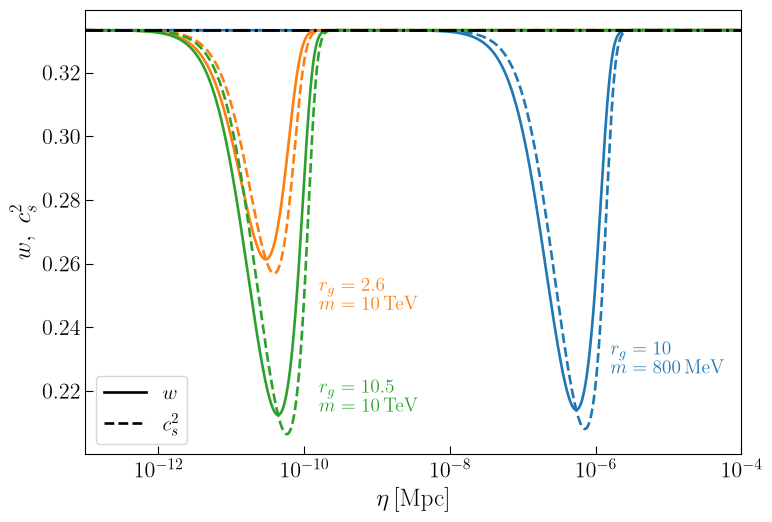

In [96]:
# Quick background sanity plot: three analytic stepped-fluid backgrounds.
# Display only: no production background, transfer function or cache is changed.
from matplotlib.lines import Line2D

# The input tables are exactly rg=10, x=1e7*(CSV first column).
# Under T=C/y this means m=1e7*C = 801.2607 MeV (approximately 800 MeV).
print('Production table parameters: rg=10, m=', 1e7*DIRECT_ETA_T_CONSTANT, 'MeV')
print('Comparison convention: same early T=C/eta and BACKGROUND_SETTINGS.')

analytic_cases = [
    (10.0, 800.0, r'$r_g=10$' + '\n' + r'$m=800\,\mathrm{MeV}$', 'C0'),
    (2.6, 1e7, r'$r_g=2.6$' + '\n' + r'$m=10\,\mathrm{TeV}$', 'C1'),
    (10.5, 1e7, r'$r_g=10.5$' + '\n' + r'$m=10\,\mathrm{TeV}$', 'C2'),
]

fig, ax = plt.subplots(figsize=(8, 5.5))
for rg_demo, mass_demo, label, color in analytic_cases:
    demo_history = analytic_history(
        rg_demo, mass_demo, DIRECT_ETA_T_CONSTANT, BACKGROUND_SETTINGS)
    eta_demo = demo_history['eta']
    ax.plot(eta_demo, demo_history['w'], color=color, lw=1.9)
    ax.plot(eta_demo, demo_history['cs2'], color=color, ls='--', lw=1.9)
    # Color identifies the parameters; line style identifies the quantity.
    text_position = {(10.0, 800.0): (1.6e-6, 0.230),
                     (2.6, 1e7): (1.6e-10, 0.250),
                     (10.5, 1e7): (1.6e-10, 0.218)}[(rg_demo, mass_demo)]
    minimum = np.argmin(demo_history['w'])
    ax.annotate(label, xy=(eta_demo[minimum], demo_history['w'][minimum]),
                xytext=text_position, color=color, fontsize=14,
                ha='left', va='center')
ax.set_xscale('log')
ax.set_xlabel(r'$\eta\,[\mathrm{Mpc}]$')
ax.set_ylabel(r'$w,\ c_s^2$')
ax.legend(handles=[Line2D([], [], color='black', lw=1.9, label=r'$w$'),
                   Line2D([], [], color='black', lw=1.9, ls='--',
                          label=r'$c_s^2$')], loc='lower left')
ax.axhline(1/3, color='black',ls='-.')
ax.set_xlim(1e-13,1e-4)
fig.tight_layout()
plt.savefig('plot/PT_model.pdf')
if '__file__' not in globals():
    plt.show()
else:
    plt.close()


## Scalar transfer function `Phi`

The Bardeen equation is implemented in the form used in arXiv:2307.01653,

\[
\Phi_k''+3\mathcal{H}(1+c_s^2)\Phi_k'
+\left[c_s^2 k^2+3\mathcal{H}^2(c_s^2-w)\right]\Phi_k=0.
\]

The ODE is solved in the dimensionless variable `x = k eta`, which is faster and numerically better scaled. At `x_ini`, the decaying mode is removed and the growing superhorizon solution $\Phi=-A(\eta)$ is used, with $A=1-\mathcal{H}a^{-2}\int_0^\eta a^2d\tilde\eta$. The saved `Phi_prime_mat_*` remains `dPhi/deta`.


In [97]:
X_INI = 1e-3
X_FINAL = 1e3
N_X_DEFAULT = 8000
PHI_RTOL = 3e-8
PHI_ATOL = 1e-10
PHI_INITIAL_CONDITION = 'analytic_superhorizon_v1' # initial condition: 'analytic_superhorizon_v1' or 'pure_radiation'

@dataclass(frozen=True)
class TransferChunk:
    label: str
    k_min: float
    k_max: float
    n_k: int


PHI_CHUNKS = [
    # Extend to 1e-2--1e16 Mpc^-1 without changing existing chunk grids.
    TransferChunk('02', 1e0, 1e2, 120),
    TransferChunk('24', 1e2, 1e4, 200),
    TransferChunk('46', 1e4, 1e6, 200),
    TransferChunk('68', 1e6, 1e8, 200),
    TransferChunk('810', 1e8, 1e10, 200),
    TransferChunk('1014', 1e10, 1e14, 400),
]


def phi_rhs_x(x, y, k):
    phi, dphi_dx = y
    eta = x / k
    h_over_k = conH_interp(eta) / k
    cs2 = c_s_sq(eta)
    w = eos(eta)
    d2phi_dx2 = -3.0 * (1.0 + cs2) * h_over_k * dphi_dx - (cs2 + 3.0 * h_over_k**2 * (cs2 - w)) * phi
    return [dphi_dx, d2phi_dx2]


def _superhorizon_integral(eta, n_points=4096):
    """Numerically evaluate integral_0^eta a(eta')^2 d eta'."""
    eta = float(eta)
    eta_grid = np.geomspace(eta / 1e4, eta, int(n_points))
    return trapezoid(a_interp(eta_grid)**2, eta_grid)


def superhorizon_mode(eta):
    """Growing adiabatic superhorizon mode A(eta), with decay mode removed."""
    eta = float(eta)
    integral = _superhorizon_integral(eta)
    return 1.0 - conH_interp(eta) * integral / a_interp(eta)**2


def superhorizon_mode_prime(eta):
    """Conformal-time derivative of the growing superhorizon mode."""
    eta = float(eta)
    integral_over_a2 = _superhorizon_integral(eta) / a_interp(eta)**2
    H = conH_interp(eta)
    return -(conHprime_interp(eta) - 2.0 * H**2) * integral_over_a2 - H


def solve_phi_transfer(
    k,
    x_grid=None,
    rtol=PHI_RTOL,
    atol=PHI_ATOL,
    initial_condition=PHI_INITIAL_CONDITION,
):
    if x_grid is None:
        x_grid = np.geomspace(X_INI, X_FINAL, N_X_DEFAULT)
    k = float(k)
    x0 = float(x_grid[0])
    eta0 = x0 / k
    if initial_condition == 'analytic_superhorizon_v1':
        # Growing superhorizon solution per unit zeta, as in SIGW_EoS.ipynb:
        # Phi=-A(eta), dPhi/dx=-A'(eta)/k; the decaying mode is set to zero.
        y0 = [-superhorizon_mode(eta0), -superhorizon_mode_prime(eta0) / k]
    elif initial_condition == 'pure_radiation':
        # Radiation-era analytic solution at x_ini=k*eta_ini.
        y0 = [-2.0 / 3.0 * (1.0 - x0**2 / 30.0), 2.0 * x0 / 45.0]
    else:
        raise ValueError(
            f"initial_condition must be {PHI_INITIAL_CONDITION!r} or 'pure_radiation'"
        )
    sol = solve_ivp(
        phi_rhs_x,
        (float(x_grid[0]), float(x_grid[-1])),
        y0,
        t_eval=x_grid,
        args=(k,),
        method='DOP853',
        rtol=rtol,
        atol=atol,
    )
    if not sol.success:
        raise RuntimeError(f'Phi solver failed for k={k:.6g}: {sol.message}')
    phi = sol.y[0]
    phi_prime_eta = k * sol.y[1]
    return phi, phi_prime_eta


def _chunk_paths(chunk, directory=PHI_CACHE_DIR):
    return {
        'phi': directory / f'Phi_mat_{chunk.label}.npy',
        'phi_prime': directory / f'Phi_prime_mat_{chunk.label}.npy',
        'meta': directory / f'Phi_meta_{chunk.label}.json',
    }


def _phi_cache_compatible(chunk, directory=PHI_CACHE_DIR, n_x=N_X_DEFAULT):
    paths = _chunk_paths(chunk, directory=directory)
    if not (paths['phi'].exists() and paths['phi_prime'].exists() and paths['meta'].exists()):
        return False
    try:
        meta = json.loads(paths['meta'].read_text())
    except (OSError, json.JSONDecodeError):
        return False
    return (
        meta.get('label') == chunk.label
        and np.isclose(float(meta.get('k_min')), chunk.k_min)
        and np.isclose(float(meta.get('k_max')), chunk.k_max)
        and int(meta.get('n_k')) == int(chunk.n_k)
        and np.isclose(float(meta.get('x_ini')), X_INI)
        and np.isclose(float(meta.get('x_final')), X_FINAL)
        and int(meta.get('n_x')) == int(n_x)
        and meta.get('initial_condition') == PHI_INITIAL_CONDITION
    )


def save_phi_chunk(chunk, n_x=N_X_DEFAULT, overwrite=False):
    paths = _chunk_paths(chunk)
    cache_exists = paths['phi'].exists() and paths['phi_prime'].exists()
    if not overwrite and cache_exists and _phi_cache_compatible(chunk, n_x=n_x):
        print(f'Phi chunk {chunk.label} already exists with initial_condition={PHI_INITIAL_CONDITION}; reusing it')
        return
    if cache_exists and not _phi_cache_compatible(chunk, n_x=n_x):
        print(f'Phi chunk {chunk.label} has incompatible metadata; regenerating it')
    x_grid = np.geomspace(X_INI, X_FINAL, int(n_x))
    k_grid = np.geomspace(chunk.k_min, chunk.k_max, chunk.n_k)
    phi_mat = np.empty((chunk.n_k, int(n_x)), dtype=np.float64)
    phi_prime_mat = np.empty_like(phi_mat)
    for i, k in enumerate(k_grid, start=1):
        phi_mat[i - 1], phi_prime_mat[i - 1] = solve_phi_transfer(k, x_grid=x_grid)
        if i == 1 or i == chunk.n_k or i % max(1, chunk.n_k // 20) == 0:
            print(f'Phi {chunk.label}: {i}/{chunk.n_k}')
    np.save(paths['phi'], phi_mat)
    np.save(paths['phi_prime'], phi_prime_mat)
    paths['meta'].write_text(json.dumps({
        'label': chunk.label,
        'k_min': chunk.k_min,
        'k_max': chunk.k_max,
        'n_k': chunk.n_k,
        'x_ini': X_INI,
        'x_final': X_FINAL,
        'n_x': int(n_x),
        'phi_prime': 'dPhi/deta',
        'initial_condition': PHI_INITIAL_CONDITION,
        'normalization': (
            'Phi per unit zeta; pure-radiation analytic initial condition'
            if PHI_INITIAL_CONDITION == 'pure_radiation'
            else 'Phi per unit zeta; growing analytic superhorizon mode Phi=-A(eta), decaying mode removed'
        ),
    }, indent=2))


def phi_chunk_available(chunk):
    return _phi_cache_compatible(chunk)


def generate_missing_phi_chunks(chunks=PHI_CHUNKS, n_x=N_X_DEFAULT):
    for chunk in chunks:
        save_phi_chunk(chunk, n_x=n_x, overwrite=False)


def default_kernel_log10s_grid():
    # Match the unique grid used by the original notebook.  The original
    # construction included the two segment joins twice and removed the
    # duplicates before building the 3-D interpolator.
    return np.r_[
        np.linspace(-2, -0.5, 10)[:-1],
        np.linspace(-0.5, 0.5, 50)[:-1],
        np.linspace(0.5, 2, 20),
    ]


def default_kernel_t_grid():
    # The original kernel files used t <= 0.7 (20 points).
    return np.linspace(0.0, 0.7, 20)


def scalar_k_range_for_kernel(k_grid, log10s_grid=None, t_grid=None):
    if log10s_grid is None:
        log10s_grid = default_kernel_log10s_grid()
    if t_grid is None:
        t_grid = default_kernel_t_grid()
    s_mesh, t_mesh = np.meshgrid(np.asarray(log10s_grid, dtype=float), np.asarray(t_grid, dtype=float), indexing='xy')
    u_mesh, v_mesh = st_to_uv(s_mesh, t_mesh)
    scalar_multiplier_min = float(np.nanmin([np.nanmin(u_mesh), np.nanmin(v_mesh)]))
    scalar_multiplier_max = float(np.nanmax([np.nanmax(u_mesh), np.nanmax(v_mesh)]))
    k_grid = np.asarray(k_grid, dtype=float)
    return float(np.nanmin(k_grid) * scalar_multiplier_min), float(np.nanmax(k_grid) * scalar_multiplier_max)


def required_phi_chunks_for_kernel(k_grid, log10s_grid=None, t_grid=None):
    scalar_k_min, scalar_k_max = scalar_k_range_for_kernel(k_grid, log10s_grid, t_grid)
    required = [chunk for chunk in PHI_CHUNKS if chunk.k_max >= scalar_k_min and chunk.k_min <= scalar_k_max]
    if not required or required[0].k_min > scalar_k_min or required[-1].k_max < scalar_k_max:
        raise ValueError(
            f'PHI_CHUNKS do not cover scalar k range [{scalar_k_min:.6g}, {scalar_k_max:.6g}] required by this kernel grid.'
        )
    return required


def ensure_phi_chunks_for_kernel(k_grid, log10s_grid=None, t_grid=None, n_x=N_X_DEFAULT):
    scalar_k_min, scalar_k_max = scalar_k_range_for_kernel(k_grid, log10s_grid, t_grid)
    required = required_phi_chunks_for_kernel(k_grid, log10s_grid, t_grid)
    missing = [chunk for chunk in required if not phi_chunk_available(chunk)]
    print(f'Kernel scalar transfer k range: [{scalar_k_min:.6g}, {scalar_k_max:.6g}]')
    if missing:
        print('Generating missing Phi chunks for kernel:', [chunk.label for chunk in missing])
        generate_missing_phi_chunks(missing, n_x=n_x)
    return scalar_k_min, scalar_k_max


In [98]:
def phi_ana(k, eta): # transfer function for Newtonian potential
    return -6/(k*eta)**2 * (np.sin(k*eta/np.sqrt(3))/(k*eta/np.sqrt(3)) - np.cos(k*eta/np.sqrt(3)))
def phi_p_ana(k, eta): # derivative for the transfer function
    return -2/(eta**4 * k**3) * (9*eta*k * np.cos(k*eta/np.sqrt(3)) + np.sqrt(3) * (-9+k**2 * eta**2)*np.sin(k*eta/np.sqrt(3)))


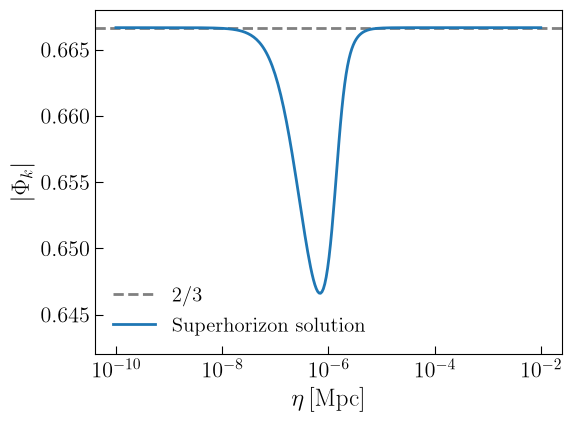

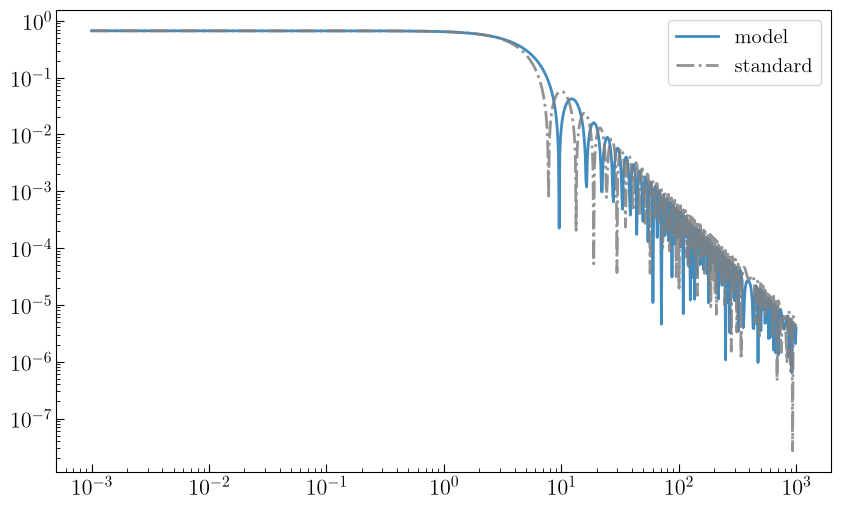

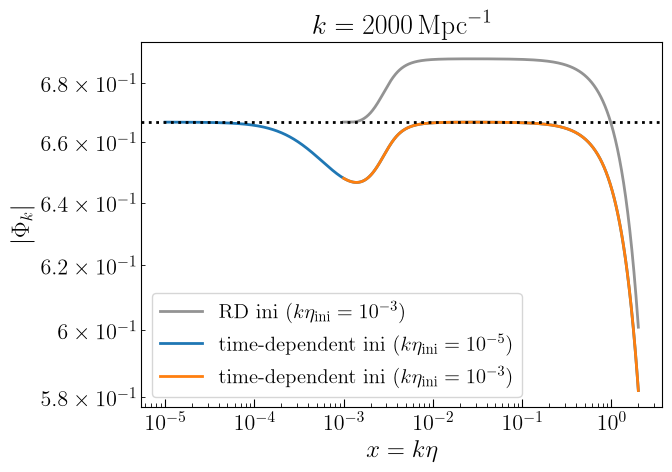

In [99]:
# This cell requires the updated solver definition above.  In a live Jupyter
# kernel, rerun that definition cell after editing the notebook.
import inspect
if 'initial_condition' not in inspect.signature(solve_phi_transfer).parameters:
    raise RuntimeError(
        'The kernel still has the old solve_phi_transfer definition. '
        'Rerun the Phi solver-definition cell above, then rerun this cell.'
    )

eta_span = np.geomspace(1e-10, 1e-2, 300)
superhorizon_fractional_shift = np.array([
    superhorizon_mode(eta)
    for eta in eta_span
])
plt.figure(figsize=(6, 4.5))

plt.axhline(2/3, color='gray', ls='--', label='2/3')
plt.plot(eta_span, superhorizon_fractional_shift, label='Superhorizon solution')
plt.xlabel(r'$\eta\,[\mathrm{Mpc}]$')
plt.xscale('log')
plt.ylabel(r'$|\Phi_k|$')
plt.ylim(0.642,0.668)
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig('plot/superhorizon solution model.pdf')
plt.show()

k_value = 1.2e7
comparison_x = np.geomspace(1e-3,1e+3,1000)
phi_radiation, _ = solve_phi_transfer(
        k_value, x_grid=comparison_x, initial_condition='pure_radiation'
)
plt.loglog(comparison_x, abs(phi_radiation),
              alpha=0.85, label='model')
plt.loglog(comparison_x, abs(phi_ana(k_value,comparison_x/k_value)), color = 'gray',alpha=0.85, ls='-.', label = 'standard')
plt.legend()
plt.show()

plt.figure(figsize=(7, 5))
k_value = 2e3
comparison_x = np.geomspace(1e-3,2,1000)
comparison_x_deep = np.geomspace(1e-5,2,1200)
phi_radiation, _ = solve_phi_transfer(
        k_value, x_grid=comparison_x, initial_condition='pure_radiation'
)
phi_superhorizon, _ = solve_phi_transfer(
        k_value, x_grid=comparison_x, initial_condition='analytic_superhorizon_v1'
)
phi_superhorizon_deep, _ = solve_phi_transfer(
        k_value, x_grid=comparison_x_deep, initial_condition='analytic_superhorizon_v1'
)
plt.loglog(comparison_x, abs(phi_radiation), color = 'gray',alpha=0.85, label = r'RD ini ($k\eta_{\rm ini}=10^{-3}$)')
plt.loglog(comparison_x_deep, abs(phi_superhorizon_deep), ls='-', label = r'time-dependent ini ($k\eta_{\rm ini}=10^{-5}$)')
plt.loglog(comparison_x, abs(phi_superhorizon) , ls='-', label = r'time-dependent ini ($k\eta_{\rm ini}=10^{-3}$)')
plt.title(r'$k=2000\,\mathrm{Mpc}^{-1}$')
plt.axhline(2/3, color='black', ls=':')
plt.legend()
plt.xlabel(r'$x=k\eta$')
plt.ylabel(r'$|\Phi_k|$')
plt.tight_layout()
plt.savefig('plot/Phi_ini.pdf')
plt.show()


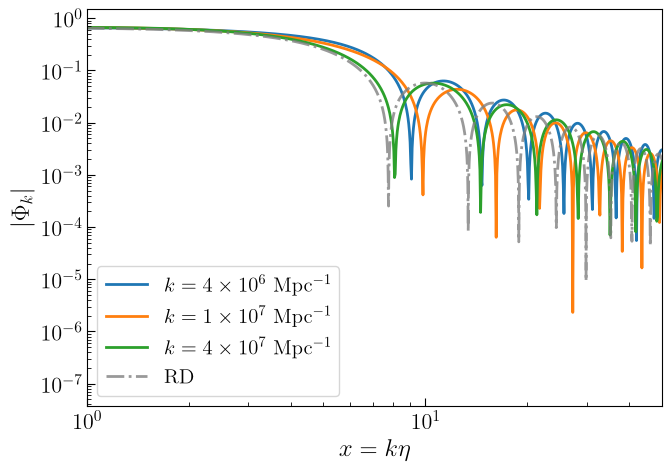

In [100]:
plt.figure(figsize=(7, 5))
comparison_x = np.geomspace(1e0,1e+2,1000)
k_value = 4e6
phi_radiation, _ = solve_phi_transfer(k_value, x_grid=comparison_x, initial_condition='analytic_superhorizon_v1')
plt.plot(comparison_x, abs(phi_radiation),   label=r'$k=4\times10^6$ Mpc$^{{-1}}$')
k_value = 1e7
phi_radiation, _ = solve_phi_transfer(k_value, x_grid=comparison_x, initial_condition='analytic_superhorizon_v1')
plt.plot(comparison_x, abs(phi_radiation),  label=r'$k=1\times10^7$ Mpc$^{{-1}}$')
k_value = 4e7
phi_radiation, _ = solve_phi_transfer(k_value, x_grid=comparison_x, initial_condition='analytic_superhorizon_v1')
plt.plot(comparison_x, abs(phi_radiation),   label=r'$k=4\times10^7$ Mpc$^{{-1}}$')


x_value = np.geomspace(1e-3,1e+3,10000)
plt.plot(x_value, abs(phi_ana(1e7,x_value/1e7)), color = 'gray',alpha=0.8, ls='-.', label = 'RD')
plt.xlim(1,50)
plt.yscale('log')
plt.xscale('log')
plt.xlabel(r'$x=k\eta$')
plt.ylabel(r'$|\Phi_k|$')
plt.legend()
plt.tight_layout()
plt.savefig('plot/model_Phi.pdf')
plt.show()

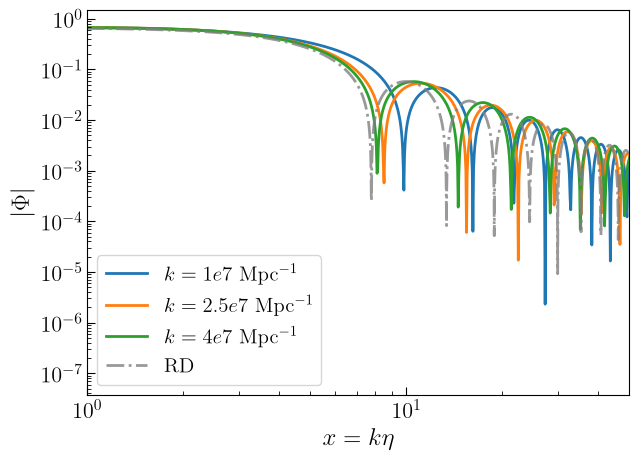

In [101]:
plt.figure(figsize=(7, 5))
comparison_x = np.geomspace(1e0,1e+2,1000)
k_value = 1e7
phi_radiation, _ = solve_phi_transfer(k_value, x_grid=comparison_x, initial_condition='analytic_superhorizon_v1')
plt.plot(comparison_x, abs(phi_radiation),  label=r'$k=1e7$ Mpc$^{{-1}}$')
k_value = 2.5e7
phi_radiation, _ = solve_phi_transfer(k_value, x_grid=comparison_x, initial_condition='analytic_superhorizon_v1')
plt.plot(comparison_x, abs(phi_radiation),   label=r'$k=2.5e7$ Mpc$^{{-1}}$')
k_value = 4e7
phi_radiation, _ = solve_phi_transfer(k_value, x_grid=comparison_x, initial_condition='analytic_superhorizon_v1')
plt.plot(comparison_x, abs(phi_radiation),   label=r'$k=4e7$ Mpc$^{{-1}}$')


x_value = np.geomspace(1e-3,1e+3,10000)
plt.plot(x_value, abs(phi_ana(1e7,x_value/1e7)), color = 'gray',alpha=0.8, ls='-.', label = 'RD')
plt.xlim(1,50)
plt.yscale('log')
plt.xscale('log')
plt.xlabel(r'$x=k\eta$')
plt.ylabel(r'$|\Phi|$')
plt.legend()
plt.show()

In [102]:
# Set this to True to regenerate missing/incompatible scalar transfer chunks.
# This can take a long time for the 1e6-1e8 chunk because it has many k modes.
if PHI_INITIAL_CONDITION not in {'analytic_superhorizon_v1', 'pure_radiation'}:
    raise ValueError(f'Unsupported PHI_INITIAL_CONDITION: {PHI_INITIAL_CONDITION!r}')
print(f'Phi cache initial condition: {PHI_INITIAL_CONDITION}')
RUN_PHI_PRECOMPUTE = False
if RUN_PHI_PRECOMPUTE:
    generate_missing_phi_chunks()
else:
    missing = [c.label for c in PHI_CHUNKS if not (_chunk_paths(c)['phi'].exists() and _chunk_paths(c)['phi_prime'].exists())]
    print('Phi precompute skipped. Missing updated-cache chunks:', missing)
    print('Old-background Phi chunks are not compatible with the thermal background.')


Phi cache initial condition: analytic_superhorizon_v1
Phi precompute skipped. Missing updated-cache chunks: []
Old-background Phi chunks are not compatible with the thermal background.


In [103]:
def _interp_rows_on_log_grid(values, x_grid, x_query):
    """Fast local cubic interpolation for one cached curve per query row."""
    values = np.asarray(values, dtype=float)
    x_grid = np.asarray(x_grid, dtype=float)
    x_query = np.asarray(x_query, dtype=float)
    if values.ndim != 2 or x_query.ndim != 2 or values.shape[0] != x_query.shape[0]:
        raise ValueError('values and x_query must be 2-D arrays with matching row counts.')

    rtol = 1e-10
    atol = 1e-14
    if np.any(x_query < x_grid[0] * (1.0 - rtol) - atol) or np.any(x_query > x_grid[-1] * (1.0 + rtol) + atol):
        raise ValueError(
            f'Prepared transfer requested outside x=[{x_grid[0]:.6g}, {x_grid[-1]:.6g}]'
        )
    x_clipped = np.clip(x_query, x_grid[0], x_grid[-1])
    log_x0 = math.log(x_grid[0])
    dlog_x = math.log(x_grid[-1] / x_grid[0]) / (len(x_grid) - 1)
    position = (np.log(x_clipped) - log_x0) / dlog_x
    i0 = np.clip(np.floor(position).astype(np.int64) - 1, 0, len(x_grid) - 4)
    z = position - i0

    # Four-point Lagrange interpolation on the uniform log(x) cache grid.
    out = np.take_along_axis(values, i0, axis=1)
    out *= -((z - 1.0) * (z - 2.0) * (z - 3.0)) / 6.0
    sample = np.take_along_axis(values, i0 + 1, axis=1)
    out += sample * (z * (z - 2.0) * (z - 3.0)) / 2.0
    sample = np.take_along_axis(values, i0 + 2, axis=1)
    out -= sample * (z * (z - 1.0) * (z - 3.0)) / 2.0
    sample = np.take_along_axis(values, i0 + 3, axis=1)
    out += sample * (z * (z - 1.0) * (z - 2.0)) / 6.0
    return out


def _interp_one_on_log_grid(values, x_grid, x_query):
    """Fast local cubic interpolation of one cached curve at an array of x."""
    query = np.asarray(x_query, dtype=float)
    flat = query.reshape(1, -1)
    repeated_values = np.asarray(values, dtype=float).reshape(1, -1)
    return _interp_rows_on_log_grid(repeated_values, x_grid, flat).reshape(query.shape)


class RowwiseCubicHermite:
    """Coupled value/derivative interpolation for one query grid per row."""
    def __init__(self, x_grid, values, derivatives):
        self.x_grid = np.asarray(x_grid, dtype=float)
        self.values = np.asarray(values, dtype=float)
        self.derivatives = np.asarray(derivatives, dtype=float)
        if self.values.shape != self.derivatives.shape or self.values.shape[1] != len(self.x_grid):
            raise ValueError('Hermite values and derivatives must match the x grid.')

    def _interval_data(self, x_query):
        x_query = np.asarray(x_query, dtype=float)
        if x_query.ndim != 2 or x_query.shape[0] != self.values.shape[0]:
            raise ValueError('Hermite transfer queries must be 2-D with one row per prepared mode.')
        rtol = 1e-10
        atol = 1e-14
        if (
            np.any(x_query < self.x_grid[0] * (1.0 - rtol) - atol)
            or np.any(x_query > self.x_grid[-1] * (1.0 + rtol) + atol)
        ):
            raise ValueError(
                f'Prepared transfer requested outside x=[{self.x_grid[0]:.6g}, {self.x_grid[-1]:.6g}]'
            )
        x_query = np.clip(x_query, self.x_grid[0], self.x_grid[-1])
        interval = np.searchsorted(self.x_grid, x_query, side='right') - 1
        interval = np.clip(interval, 0, len(self.x_grid) - 2)
        x0 = self.x_grid[interval]
        h = self.x_grid[interval + 1] - x0
        z = (x_query - x0) / h
        y0 = np.take_along_axis(self.values[:, :-1], interval, axis=1)
        y1 = np.take_along_axis(self.values[:, 1:], interval, axis=1)
        m0 = np.take_along_axis(self.derivatives[:, :-1], interval, axis=1)
        m1 = np.take_along_axis(self.derivatives[:, 1:], interval, axis=1)
        return z, h, y0, y1, m0, m1

    def value(self, x_query):
        z, h, y0, y1, m0, m1 = self._interval_data(x_query)
        z2 = z * z
        z3 = z2 * z
        return (
            (2.0 * z3 - 3.0 * z2 + 1.0) * y0
            + (z3 - 2.0 * z2 + z) * h * m0
            + (-2.0 * z3 + 3.0 * z2) * y1
            + (z3 - z2) * h * m1
        )

    def derivative(self, x_query):
        z, h, y0, y1, m0, m1 = self._interval_data(x_query)
        z2 = z * z
        return (
            (6.0 * z2 - 6.0 * z) * y0 / h
            + (3.0 * z2 - 4.0 * z + 1.0) * m0
            + (-6.0 * z2 + 6.0 * z) * y1 / h
            + (3.0 * z2 - 2.0 * z) * m1
        )


class PreparedRowwisePhi:
    def __init__(self, x_grid, phi, phi_prime_eta, mode_k):
        self.mode_k = np.asarray(mode_k, dtype=float)
        self.hermite = RowwiseCubicHermite(
            x_grid,
            phi,
            np.asarray(phi_prime_eta, dtype=float) / self.mode_k[:, None],
        )

    def phi(self, x_query):
        return self.hermite.value(x_query)

    def phi_prime(self, x_query):
        shape = (len(self.mode_k),) + (1,) * (np.ndim(x_query) - 1)
        return self.hermite.derivative(x_query) * self.mode_k.reshape(shape)


class PreparedPhiModes:
    def __init__(self, groups, shape):
        self.groups = groups
        self.shape = tuple(shape)

    def _eval(self, x, key):
        x = np.asarray(x, dtype=float)
        if x.shape[0] != self.shape[0]:
            raise ValueError('Prepared Phi rows no longer match the requested scalar modes.')
        out = np.empty_like(x, dtype=float)
        for group in self.groups:
            rows = group['rows']
            out[rows] = group[key](x[rows])
        return out

    def phi(self, x):
        return self._eval(x, 'phi')

    def phi_prime(self, x):
        return self._eval(x, 'phi_prime')


class PreparedPhiPair:
    def __init__(self, u_modes, v_modes):
        self.u_modes = u_modes
        self.v_modes = v_modes


class PiecewisePhiTransfer:
    def __init__(
        self,
        chunks=PHI_CHUNKS,
        prefer_updated=True,
        cache_dir=PHI_CACHE_DIR,
        allow_original=False,
        ignore_metadata=False,
    ):
        self.entries = []
        self.cache_dir = Path(cache_dir)
        for chunk in chunks:
            updated = _chunk_paths(chunk, directory=self.cache_dir)
            original_phi = DATA_DIR / f'Phi_mat_{chunk.label}.npy'
            original_prime = DATA_DIR / f'Phi_prime_mat_{chunk.label}.npy'
            if prefer_updated and (
                _phi_cache_compatible(chunk, directory=self.cache_dir)
                or (ignore_metadata and updated['phi'].exists() and updated['phi_prime'].exists())
            ):
                phi_path = updated['phi']
                prime_path = updated['phi_prime']
                meta_path = updated['meta']
            elif allow_original and original_phi.exists() and original_prime.exists():
                phi_path = original_phi
                prime_path = original_prime
                meta_path = None
            else:
                continue

            phi = np.load(phi_path, mmap_mode='r')
            phi_prime = np.load(prime_path, mmap_mode='r')
            if phi.shape != phi_prime.shape:
                raise ValueError(f'Shape mismatch in Phi chunk {chunk.label}')
            if meta_path and meta_path.exists():
                meta = json.loads(meta_path.read_text())
                k_grid = np.geomspace(meta['k_min'], meta['k_max'], meta['n_k'])
                x_grid = np.geomspace(meta['x_ini'], meta['x_final'], meta['n_x'])
            else:
                k_grid = np.geomspace(chunk.k_min, chunk.k_max, phi.shape[0])
                x_grid = np.geomspace(X_INI, X_FINAL, phi.shape[1])
            self.entries.append({
                'label': chunk.label,
                'k_min': float(k_grid[0]),
                'k_max': float(k_grid[-1]),
                'x_min': float(x_grid[0]),
                'x_max': float(x_grid[-1]),
                'x_grid': x_grid,
                'phi_interp': RectBivariateSpline(np.log10(k_grid), x_grid, phi, kx=3, ky=3, s=0),
                'prime_interp': RectBivariateSpline(np.log10(k_grid), x_grid, phi_prime, kx=3, ky=3, s=0),
            })
        if not self.entries:
            raise FileNotFoundError('No Phi chunks were found. Generate them first with RUN_PHI_PRECOMPUTE=True.')
        print('Loaded Phi chunks:', [e['label'] for e in self.entries])

    def _eval(self, k, x, key):
        k_arr, x_arr = np.broadcast_arrays(np.asarray(k, dtype=float), np.asarray(x, dtype=float))
        out = np.full(k_arr.shape, np.nan, dtype=float)
        k_flat = k_arr.ravel()
        x_flat = x_arr.ravel()
        out_flat = out.ravel()
        rtol = 1e-10
        atol = 1e-14
        for entry in self.entries:
            k_min, k_max = entry['k_min'], entry['k_max']
            x_min, x_max = entry['x_min'], entry['x_max']
            mask = (
                (k_flat >= k_min * (1.0 - rtol)) & (k_flat <= k_max * (1.0 + rtol)) &
                (x_flat >= x_min * (1.0 - rtol) - atol) & (x_flat <= x_max * (1.0 + rtol) + atol)
            )
            if np.any(mask):
                k_eval = np.clip(k_flat[mask], k_min, k_max)
                x_eval = np.clip(x_flat[mask], x_min, x_max)
                out_flat[mask] = entry[key].ev(np.log10(k_eval), x_eval)
        if np.any(~np.isfinite(out_flat)):
            bad = np.where(~np.isfinite(out_flat))[0][0]
            loaded = ', '.join(
                f"{e['label']}: k=[{e['k_min']:.3g}, {e['k_max']:.3g}], x=[{e['x_min']:.3g}, {e['x_max']:.3g}]"
                for e in self.entries
            )
            raise ValueError(
                f'Phi transfer requested outside cached range: k={k_flat[bad]:.12g}, x={x_flat[bad]:.12g}. '
                f'Loaded chunks: {loaded}. Generate a wider Phi chunk or reduce integration bounds.'
            )
        return float(out) if np.isscalar(k) and np.isscalar(x) else out

    def covers_k_range(self, k_min, k_max, rtol=1e-10):
        intervals = sorted((entry['k_min'], entry['k_max']) for entry in self.entries)
        target = float(k_min)
        end = float(k_max)
        for lo, hi in intervals:
            if hi < target * (1.0 - rtol):
                continue
            if lo > target * (1.0 + rtol):
                return False
            target = max(target, hi)
            if target >= end * (1.0 - rtol):
                return True
        return False

    def phi(self, k, x):
        return self._eval(k, x, 'phi_interp')

    def phi_prime(self, k, x):
        return self._eval(k, x, 'prime_interp')

    def prepare_modes(self, k_values):
        k_values = np.asarray(k_values, dtype=float).reshape(-1)
        entry_index = np.full(k_values.shape, -1, dtype=int)
        rtol = 1e-10
        for index, entry in enumerate(self.entries):
            mask = (
                (k_values >= entry['k_min'] * (1.0 - rtol))
                & (k_values <= entry['k_max'] * (1.0 + rtol))
            )
            entry_index[mask] = index
        if np.any(entry_index < 0):
            bad = int(np.where(entry_index < 0)[0][0])
            raise ValueError(f'Cannot prepare Phi transfer for k={k_values[bad]:.12g}.')

        groups = []
        for index in np.unique(entry_index):
            entry = self.entries[int(index)]
            rows = np.where(entry_index == index)[0]
            k_eval = np.clip(k_values[rows], entry['k_min'], entry['k_max'])
            unique_logk, inverse = np.unique(np.log10(k_eval), return_inverse=True)
            x_grid = entry['x_grid']
            phi_unique = entry['phi_interp'](unique_logk, x_grid, grid=True)
            prime_unique = entry['prime_interp'](unique_logk, x_grid, grid=True)
            transfer = PreparedRowwisePhi(
                x_grid,
                phi_unique[inverse],
                prime_unique[inverse],
                k_eval,
            )
            groups.append({
                'rows': rows,
                'x_grid': x_grid,
                'phi': transfer.phi,
                'phi_prime': transfer.phi_prime,
            })
        return PreparedPhiModes(groups, k_values.shape)

    def prepare_pair(self, u_values, v_values, tensor_k):
        return PreparedPhiPair(
            self.prepare_modes(np.asarray(u_values, dtype=float) * float(tensor_k)),
            self.prepare_modes(np.asarray(v_values, dtype=float) * float(tensor_k)),
        )


# Load explicitly after the needed Phi chunks exist. This avoids building large
# spline objects just by opening/running the notebook header.
LOAD_PHI_CACHE_NOW = True
phi_cache = PiecewisePhiTransfer() if LOAD_PHI_CACHE_NOW else None


Loaded Phi chunks: ['02', '24', '46', '68', '810', '1014']


## Tensor Green function

For the variable `g = a h`, the homogeneous equation is

\[
g_k'' + \left[k^2 - \frac{1-3w}{2}\mathcal{H}^2\right]g_k = 0.
\]

The derivative matrices below store `dg/deta`, so the Wronskian in the Green function has the correct conformal-time normalization.


In [104]:
GREEN_CHUNKS = [
    # Retain the established middle chunk and extend both ends at 100 points/dex.
    TransferChunk('23', 1e2, 1e3, 100),
    TransferChunk('310', 1e3, 1e10, 700),
]
GREEN_RTOL = 3e-8
GREEN_ATOL = 1e-10
GREEN_X_FINAL = 1000.0  # Legacy cache endpoint; x>30 uses harmonic extension.
GREEN_HARMONIC_FROM = 30.0


def green_rhs_x(x, y, k):
    g, dg_dx = y
    eta = x / k
    d2g_dx2 = -(1.0 - tensor_mass_over_k2(eta, k)) * g
    return [dg_dx, d2g_dx2]


def solve_green_modes(k, x_grid=None, rtol=GREEN_RTOL, atol=GREEN_ATOL):
    if x_grid is None:
        x_grid = np.geomspace(X_INI, GREEN_X_FINAL, N_X_DEFAULT)
    x0 = float(x_grid[0])
    # Two independent superhorizon-like basis functions. Only independence
    # matters for the Green function; the Wronskian handles normalization.
    y0_1 = [x0, 1.0]
    y0_2 = [1.0, 0.0]
    sol1 = solve_ivp(green_rhs_x, (x_grid[0], x_grid[-1]), y0_1, t_eval=x_grid, args=(float(k),), method='DOP853', rtol=rtol, atol=atol)
    sol2 = solve_ivp(green_rhs_x, (x_grid[0], x_grid[-1]), y0_2, t_eval=x_grid, args=(float(k),), method='DOP853', rtol=rtol, atol=atol)
    if not sol1.success:
        raise RuntimeError(f'Green mode 1 failed for k={k:.6g}: {sol1.message}')
    if not sol2.success:
        raise RuntimeError(f'Green mode 2 failed for k={k:.6g}: {sol2.message}')
    return sol1.y[0], float(k) * sol1.y[1], sol2.y[0], float(k) * sol2.y[1]


def _green_chunk_paths(chunk, directory=GREEN_CACHE_DIR):
    return {
        'g1': directory / f'g1_mat_{chunk.label}.npy',
        'g1_prime': directory / f'g1_prime_mat_{chunk.label}.npy',
        'g2': directory / f'g2_mat_{chunk.label}.npy',
        'g2_prime': directory / f'g2_prime_mat_{chunk.label}.npy',
        'meta': directory / f'green_meta_{chunk.label}.json',
    }


def save_green_chunk(chunk, n_x=N_X_DEFAULT, overwrite=False):
    paths = _green_chunk_paths(chunk)
    if not overwrite and all(paths[key].exists() for key in ('g1', 'g1_prime', 'g2', 'g2_prime')):
        # Reuse the established full-EoS Green cache.
        print(f'Green chunk {chunk.label} already exists; reusing it')
        return
    x_grid = np.geomspace(X_INI, GREEN_X_FINAL, int(n_x))
    k_grid = np.geomspace(chunk.k_min, chunk.k_max, chunk.n_k)
    mats = [np.empty((chunk.n_k, int(n_x)), dtype=np.float64) for _ in range(4)]
    for i, k in enumerate(k_grid, start=1):
        g1, g1p, g2, g2p = solve_green_modes(k, x_grid=x_grid)
        mats[0][i - 1] = g1
        mats[1][i - 1] = g1p
        mats[2][i - 1] = g2
        mats[3][i - 1] = g2p
        if i == 1 or i == chunk.n_k or i % max(1, chunk.n_k // 20) == 0:
            print(f'Green {chunk.label}: {i}/{chunk.n_k}')
    for key, mat in zip(('g1', 'g1_prime', 'g2', 'g2_prime'), mats):
        np.save(paths[key], mat)
    paths['meta'].write_text(json.dumps({
        'label': chunk.label,
        'k_min': chunk.k_min,
        'k_max': chunk.k_max,
        'n_k': chunk.n_k,
        'x_ini': X_INI,
        'x_final': GREEN_X_FINAL,
        'n_x': int(n_x),
        'prime': 'dg/deta',
        'tensor_include_w_correction': bool(TENSOR_INCLUDE_W_CORRECTION),
    }, indent=2))


def generate_missing_green_chunks(chunks=GREEN_CHUNKS, n_x=N_X_DEFAULT):
    for chunk in chunks:
        save_green_chunk(chunk, n_x=n_x, overwrite=False)


In [105]:
RUN_GREEN_PRECOMPUTE = False
if RUN_GREEN_PRECOMPUTE:
    generate_missing_green_chunks()
else:
    missing = [c.label for c in GREEN_CHUNKS if not all(_green_chunk_paths(c)[key].exists() for key in ('g1', 'g1_prime', 'g2', 'g2_prime'))]
    print('Green precompute skipped. Missing updated-cache chunks:', missing)


Green precompute skipped. Missing updated-cache chunks: []


In [106]:
class PreparedGreenAtK:
    """Green basis interpolated from the complete ODE solution cache.

    The cache is generated by ``solve_green_modes`` using the full background
    equation through x=30; later x uses a harmonic continuation.
    """
    def __init__(self, k, entry):
        self.k = float(k)
        self.entry = entry
        self.x_grid = entry['x_grid']
        logk = math.log10(float(np.clip(k, entry['k_min'], entry['k_max'])))
        values = {
            key: entry[key](np.array([logk]), self.x_grid, grid=True)[0]
            for key in ('g1', 'g1p', 'g2', 'g2p')
        }
        self.mode1 = CubicHermiteSpline(
            self.x_grid, values['g1'], values['g1p'] / self.k,
            extrapolate=False,
        )
        self.mode2 = CubicHermiteSpline(
            self.x_grid, values['g2'], values['g2p'] / self.k,
            extrapolate=False,
        )
        self.mode1_at_switch = (float(self.mode1(GREEN_HARMONIC_FROM)), float(self.mode1(GREEN_HARMONIC_FROM, nu=1)))
        self.mode2_at_switch = (float(self.mode2(GREEN_HARMONIC_FROM)), float(self.mode2(GREEN_HARMONIC_FROM, nu=1)))
        self.basis = {
            'g1': lambda x: self._eval_mode(self.mode1, self.mode1_at_switch, x),
            'g1p': lambda x: self._eval_mode_prime(self.mode1, self.mode1_at_switch, x),
            'g2': lambda x: self._eval_mode(self.mode2, self.mode2_at_switch, x),
            'g2p': lambda x: self._eval_mode_prime(self.mode2, self.mode2_at_switch, x),
        }

    def _eval_mode(self, mode, anchor, x):
        x = np.asarray(x, dtype=float)
        early = x <= GREEN_HARMONIC_FROM
        return np.where(early, mode(np.minimum(x, GREEN_HARMONIC_FROM)),
                        anchor[0] * np.cos(x - GREEN_HARMONIC_FROM)
                        + anchor[1] * np.sin(x - GREEN_HARMONIC_FROM))

    def _eval_mode_prime(self, mode, anchor, x):
        x = np.asarray(x, dtype=float)
        early = x <= GREEN_HARMONIC_FROM
        return self.k * np.where(early, mode(np.minimum(x, GREEN_HARMONIC_FROM), nu=1),
                                 -anchor[0] * np.sin(x - GREEN_HARMONIC_FROM)
                                 + anchor[1] * np.cos(x - GREEN_HARMONIC_FROM))

    def green(self, eta_bar, eta, k):
        if not np.isclose(float(k), self.k, rtol=1e-12, atol=0.0):
            raise ValueError(f'Prepared Green k={self.k:.12g} cannot evaluate k={float(k):.12g}.')
        x_bar = np.asarray(eta_bar, dtype=float) * self.k
        x = np.asarray(eta, dtype=float) * self.k
        x_all = np.concatenate([np.ravel(x_bar), np.ravel(x)])
        x_min_req = float(np.nanmin(x_all))
        if x_min_req < self.entry['x_min'] * (1.0 - 1e-10) - 1e-12:
            raise ValueError(
                f'Prepared Green requested outside cached x range '
                f'[{self.entry["x_min"]:.6g}, {self.entry["x_max"]:.6g}]'
            )
        x_bar = np.maximum(x_bar, self.entry['x_min'])
        x = np.maximum(np.broadcast_to(x, x_bar.shape), self.entry['x_min'])
        g1_bar = self.basis['g1'](x_bar)
        g1p_bar = self.basis['g1p'](x_bar)
        g2_bar = self.basis['g2'](x_bar)
        g2p_bar = self.basis['g2p'](x_bar)
        g1_eval = self.basis['g1'](x)
        g2_eval = self.basis['g2'](x)
        W = g1p_bar * g2_bar - g1_bar * g2p_bar
        return (g1_eval * g2_bar - g1_bar * g2_eval) / W


class PiecewiseGreen:
    def __init__(self, chunks=GREEN_CHUNKS, cache_dir=GREEN_CACHE_DIR):
        self.entries = []
        self.cache_dir = Path(cache_dir)
        for chunk in chunks:
            paths = _green_chunk_paths(chunk, directory=self.cache_dir)
            if not all(paths[key].exists() for key in ('g1', 'g1_prime', 'g2', 'g2_prime')):
                continue
            g1 = np.load(paths['g1'], mmap_mode='r')
            g1p = np.load(paths['g1_prime'], mmap_mode='r')
            g2 = np.load(paths['g2'], mmap_mode='r')
            g2p = np.load(paths['g2_prime'], mmap_mode='r')
            if paths['meta'].exists():
                meta = json.loads(paths['meta'].read_text())
                k_grid = np.geomspace(meta['k_min'], meta['k_max'], meta['n_k'])
                x_grid = np.geomspace(meta['x_ini'], meta['x_final'], meta['n_x'])
            else:
                k_grid = np.geomspace(chunk.k_min, chunk.k_max, g1.shape[0])
                x_grid = np.geomspace(X_INI, GREEN_X_FINAL, g1.shape[1])
            self.entries.append({
                'label': chunk.label,
                'k_min': float(k_grid[0]),
                'k_max': float(k_grid[-1]),
                'x_min': float(x_grid[0]),
                'x_max': float(x_grid[-1]),
                'x_grid': x_grid,
                'g1': RectBivariateSpline(np.log10(k_grid), x_grid, g1, kx=3, ky=3, s=0),
                'g1p': RectBivariateSpline(np.log10(k_grid), x_grid, g1p, kx=3, ky=3, s=0),
                'g2': RectBivariateSpline(np.log10(k_grid), x_grid, g2, kx=3, ky=3, s=0),
                'g2p': RectBivariateSpline(np.log10(k_grid), x_grid, g2p, kx=3, ky=3, s=0),
            })
        if not self.entries:
            raise FileNotFoundError('No Green chunks were found. Generate them first with RUN_GREEN_PRECOMPUTE=True.')
        print('Loaded Green chunks:', [e['label'] for e in self.entries])

    def _entry_for(self, k, x_values, rtol=1e-10, atol=1e-12):
        k = float(k)
        x_values = np.asarray(x_values, dtype=float)
        x_min_req = float(np.nanmin(x_values))
        x_max_req = float(np.nanmax(x_values))
        for entry in self.entries:
            k_min, k_max = entry['k_min'], entry['k_max']
            x_min, x_max = entry['x_min'], entry['x_max']
            k_ok = (k >= k_min * (1.0 - rtol)) and (k <= k_max * (1.0 + rtol))
            x_ok = (x_min_req >= x_min * (1.0 - rtol) - atol) and (x_max_req <= x_max * (1.0 + rtol) + atol)
            if k_ok and x_ok:
                return entry
        loaded = ', '.join(
            f"{e['label']}: k=[{e['k_min']:.3g}, {e['k_max']:.3g}], x=[{e['x_min']:.3g}, {e['x_max']:.3g}]"
            for e in self.entries
        )
        raise ValueError(
            f'Green function requested outside cached range for k={k:.12g}, x=[{x_min_req:.12g}, {x_max_req:.12g}]. '
            f'Loaded chunks: {loaded}. Generate a wider Green chunk or reduce integration bounds.'
        )

    def green(self, eta_bar, eta, k):
        k = float(k)
        x_bar = np.asarray(eta_bar, dtype=float) * k
        x = np.asarray(eta, dtype=float) * k
        entry = self._entry_for(k, np.concatenate([np.ravel(x_bar), np.ravel(x)]))
        k_eval = float(np.clip(k, entry['k_min'], entry['k_max']))
        logk = math.log10(k_eval)
        x_bar_eval = np.clip(x_bar, entry['x_min'], entry['x_max'])
        logk_bar = np.full(np.ravel(x_bar_eval).shape, logk)
        g1_bar = entry['g1'].ev(logk_bar, np.ravel(x_bar_eval)).reshape(x_bar.shape)
        g1p_bar = entry['g1p'].ev(logk_bar, np.ravel(x_bar_eval)).reshape(x_bar.shape)
        g2_bar = entry['g2'].ev(logk_bar, np.ravel(x_bar_eval)).reshape(x_bar.shape)
        g2p_bar = entry['g2p'].ev(logk_bar, np.ravel(x_bar_eval)).reshape(x_bar.shape)
        x_eval = np.broadcast_to(x, x_bar.shape)
        x_eval_clipped = np.clip(x_eval, entry['x_min'], entry['x_max'])
        logk_eval = np.full(np.ravel(x_eval_clipped).shape, logk)
        g1_eval = entry['g1'].ev(logk_eval, np.ravel(x_eval_clipped)).reshape(x_bar.shape)
        g2_eval = entry['g2'].ev(logk_eval, np.ravel(x_eval_clipped)).reshape(x_bar.shape)
        W = g1p_bar * g2_bar - g1_bar * g2p_bar
        return (g1_eval * g2_bar - g1_bar * g2_eval) / W

    def prepare_k(self, k):
        entry = self._entry_for(float(k), [X_INI, GREEN_HARMONIC_FROM])
        return PreparedGreenAtK(float(k), entry)


def load_green_cache():
    return PiecewiseGreen()


## Source, time kernel, and kernel-grid cache

The source factor below is the `f` appearing in the Domenech review convention, but with the initial Newtonian-potential-to-curvature factor absorbed into `Phi`. Therefore the momentum integral should use `P_zeta`, not `P_Phi`.


In [107]:
def source_f_per_zeta(u, v, k, x_tensor, phi_transfer=None, prepared_phi=None, use_transition_background=True):
    if phi_transfer is None and prepared_phi is None:
        raise ValueError('Pass phi_transfer=PiecewisePhiTransfer() after the Phi chunks have been generated/loaded.')
    eta = np.asarray(x_tensor, dtype=float) / float(k)
    # The radiation background has w=1/3 and conformal H=1/eta.
    H = conH_interp(eta) if use_transition_background else 1.0 / eta
    w = eos(eta) if use_transition_background else 1.0 / 3.0
    if prepared_phi is None:
        phi_u = phi_transfer.phi(u * k, u * x_tensor)
        phi_v = phi_transfer.phi(v * k, v * x_tensor)
        dphi_u = phi_transfer.phi_prime(u * k, u * x_tensor)
        dphi_v = phi_transfer.phi_prime(v * k, v * x_tensor)
    else:
        phi_u = prepared_phi.u_modes.phi(u * x_tensor)
        phi_v = prepared_phi.v_modes.phi(v * x_tensor)
        dphi_u = prepared_phi.u_modes.phi_prime(u * x_tensor)
        dphi_v = prepared_phi.v_modes.phi_prime(v * x_tensor)

    one_plus_w = 1.0 + w
    return (
        (5.0 + 3.0 * w) / (3.0 * one_plus_w) * phi_u * phi_v
        + 2.0 / (3.0 * one_plus_w) * (dphi_u * phi_v + dphi_v * phi_u) / H
        + 2.0 / (3.0 * one_plus_w) * dphi_u * dphi_v / H**2
    )


def choose_eta_min(u, v, k, x_min=X_INI, margin=1e-8):
    # Keep tensor and both scalar transfer-function arguments inside the cache.
    # The small margin avoids starting exactly on x_min, where roundoff can put
    # u*x or v*x a few ulps below the first cached grid point.
    smallest_multiplier = min(1.0, float(u), float(v))
    return x_min * (1.0 + margin) / (float(k) * smallest_multiplier)


def I_func_eta(u, v, k, eta, green_cache, phi_transfer=None, n_time=3000):
    eta_min = choose_eta_min(u, v, k)
    if eta <= eta_min:
        raise ValueError(f'eta={eta:.6g} is not larger than eta_min={eta_min:.6g}')
    eta_grid = np.geomspace(eta_min, eta, int(n_time))
    x_grid = float(k) * eta_grid
    integrand = (
        float(k)**2
        * a_interp(eta_grid) / a_interp(eta)
        * green_cache.green(eta_grid, eta, k)
        * source_f_per_zeta(u, v, k, x_grid, phi_transfer=phi_transfer)
    )
    return trapezoid(integrand, eta_grid)


def kernel_scaled_I2(u, v, k, green_cache, phi_transfer=None, x_eval=1e3, n_time=3000):
    # Returns (k / calH_c)^2 * average[I^2] at a time after source decay.
    # eta_c follows the original notebook's practical choice to keep scalar
    # arguments inside x <= x_eval for large u or v.
    max_mode = max(1.0, float(u), float(v))
    eta1 = float(x_eval) / (float(k) * max_mode)
    eta2 = eta1 - math.pi / (2.0 * float(k))
    if eta2 <= choose_eta_min(u, v, k):
        eta2 = eta1 + math.pi / (2.0 * float(k))
    I1 = I_func_eta(u, v, k, eta1, green_cache, phi_transfer=phi_transfer, n_time=n_time)
    I2 = I_func_eta(u, v, k, eta2, green_cache, phi_transfer=phi_transfer, n_time=n_time)
    avg_I2 = 0.5 * (I1**2 + I2**2)
    return avg_I2 * (float(k) / conH_interp(eta1))**2



def choose_eta_min_many(u, v, k, x_min=X_INI, margin=1e-8):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    smallest_multiplier = np.minimum(1.0, np.minimum(u, v))
    return x_min * (1.0 + margin) / (float(k) * smallest_multiplier)


def I_func_eta_many(
    u_values,
    v_values,
    k,
    eta_values,
    green_cache,
    phi_transfer=None,
    n_time=3000,
    prepared_phi=None,
):
    u_values = np.asarray(u_values, dtype=float)
    v_values = np.asarray(v_values, dtype=float)
    eta_values = np.asarray(eta_values, dtype=float)
    eta_min = choose_eta_min_many(u_values, v_values, k)
    if np.any(eta_values <= eta_min):
        bad = np.where(eta_values <= eta_min)[0][0]
        raise ValueError(f'eta={eta_values[bad]:.6g} is not larger than eta_min={eta_min[bad]:.6g}')

    frac = np.linspace(0.0, 1.0, int(n_time))
    log_eta_min = np.log(eta_min)[:, None]
    log_eta_max = np.log(eta_values)[:, None]
    eta_grid = np.exp(log_eta_min + (log_eta_max - log_eta_min) * frac[None, :])
    x_grid = float(k) * eta_grid
    u_col = u_values[:, None]
    v_col = v_values[:, None]

    integrand = (
        float(k)**2
        * a_interp(eta_grid) / a_interp(eta_values)[:, None]
        * green_cache.green(eta_grid, eta_values[:, None], k)
        * source_f_per_zeta(
            u_col,
            v_col,
            k,
            x_grid,
            phi_transfer=phi_transfer,
            prepared_phi=prepared_phi,
        )
    )
    return trapezoid(integrand, eta_grid, axis=1)


def kernel_scaled_I2_many(u_values, v_values, k, green_cache, phi_transfer=None, x_eval=1e3, n_time=3000):
    u_values = np.asarray(u_values, dtype=float)
    v_values = np.asarray(v_values, dtype=float)
    max_mode = np.maximum(1.0, np.maximum(u_values, v_values))
    eta1 = float(x_eval) / (float(k) * max_mode)
    eta2 = eta1 - math.pi / (2.0 * float(k))
    eta_min = choose_eta_min_many(u_values, v_values, k)
    eta2 = np.where(eta2 <= eta_min, eta1 + math.pi / (2.0 * float(k)), eta2)
    prepared_phi = (
        phi_transfer.prepare_pair(u_values, v_values, k)
        if hasattr(phi_transfer, 'prepare_pair')
        else None
    )
    prepared_green = green_cache.prepare_k(k) if hasattr(green_cache, 'prepare_k') else green_cache
    I1 = I_func_eta_many(
        u_values,
        v_values,
        k,
        eta1,
        prepared_green,
        phi_transfer=phi_transfer,
        n_time=n_time,
        prepared_phi=prepared_phi,
    )
    I2 = I_func_eta_many(
        u_values,
        v_values,
        k,
        eta2,
        prepared_green,
        phi_transfer=phi_transfer,
        n_time=n_time,
        prepared_phi=prepared_phi,
    )
    avg_I2 = 0.5 * (I1**2 + I2**2)
    return avg_I2 * (float(k) / conH_interp(eta1))**2


def _hybrid_source_eta_grid_many(eta_min, eta_end, k, n_time, x_switch=20.0):
    """Resolve both early logarithmic evolution and late oscillations."""
    eta_min = np.asarray(eta_min, dtype=float)
    eta_end = np.asarray(eta_end, dtype=float)
    n_time = int(n_time)
    if n_time < 512:
        raise ValueError('Hybrid source integration requires n_time >= 512.')

    x_min = float(k) * eta_min
    x_end = float(k) * eta_end
    n_log = min(max(256, n_time // 5), n_time - 2)
    n_linear = n_time - n_log + 1

    x_split = np.minimum(float(x_switch), 0.5 * x_end)
    x_split = np.maximum(x_split, x_min * (1.0 + 1e-10))
    x_split = np.minimum(x_split, x_end * (1.0 - 1e-10))

    early_fraction = np.linspace(0.0, 1.0, n_log)
    late_fraction = np.linspace(0.0, 1.0, n_linear)
    x_early = np.exp(
        np.log(x_min)[:, None]
        + (np.log(x_split) - np.log(x_min))[:, None] * early_fraction[None, :]
    )
    x_late = x_split[:, None] + (x_end - x_split)[:, None] * late_fraction[None, :]
    x_grid = np.concatenate([x_early[:, :-1], x_late], axis=1)
    return x_grid / float(k)


def kernel_scaled_I2_phase_average_many(
    u_values,
    v_values,
    k,
    green_cache,
    phi_transfer=None,
    x_source=1e3,
    n_time=6000,
    phase_periods=4,
    phase_samples=33,
):
    """Late-time kernel from frozen tensor-basis coefficients.

    The source is integrated once up to ``x_source`` for the fastest scalar
    mode. The resulting homogeneous tensor wave is then averaged over several
    I^2 periods, avoiding the phase bias of the original two-endpoint estimate.
    """
    u_values = np.asarray(u_values, dtype=float)
    v_values = np.asarray(v_values, dtype=float)
    if u_values.shape != v_values.shape or u_values.ndim != 1:
        raise ValueError('u_values and v_values must be one-dimensional arrays with matching shapes.')
    if phase_periods < 1 or phase_samples < 2 * int(phase_periods) + 1:
        raise ValueError('Use phase_periods >= 1 and at least two samples per I^2 period.')

    k = float(k)
    max_mode = np.maximum(1.0, np.maximum(u_values, v_values))
    eta_end = float(x_source) / (k * max_mode)
    eta_min = choose_eta_min_many(u_values, v_values, k)
    if np.any(eta_end <= eta_min):
        raise ValueError('x_source is too small for at least one scalar mode.')

    eta_grid = _hybrid_source_eta_grid_many(eta_min, eta_end, k, n_time)
    x_grid = k * eta_grid
    prepared_phi = (
        phi_transfer.prepare_pair(u_values, v_values, k)
        if hasattr(phi_transfer, 'prepare_pair')
        else None
    )
    prepared_green = green_cache.prepare_k(k) if hasattr(green_cache, 'prepare_k') else green_cache
    if not hasattr(prepared_green, 'basis'):
        raise TypeError('Phase averaging requires a prepared Green cache with homogeneous basis splines.')

    source = source_f_per_zeta(
        u_values[:, None],
        v_values[:, None],
        k,
        x_grid,
        phi_transfer=phi_transfer,
        prepared_phi=prepared_phi,
    )
    g1 = prepared_green.basis['g1'](x_grid)
    g1p = prepared_green.basis['g1p'](x_grid)
    g2 = prepared_green.basis['g2'](x_grid)
    g2p = prepared_green.basis['g2p'](x_grid)
    wronskian = g1p * g2 - g1 * g2p
    common = k**2 * a_interp(eta_grid) * source / wronskian
    coeff_g1 = simpson(common * g2, x=eta_grid, axis=1)
    coeff_g2 = simpson(common * g1, x=eta_grid, axis=1)

    phase_offset = np.linspace(0.0, float(phase_periods) * np.pi, int(phase_samples))
    x_phase = (k * eta_end)[:, None] + phase_offset[None, :]
    eta_phase = x_phase / k
    response = (
        prepared_green.basis['g1'](x_phase) * coeff_g1[:, None]
        - prepared_green.basis['g2'](x_phase) * coeff_g2[:, None]
    ) / a_interp(eta_phase)
    scaled_I2 = response**2 * (k / conH_interp(eta_phase))**2
    return trapezoid(scaled_I2, phase_offset, axis=1) / phase_offset[-1]


def st_to_uv(log10s, t):
    s = 10.0**np.asarray(log10s, dtype=float)
    t = np.asarray(t, dtype=float)
    u = 0.5 + s / np.sqrt(2.0) + t / np.sqrt(2.0)
    v = 0.5 + s / np.sqrt(2.0) - t / np.sqrt(2.0)
    return u, v


def projection_factor(u, v):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    return ((4.0 * v**2 - (1.0 - u**2 + v**2)**2) / (4.0 * u * v))**2


In [108]:
.5+1e-2/np.sqrt(2)


np.float64(0.5070710678118655)

In [109]:
kernel_scaled_I2(0.5070710678118655,0.5070710678118655,1e+7,load_green_cache(),PiecewisePhiTransfer())


Loaded Green chunks: ['23', '310']
Loaded Phi chunks: ['02', '24', '46', '68', '810', '1014']


np.float64(0.412159381084309)

In [110]:
st_to_uv(-2,0)


(np.float64(0.5070710678118655), np.float64(0.5070710678118655))

In [111]:
def generate_kernel_grid(
    k_grid,
    log10s_grid=None,
    t_grid=None,
    green_cache=None,
    phi_transfer=None,
    n_time=3000,
    x_eval=1e3,
    output_path=None,
    t_batch_size=1,
    n_workers=1,
    kernel_evaluator=None,
):
    if log10s_grid is None:
        log10s_grid = default_kernel_log10s_grid()
    if t_grid is None:
        t_grid = default_kernel_t_grid()

    k_grid = np.asarray(k_grid, dtype=float)
    log10s_grid = np.asarray(log10s_grid, dtype=float)
    t_grid = np.asarray(t_grid, dtype=float)
    z = np.full((len(k_grid), len(t_grid), len(log10s_grid)), np.nan, dtype=np.float64)
    start_ik = 0
    partial_path = None
    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        partial_path = output_path.with_name(output_path.stem + '.partial.npz')
        if output_path.exists():
            cached = np.load(output_path)
            cached_n_time = int(cached['n_time']) if 'n_time' in cached.files else int(n_time)
            cached_x_eval = float(cached['x_eval']) if 'x_eval' in cached.files else float(x_eval)
            if (
                np.array_equal(cached['k_grid'], k_grid)
                and np.array_equal(cached['log10s_grid'], log10s_grid)
                and np.array_equal(cached['t_grid'], t_grid)
                and cached_n_time == int(n_time)
                and np.isclose(cached_x_eval, float(x_eval))
            ):
                print(f'Final kernel cache already exists: {output_path}', flush=True)
                return k_grid, log10s_grid, t_grid, cached['kernel']
        if partial_path.exists():
            partial = np.load(partial_path)
            partial_n_time = int(partial['n_time']) if 'n_time' in partial.files else int(n_time)
            partial_x_eval = float(partial['x_eval']) if 'x_eval' in partial.files else float(x_eval)
            if (
                np.array_equal(partial['k_grid'], k_grid)
                and np.array_equal(partial['log10s_grid'], log10s_grid)
                and np.array_equal(partial['t_grid'], t_grid)
                and partial_n_time == int(n_time)
                and np.isclose(partial_x_eval, float(x_eval))
            ):
                z[...] = partial['kernel']
                start_ik = int(partial.get('completed_k', 0))
                print(f'Resuming kernel grid from {partial_path} at k index {start_ik}/{len(k_grid)}', flush=True)

    # A matching final cache returns above without constructing several large
    # spline objects.  Transfer preflight is only needed when work remains.
    if start_ik < len(k_grid):
        scalar_k_min, scalar_k_max = ensure_phi_chunks_for_kernel(k_grid, log10s_grid, t_grid)
        if green_cache is None:
            green_cache = load_green_cache()
        if phi_transfer is None:
            phi_transfer = phi_cache if phi_cache is not None else PiecewisePhiTransfer()
        if not phi_transfer.covers_k_range(scalar_k_min, scalar_k_max):
            # A missing chunk may have just been generated by the preflight;
            # reload so the newly generated chunk is included.
            phi_transfer = PiecewisePhiTransfer()

    t_batch_size = max(1, int(t_batch_size))
    n_workers = max(1, int(n_workers))

    def compute_slice(ik):
        k = k_grid[ik]
        print(f'Kernel k {ik + 1}/{len(k_grid)}: log10(k)={np.log10(k):.3f}', flush=True)
        z_slice = np.empty((len(t_grid), len(log10s_grid)), dtype=np.float64)
        for it0 in range(0, len(t_grid), t_batch_size):
            it1 = min(it0 + t_batch_size, len(t_grid))
            s_mesh, t_mesh = np.meshgrid(log10s_grid, t_grid[it0:it1], indexing='xy')
            u_batch, v_batch = st_to_uv(s_mesh.ravel(), t_mesh.ravel())
            if kernel_evaluator is None:
                values = kernel_scaled_I2_many(
                    u_batch,
                    v_batch,
                    k,
                    green_cache,
                    phi_transfer=phi_transfer,
                    n_time=n_time,
                    x_eval=x_eval,
                )
            else:
                values = kernel_evaluator(
                    u_batch,
                    v_batch,
                    k,
                    green_cache,
                    phi_transfer,
                    n_time,
                    x_eval,
                )
            z_slice[it0:it1, :] = values.reshape(it1 - it0, len(log10s_grid))
            print(f'  k {ik + 1}: t rows {it0 + 1}-{it1}/{len(t_grid)} complete', flush=True)
        return ik, z_slice

    def save_checkpoint(completed_k):
        if partial_path is not None:
            np.savez_compressed(
                partial_path,
                k_grid=k_grid,
                log10s_grid=log10s_grid,
                t_grid=t_grid,
                kernel=z,
                completed_k=completed_k,
                x_eval=x_eval,
                n_time=n_time,
                tensor_include_w_correction=bool(TENSOR_INCLUDE_W_CORRECTION),
            )
            print(f'  checkpoint saved: {partial_path}', flush=True)

    if n_workers == 1:
        for ik in range(start_ik, len(k_grid)):
            completed_ik, z_slice = compute_slice(ik)
            z[completed_ik] = z_slice
            save_checkpoint(completed_ik + 1)
    else:
        print(f'Computing kernel slices with {n_workers} worker threads', flush=True)
        with ThreadPoolExecutor(max_workers=n_workers) as executor:
            for block_start in range(start_ik, len(k_grid), n_workers):
                block_stop = min(block_start + n_workers, len(k_grid))
                futures = [executor.submit(compute_slice, ik) for ik in range(block_start, block_stop)]
                for future in futures:
                    completed_ik, z_slice = future.result()
                    z[completed_ik] = z_slice
                save_checkpoint(block_stop)

    if output_path is not None:
        np.savez_compressed(output_path, k_grid=k_grid, log10s_grid=log10s_grid, t_grid=t_grid, kernel=z, x_eval=x_eval, n_time=n_time, tensor_include_w_correction=bool(TENSOR_INCLUDE_W_CORRECTION))
        print('Saved', output_path, flush=True)
    return k_grid, log10s_grid, t_grid, z


def load_kernel_interpolator(path):
    data = np.load(path)
    k_grid = data['k_grid']
    log10s_grid = data['log10s_grid']
    t_grid = data['t_grid']
    kernel = np.maximum(data['kernel'], np.finfo(float).tiny)
    interp = RegularGridInterpolator(
        (np.log10(k_grid), t_grid, log10s_grid),
        np.log10(kernel),
        bounds_error=False,
        fill_value=None,
    )

    def kernel_eval(k, log10s, t):
        k_arr, s_arr, t_arr = np.broadcast_arrays(np.asarray(k, dtype=float), np.asarray(log10s, dtype=float), np.asarray(t, dtype=float))
        points = np.column_stack([np.log10(k_arr.ravel()), t_arr.ravel(), s_arr.ravel()])
        vals = 10.0**interp(points)
        vals = vals.reshape(k_arr.shape)
        return float(vals) if np.isscalar(k) and np.isscalar(log10s) and np.isscalar(t) else vals

    # Keep the native grid available to momentum integrals.  Aligning the
    # quadrature with these cell boundaries removes the convergence noise that
    # appears when one global Gaussian rule crosses many interpolation kinks.
    kernel_eval.k_grid = k_grid
    kernel_eval.log10s_grid = log10s_grid
    kernel_eval.t_grid = t_grid
    kernel_eval.cache_path = Path(path)
    return kernel_eval


In [112]:
# Production configuration: use only the fingerprinted thermal-background cache.
RUN_KERNEL_PRECOMPUTE = False
REFINED_CACHE_ROOT = CACHE_DIR
REFINED_PHI_CACHE_DIR = PHI_CACHE_DIR
REFINED_GREEN_CACHE_DIR = REFINED_CACHE_ROOT / 'green'
REFINED_KERNEL_CACHE_DIR = REFINED_CACHE_ROOT / 'kernel'
ORIGINAL_KERNEL_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_fine_original_resolution.npz'


def refined_kernel_log10s_grid():
    resonance = np.log10((np.sqrt(3.0) - 1.0) / np.sqrt(2.0))
    broad = np.linspace(resonance - 0.075, resonance + 0.075, 61)
    offsets = np.geomspace(2e-5, 0.03, 60)
    near = np.r_[resonance - offsets[::-1], resonance, resonance + offsets]
    broad_fine = np.linspace(resonance - 0.10, resonance + 0.10, 101)
    offsets_fine = np.geomspace(5e-6, 0.04, 100)
    near_fine = np.r_[
        resonance - offsets_fine[::-1],
        resonance,
        resonance + offsets_fine,
    ]
    return np.unique(
        np.round(
            np.r_[
                default_kernel_log10s_grid(),
                broad,
                near,
                broad_fine,
                near_fine,
            ],
            12,
        )
    )


# Extend the endpoints only; retain the existing k spacing and refined band.
KERNEL_LOG10_K_MIN = 2.0
KERNEL_LOG10_K_MAX = 10.0
KERNEL_K_GRID = 10.0**np.unique(np.round(np.r_[
    np.arange(KERNEL_LOG10_K_MIN, 5.4, 0.05),
    np.arange(5.4, 7.0001, 0.02),
    np.arange(7.05, KERNEL_LOG10_K_MAX + 0.0001, 0.05),
], 10))
KERNEL_LOG10S_GRID = refined_kernel_log10s_grid()
KERNEL_N_S = len(KERNEL_LOG10S_GRID)
KERNEL_N_T = len(default_kernel_t_grid())
KERNEL_N_TIME = 4_000
KERNEL_N_WORKERS = 1
KERNEL_X_EVAL = 1_000.0
KERNEL_PHASE_PERIODS = 4
KERNEL_PHASE_SAMPLES = 33
KERNEL_BASE_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz'
# Despite its legacy file name, this validated cache stores k=1e3--1e10.
# Reuse it as the previous grid and keep distinct paths for the new slices
# and the merged k=1e2--1e10 result.
KERNEL_PREVIOUS_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_k1e1_1e12_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz'
KERNEL_MISSING_K_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_k1e2_1e3_missing_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz'
KERNEL_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_k1e2_1e10_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz'

KERNEL_SCALAR_K_MIN, KERNEL_SCALAR_K_MAX = scalar_k_range_for_kernel(
    KERNEL_K_GRID, KERNEL_LOG10S_GRID, default_kernel_t_grid()
)
PHI_K_MIN = min(chunk.k_min for chunk in PHI_CHUNKS)
PHI_K_MAX = max(chunk.k_max for chunk in PHI_CHUNKS)
GREEN_K_MIN = min(chunk.k_min for chunk in GREEN_CHUNKS)
GREEN_K_MAX = max(chunk.k_max for chunk in GREEN_CHUNKS)
if KERNEL_SCALAR_K_MIN < PHI_K_MIN or KERNEL_SCALAR_K_MAX > PHI_K_MAX:
    raise ValueError(
        f'Phi cache range [{PHI_K_MIN:g}, {PHI_K_MAX:g}] does not cover '
        f'the kernel scalar-mode range [{KERNEL_SCALAR_K_MIN:g}, {KERNEL_SCALAR_K_MAX:g}].'
    )
if KERNEL_K_GRID[0] < GREEN_K_MIN or KERNEL_K_GRID[-1] > GREEN_K_MAX:
    raise ValueError(
        f'Green cache range [{GREEN_K_MIN:g}, {GREEN_K_MAX:g}] does not cover '
        f'the tensor-kernel range [{KERNEL_K_GRID[0]:g}, {KERNEL_K_GRID[-1]:g}].'
    )
print(
    f'Kernel tensor k range: [{KERNEL_K_GRID[0]:.6g}, {KERNEL_K_GRID[-1]:.6g}] '
    f'({len(KERNEL_K_GRID)} points); required scalar k range: '
    f'[{KERNEL_SCALAR_K_MIN:.6g}, {KERNEL_SCALAR_K_MAX:.6g}]'
)


def production_kernel_evaluator(u, v, k, green_cache, phi_transfer, n_time, x_eval):
    return kernel_scaled_I2_phase_average_many(
        u,
        v,
        k,
        green_cache,
        phi_transfer=phi_transfer,
        x_source=x_eval,
        n_time=n_time,
        phase_periods=KERNEL_PHASE_PERIODS,
        phase_samples=KERNEL_PHASE_SAMPLES,
    )


def extend_kernel_cache_from_base(
    base_path=KERNEL_BASE_PATH, missing_k_path=KERNEL_MISSING_K_PATH,
    output_path=KERNEL_PATH, previous_path=KERNEL_PREVIOUS_PATH,
):
    """Reuse validated slices and compute missing k values at either end, with resume."""
    base_path = Path(base_path)
    missing_k_path = Path(missing_k_path)
    output_path = Path(output_path)
    previous_path = Path(previous_path) if previous_path is not None else None
    target_k = np.asarray(KERNEL_K_GRID, dtype=float)
    target_s = KERNEL_LOG10S_GRID
    target_t = default_kernel_t_grid()

    def read_cache(path, expected_k=None):
        with np.load(path) as data:
            k = np.asarray(data['k_grid'], dtype=float)
            values = np.asarray(data['kernel'], dtype=float)
            indices = np.searchsorted(target_k, k)
            in_grid = (
                k.ndim == 1 and len(k) > 0 and np.all(np.diff(k) > 0)
                and np.all(indices < len(target_k))
                and np.array_equal(target_k[indices], k)
            )
            checks = {
                'k grid': in_grid and (expected_k is None or np.array_equal(k, expected_k)),
                'log10s grid': np.array_equal(data['log10s_grid'], target_s),
                't grid': np.array_equal(data['t_grid'], target_t),
                'kernel shape': values.shape == (len(k), len(target_t), len(target_s)),
                'finite kernel': np.all(np.isfinite(values)),
                'n_time': int(data['n_time']) == KERNEL_N_TIME,
                'x_eval': np.isclose(float(data['x_eval']), KERNEL_X_EVAL),
            }
            # Legacy full-EoS phase-average caches did not store these fields.
            # Their established settings were w correction on, 4 periods, 33 samples.
            for key, expected, legacy in (
                ('tensor_include_w_correction', bool(TENSOR_INCLUDE_W_CORRECTION), True),
                ('phase_periods', KERNEL_PHASE_PERIODS, 4),
                ('phase_samples', KERNEL_PHASE_SAMPLES, 33),
            ):
                checks[key] = (data[key].item() if key in data.files else legacy) == expected
            failed = [name for name, passed in checks.items() if not passed]
            if failed:
                raise ValueError(f'Kernel cache {path} is incompatible: ' + ', '.join(failed))
        return k, indices, values

    if output_path.exists():
        read_cache(output_path, expected_k=target_k)
        print('Kernel cache already exists; reusing', output_path)
        return

    # Prefer the previous merged grid. If neither legacy cache exists, build
    # the target grid using the same production evaluator and checkpoint code.
    reuse_path = previous_path if previous_path is not None and previous_path.exists() else base_path
    merged_kernel = np.empty((len(target_k), len(target_t), len(target_s)))
    missing_mask = np.ones(len(target_k), dtype=bool)
    reused_count = 0
    if reuse_path.exists():
        base_k, base_indices, base_kernel = read_cache(reuse_path)
        merged_kernel[base_indices] = base_kernel
        missing_mask[base_indices] = False
        reused_count = len(base_k)
    missing_k = target_k[missing_mask]

    if len(missing_k):
        # generate_kernel_grid validates k/s/t grids and time settings before
        # reusing its completed or partial cache, and checkpoints each k slice.
        refined_phi = PiecewisePhiTransfer(
            cache_dir=REFINED_PHI_CACHE_DIR, allow_original=False
        )
        refined_green = PiecewiseGreen(cache_dir=REFINED_GREEN_CACHE_DIR)
        generate_kernel_grid(
            missing_k,
            log10s_grid=target_s,
            t_grid=target_t,
            green_cache=refined_green,
            phi_transfer=refined_phi,
            n_time=KERNEL_N_TIME,
            x_eval=KERNEL_X_EVAL,
            output_path=missing_k_path,
            n_workers=KERNEL_N_WORKERS,
            kernel_evaluator=production_kernel_evaluator,
        )
        _, _, missing_kernel = read_cache(missing_k_path, expected_k=missing_k)
        merged_kernel[missing_mask] = missing_kernel

    output_path.parent.mkdir(parents=True, exist_ok=True)
    building_path = output_path.with_name(output_path.stem + '.building.npz')
    np.savez_compressed(
        building_path,
        k_grid=target_k,
        log10s_grid=target_s,
        t_grid=target_t,
        kernel=merged_kernel,
        x_eval=KERNEL_X_EVAL,
        n_time=KERNEL_N_TIME,
        tensor_include_w_correction=bool(TENSOR_INCLUDE_W_CORRECTION),
        phase_periods=KERNEL_PHASE_PERIODS,
        phase_samples=KERNEL_PHASE_SAMPLES,
        base_cache=str(reuse_path) if reused_count else '',
        missing_k_cache=str(missing_k_path) if len(missing_k) else '',
    )
    building_path.replace(output_path)
    print(
        f'Saved merged kernel cache {output_path}: {len(missing_k)} computed + '
        f'{reused_count} reused = {len(target_k)} slices'
    )


if RUN_KERNEL_PRECOMPUTE:
    extend_kernel_cache_from_base()
else:
    print('Kernel precompute skipped. Expected cache path:', KERNEL_PATH)


Kernel tensor k range: [100, 1e+10] (209 points); required scalar k range: [1.20963, 7.17057e+11]
Kernel precompute skipped. Expected cache path: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\data\cache_model\kernel\kernel_grid_k1e2_1e10_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz


# Kernel analysis

The three independent switches are $\Phi$, $f$, and $a$. The $\Phi$ switch chooses the transition cache or analytic radiation transfer. The $f$ switch selects $w(\eta)$ and $\mathcal H(\eta)=a'/a$ inside the scalar source; radiation uses $w=1/3$ and $\mathcal H=1/\eta$. The $a$ switch selects the factors $a$ inside and outside the time integral and $\mathcal H$ in the final kernel normalization. The Green basis in this analysis is the analytic radiation basis.


In [ ]:
# Running source integrals and an independent check of the stored kernel cache.
# The reference-figure convention is J_i = integral[deta g_i a f], without
# a Wronskian factor. The Green response instead needs the separate
# Wronskian-weighted coefficients C_i = integral[deta g_i a f / W_eta].
# Here W_eta = g1_prime_eta*g2 - g1*g2_prime_eta is about k_GW, so
# plotting C_i as J_i spuriously suppresses k_GW^2 J_i by about 1/k_GW.
# I = k_GW^2 (g1*C2 - g2*C1)/a; this formula and the kernel stay unchanged.

from scipy.integrate import cumulative_simpson
import sys

def kernel_analysis_running_integrals(
    u=None, v=None, k=None, x_source=KERNEL_X_EVAL, n_time=6000,
    k_gw=None, k1=None,
    phase_periods=KERNEL_PHASE_PERIODS, phase_samples=KERNEL_PHASE_SAMPLES,
    use_transition_phi=True, use_transition_f=True, use_transition_a=True,
    include_redshift_factor=True, redshift_eta_f=1e-4,
    run_frozen_basis=True, frozen_use_transition_phi=True,
    frozen_use_transition_a=True,
    green_cache=None, phi_transfer=None, cache_eval=None,
):
    # Preferred physical input: k1=k2>=kGW/2. Internally use u=v=k1/kGW, t=0 and s.
    if k_gw is not None or k1 is not None:
        if k_gw is None or k1 is None:
            raise ValueError('Provide both k_gw and k1 when using the k1=k2 interface.')
        k = float(k_gw); k1 = float(k1)
        if k <= 0.0 or k1 < 0.5 * k:
            raise ValueError('Require k_gw>0 and k1=k2>=k_gw/2 (triangle condition).')
        u = v = k1 / k
        t = 0.0
        s = (2.0 * u - 1.0) / np.sqrt(2.0)
        log10s = np.log10(s)
    else:
        if u is None or v is None or k is None:
            raise ValueError('Provide either (k_gw, k1) or (u, v, k).')
        u, v, k = float(u), float(v), float(k)
        k1 = u * k
        k2 = v * k
        t = (u - v) / np.sqrt(2.0)
        s_value = np.sqrt(2.0) * (u + v - 1.0) / 2.0
        if s_value <= 0.0:
            raise ValueError('The kernel coordinates require s>0.')
        log10s = np.log10(s_value)
        s = s_value

    use_transition_phi = bool(use_transition_phi)
    use_transition_f = bool(use_transition_f)
    use_transition_a = bool(use_transition_a)
    if phi_transfer is None:
        phi_transfer = (
            phi_cache if use_transition_phi and phi_cache is not None else
            PiecewisePhiTransfer(cache_dir=PHI_CACHE_DIR, ignore_metadata=True)
            if use_transition_phi else
            RadiationPhiTransfer()
        )
    if green_cache is None:
        green_cache = RadiationGreen()  # Analytic radiation Green throughout this analysis.
    # f selects w and conformal H inside the scalar source.
    # a independently controls a in/out of J and H in the final normalization.
    a_eval = a_interp if use_transition_a else (lambda eta: np.asarray(eta, dtype=float))
    conH_eval = conH_interp if use_transition_a else (lambda eta: 1.0 / np.asarray(eta, dtype=float))

    max_mode = max(1.0, u, v)
    eta_end = x_source / (k * max_mode)
    eta_min = float(choose_eta_min(u, v, k))
    if eta_end <= eta_min:
        raise ValueError('x_source is too small for the requested (u, v, k).')
    eta_grid = _hybrid_source_eta_grid_many(
        np.array([eta_min]), np.array([eta_end]), k, int(n_time)
    )[0]
    x_grid = k * eta_grid

    prepared_phi = phi_transfer.prepare_pair(np.array([u]), np.array([v]), k)
    prepared_green = green_cache.prepare_k(k)
    source_H = conH_interp(eta_grid) if use_transition_f else 1.0 / eta_grid
    source_w = eos(eta_grid) if use_transition_f else np.full_like(eta_grid, 1.0 / 3.0)
    source = source_f_from_prepared(
        np.array([[u]]), np.array([[v]]), x_grid[None, :],
        prepared_phi, source_H[None, :],
        source_w[None, :],
    )[0]
    g1 = np.asarray(prepared_green.basis['g1'](x_grid), dtype=float)
    g2 = np.asarray(prepared_green.basis['g2'](x_grid), dtype=float)
    g1p = np.asarray(prepared_green.basis['g1p'](x_grid), dtype=float)
    g2p = np.asarray(prepared_green.basis['g2p'](x_grid), dtype=float)
    W = g1p * g2 - g1 * g2p

    # The plotted J_i follow the supplied equation, without 1/W_eta.
    source_weight = a_eval(eta_grid) * source
    J1 = cumulative_simpson(source_weight * g1, x=eta_grid, initial=0.0)
    J2 = cumulative_simpson(source_weight * g2, x=eta_grid, initial=0.0)
    J1_scaled = k**2 * J1
    J2_scaled = k**2 * J2
    J1_k1_scaled = k1**2 * J1
    J2_k1_scaled = k1**2 * J2

    # Keep the Wronskian-weighted coefficients only for Green reconstruction.
    green_weight = source_weight / W
    C1 = cumulative_simpson(green_weight * g1, x=eta_grid, initial=0.0)
    C2 = cumulative_simpson(green_weight * g2, x=eta_grid, initial=0.0)
    response = k**2 * (g1 * C2 - g2 * C1) / a_eval(eta_grid)

    phase_offset = np.linspace(0.0, phase_periods * np.pi, int(phase_samples))
    x_phase = x_grid[-1] + phase_offset
    eta_phase = x_phase / k
    g1_phase = prepared_green.basis['g1'](x_phase)
    g2_phase = prepared_green.basis['g2'](x_phase)
    response_phase = k**2 * (g1_phase * C2[-1] - g2_phase * C1[-1]) / a_eval(eta_phase)
    scaled_phase = response_phase**2 * (k / conH_eval(eta_phase))**2
    kernel_from_integrals_raw = float(
        trapezoid(scaled_phase, phase_offset) / phase_offset[-1]
    )
    eta_c = float(eta_end)
    include_redshift_factor = bool(include_redshift_factor)
    redshift_eta_f = float(redshift_eta_f)
    if redshift_eta_f <= 0.0 or not np.isfinite(redshift_eta_f):
        raise ValueError('redshift_eta_f must be finite and positive.')
    redshift_factor = (
        float(today_redshift_factor(eta_c, eta_f=redshift_eta_f))
        if include_redshift_factor else 1.0
    )
    kernel_from_integrals = kernel_from_integrals_raw * redshift_factor
    scaled_phase_weighted = scaled_phase * redshift_factor

    frozen_result = None
    if run_frozen_basis:
        # Auxiliary approximation: freeze g1,g2 at their x -> 0
        # superhorizon limits, rather than the finite-X_INI cache values.
        if frozen_use_transition_phi:
            frozen_phi = phi_transfer if use_transition_phi else (
                phi_cache if phi_cache is not None else PiecewisePhiTransfer(
                    cache_dir=PHI_CACHE_DIR, ignore_metadata=True))
        else:
            frozen_phi = RadiationPhiTransfer()
        frozen_a = a_interp if frozen_use_transition_a else (
            lambda eta: np.asarray(eta, dtype=float))
        frozen_prepared_phi = frozen_phi.prepare_pair(
            np.array([u]), np.array([v]), k)
        frozen_H = source_H
        frozen_w = source_w
        frozen_source = source_f_from_prepared(
            np.array([[u]]), np.array([[v]]), x_grid[None, :],
            frozen_prepared_phi, frozen_H[None, :], frozen_w,
        )[0]
        g1_super = 0.0
        g2_super = 1.0
        frozen_integrand = frozen_a(eta_grid) * frozen_source
        J1_frozen = cumulative_simpson(
            g1_super * frozen_integrand, x=eta_grid, initial=0.0)
        J2_frozen = cumulative_simpson(
            g2_super * frozen_integrand, x=eta_grid, initial=0.0)
        frozen_result = {
            'g1_superhorizon': g1_super, 'g2_superhorizon': g2_super,
            'J1': J1_frozen, 'J2': J2_frozen,
            'J1_scaled': k**2 * J1_frozen,
            'J2_scaled': k**2 * J2_frozen,
            'J1_k1_scaled': k1**2 * J1_frozen,
            'J2_k1_scaled': k1**2 * J2_frozen,
            'use_transition_phi': bool(frozen_use_transition_phi),
            'use_transition_a': bool(frozen_use_transition_a),
        }
    # Always read the stored full-transition kernel as a reference, even when
    # the current Phi/a switches select a different calculation.
    kernel_cache_path = Path(KERNEL_PATH)
    if not kernel_cache_path.exists():
        raise FileNotFoundError(f'Kernel reference cache is missing: {kernel_cache_path}')
    if cache_eval is None:
        cache_eval = load_kernel_interpolator(kernel_cache_path)
    cache_value_raw = float(cache_eval(k, log10s, t))
    cache_value = cache_value_raw * redshift_factor

    relative_difference = (kernel_from_integrals / cache_value - 1.0) if np.isfinite(cache_value) and cache_value != 0.0 else np.nan
    result = {
        'k_gw': k, 'k1': k1, 'k2': v * k, 'u': u, 'v': v, 's': s, 't': t,
        'use_transition_phi': use_transition_phi,
        'use_transition_f': use_transition_f,
        'use_transition_a': use_transition_a,
        'include_redshift_factor': include_redshift_factor,
        'redshift_eta_f': redshift_eta_f,
        'eta_c': eta_c,
        'redshift_factor': redshift_factor,
        'frozen': frozen_result,
        'x': x_grid, 'eta': eta_grid, 'g1': g1, 'g2': g2, 'W': W,
        'J1': J1, 'J2': J2, 'J1_scaled': J1_scaled, 'J2_scaled': J2_scaled,
        'J1_k1_scaled': J1_k1_scaled, 'J2_k1_scaled': J2_k1_scaled,
        'J1_basis': J1, 'J2_basis': J2,
        'C1_green': C1, 'C2_green': C2,
        'response': response, 'phase_offset': phase_offset,
        'response_phase': response_phase,
        'scaled_phase': scaled_phase,
        'scaled_phase_weighted': scaled_phase_weighted,
        'kernel_from_integrals_raw': kernel_from_integrals_raw,
        'kernel_from_integrals': kernel_from_integrals,
        'kernel_cache_raw': cache_value_raw,
        'kernel_cache': cache_value, 'kernel_cache_path': kernel_cache_path,
        'relative_difference': relative_difference,
    }
    print(f'kernel from J integrals (raw) = {kernel_from_integrals_raw:.8e}')
    print(f'redshift factor = {redshift_factor:.8e} (enabled={include_redshift_factor}, eta_f={redshift_eta_f:g})')
    print(f'kernel from J integrals (weighted) = {kernel_from_integrals:.8e}')
    if np.isfinite(cache_value):
        print(f'kernel cache (transition reference, weighted) = {cache_value:.8e}')
        print(f'relative difference       = {relative_difference:+.3e}')
    return result

# Default physical point: k1=k2>=kGW. The function converts this to (u,v,s,t).
KERNEL_ANALYSIS_K_GW = 3e8
KERNEL_ANALYSIS_K1 = 3e8
KERNEL_ANALYSIS_USE_TRANSITION_PHI = True
KERNEL_ANALYSIS_USE_TRANSITION_F = True
KERNEL_ANALYSIS_USE_TRANSITION_A = True
KERNEL_ANALYSIS_INCLUDE_REDSHIFT_FACTOR = True
KERNEL_ANALYSIS_REDSHIFT_ETA_F = 1e-4
KERNEL_ANALYSIS_RUN_FROZEN_BASIS = True
KERNEL_ANALYSIS_FROZEN_USE_TRANSITION_PHI = True
KERNEL_ANALYSIS_FROZEN_USE_TRANSITION_A = True
kernel_analysis_result = kernel_analysis_running_integrals(
    k_gw=KERNEL_ANALYSIS_K_GW, k1=KERNEL_ANALYSIS_K1,
    use_transition_phi=KERNEL_ANALYSIS_USE_TRANSITION_PHI,
    use_transition_f=KERNEL_ANALYSIS_USE_TRANSITION_F,
    use_transition_a=KERNEL_ANALYSIS_USE_TRANSITION_A,
    include_redshift_factor=KERNEL_ANALYSIS_INCLUDE_REDSHIFT_FACTOR,
    redshift_eta_f=KERNEL_ANALYSIS_REDSHIFT_ETA_F,
    run_frozen_basis=KERNEL_ANALYSIS_RUN_FROZEN_BASIS,
    frozen_use_transition_phi=KERNEL_ANALYSIS_FROZEN_USE_TRANSITION_PHI,
    frozen_use_transition_a=KERNEL_ANALYSIS_FROZEN_USE_TRANSITION_A,
    x_source=KERNEL_X_EVAL, n_time=KERNEL_N_TIME,
)


Saved figure: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\kernel_analysis_J1_model.png


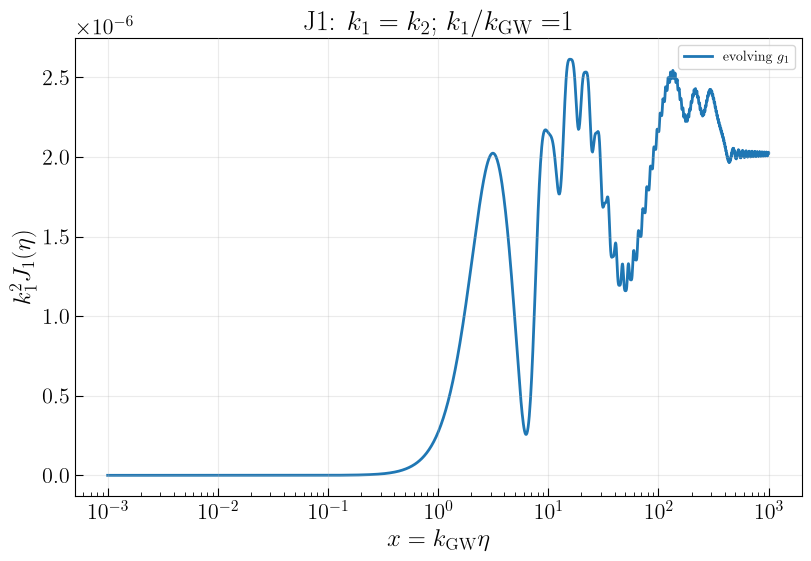

In [67]:
# J1(eta): exact cached Green basis and frozen superhorizon basis.
# Both curves use the same Phi and a choices. Match the frozen
# switches to the main switches in the calculation cell.
result = kernel_analysis_result
frozen = result['frozen']
if frozen is None:
    raise ValueError('Set KERNEL_ANALYSIS_RUN_FROZEN_BASIS=True and rerun the calculation cell.')
if (result['use_transition_phi'] != frozen['use_transition_phi']
        or result['use_transition_a'] != frozen['use_transition_a']):
    raise ValueError('For this overlay, match the frozen Phi/a switches to the main switches.')
x = result['x']  # x = k_GW eta
exact = result['J1_k1_scaled']
frozen_curve = frozen['J1_k1_scaled']
SAVE_FIGURE = True

fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
ax.plot(x, exact, color='C0', label='evolving $g_1$')
#ax.plot(x, frozen_curve, color='C3', linestyle='--', label='frozen $g_1$')
ax.set_xscale('log')
ax.set_xlabel(r'$x=k_{\rm GW}\eta$')
ax.set_ylabel(r'$k_1^2 J_1(\eta)$')
ax.set_title(r'J1: $k_1=k_2$; $k_1/k_{\rm GW}=$' + f'{result["u"]:.3g}')
ax.grid(alpha=0.25)
ax.legend(fontsize=10)
if SAVE_FIGURE:
    figure_path = PROJECT_DIR / 'output' / 'kernel_analysis_J1_model.png'
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=170)
    print('Saved figure:', figure_path)
plt.show()


Saved figure: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\kernel_analysis_J2_model.png


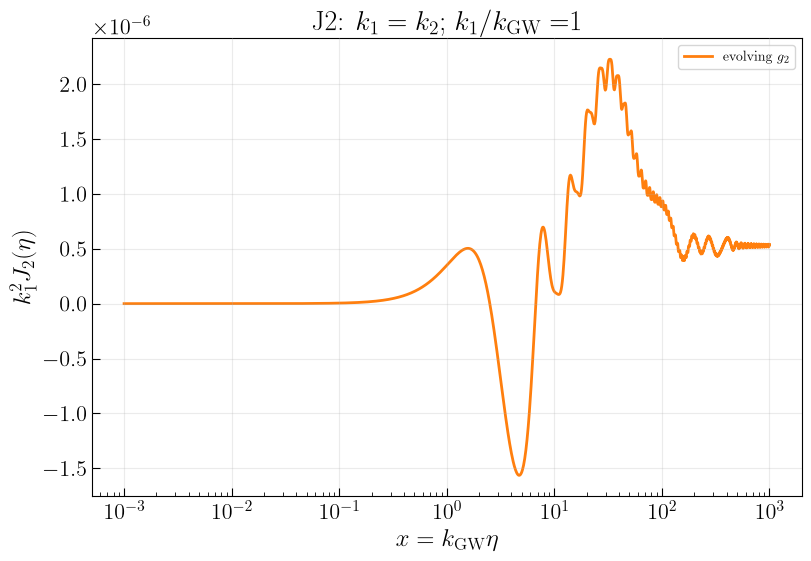

In [68]:
# J2(eta): exact cached Green basis and frozen superhorizon basis.
# Both curves use the same Phi and a choices. Match the frozen
# switches to the main switches in the calculation cell.
result = kernel_analysis_result
frozen = result['frozen']
if frozen is None:
    raise ValueError('Set KERNEL_ANALYSIS_RUN_FROZEN_BASIS=True and rerun the calculation cell.')
if (result['use_transition_phi'] != frozen['use_transition_phi']
        or result['use_transition_a'] != frozen['use_transition_a']):
    raise ValueError('For this overlay, match the frozen Phi/a switches to the main switches.')
x = result['x']  # x = k_GW eta
exact = result['J2_k1_scaled']
frozen_curve = frozen['J2_k1_scaled']
SAVE_FIGURE = True

fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
ax.plot(x, exact, color='C1', label='evolving $g_2$')
#ax.plot(x, frozen_curve, color='C3', linestyle='--', label='frozen $g_2$')
ax.set_xscale('log')
ax.set_xlabel(r'$x=k_{\rm GW}\eta$')
ax.set_ylabel(r'$k_1^2 J_2(\eta)$')
ax.set_title(r'J2: $k_1=k_2$; $k_1/k_{\rm GW}=$' + f'{result["u"]:.3g}')
ax.grid(alpha=0.25)
ax.legend(fontsize=10)
if SAVE_FIGURE:
    figure_path = PROJECT_DIR / 'output' / 'kernel_analysis_J2_model.png'
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=170)
    print('Saved figure:', figure_path)
plt.show()


In [69]:
# Compare J_i for several k_GW at fixed k1/k_GW (with k1=k2).
# Each result has its own x = k_GW eta. The Phi and a switches apply to every curve; source f follows KERNEL_ANALYSIS_USE_TRANSITION_F; Green is analytic radiation.
J_COMPARE_K1_OVER_K_GW = 1.0
J_COMPARE_K_GW_VALUES = np.array([4e6, 1e8, 3e8, 1e9], dtype=float)
J_COMPARE_USE_TRANSITION_PHI = True
J_COMPARE_USE_TRANSITION_F = bool(KERNEL_ANALYSIS_USE_TRANSITION_F)
J_COMPARE_USE_TRANSITION_A = False
J_COMPARE_X_SOURCE = KERNEL_X_EVAL
J_COMPARE_N_TIME = KERNEL_N_TIME

if J_COMPARE_K1_OVER_K_GW < 1.0:
    raise ValueError('Require k1/k_GW >= 1.')
if np.any(~np.isfinite(J_COMPARE_K_GW_VALUES)) or np.any(J_COMPARE_K_GW_VALUES <= 0):
    raise ValueError('All k_GW values must be positive and finite.')
if np.unique(J_COMPARE_K_GW_VALUES).size != J_COMPARE_K_GW_VALUES.size:
    raise ValueError('k_GW values must be distinct.')

j_compare_results = {}
for k_gw in J_COMPARE_K_GW_VALUES:
    k_gw = float(k_gw)
    j_compare_results[k_gw] = kernel_analysis_running_integrals(
        k_gw=k_gw, k1=J_COMPARE_K1_OVER_K_GW * k_gw,
        use_transition_phi=J_COMPARE_USE_TRANSITION_PHI,
        use_transition_f=J_COMPARE_USE_TRANSITION_F,
        use_transition_a=J_COMPARE_USE_TRANSITION_A,
        run_frozen_basis=False,
        x_source=J_COMPARE_X_SOURCE, n_time=J_COMPARE_N_TIME,
    )
print('Computed J1 and J2 for k_GW =', list(j_compare_results))


kernel from J integrals (raw) = 4.88584246e+00
redshift factor = 4.20000000e-05 (enabled=True, eta_f=0.0001)
kernel from J integrals (weighted) = 2.05205383e-04
kernel cache (transition reference, weighted) = 1.52639312e-04
relative difference       = +3.444e-01
kernel from J integrals (raw) = 3.95551700e+00
redshift factor = 4.20000000e-05 (enabled=True, eta_f=0.0001)
kernel from J integrals (weighted) = 1.66131714e-04
kernel cache (transition reference, weighted) = 8.16903976e-05
relative difference       = +1.034e+00
kernel from J integrals (raw) = 1.09755405e+00
redshift factor = 4.19999940e-05 (enabled=True, eta_f=0.0001)
kernel from J integrals (weighted) = 4.60972636e-05
kernel cache (transition reference, weighted) = 1.83540240e-05
relative difference       = +1.512e+00
kernel from J integrals (raw) = 6.87197377e-01
redshift factor = 3.89494330e-05 (enabled=True, eta_f=0.0001)
kernel from J integrals (weighted) = 2.67659482e-05
kernel cache (transition reference, weighted) = 1.

Saved figure: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\kernel_analysis_J1_compare_kGW_model.png


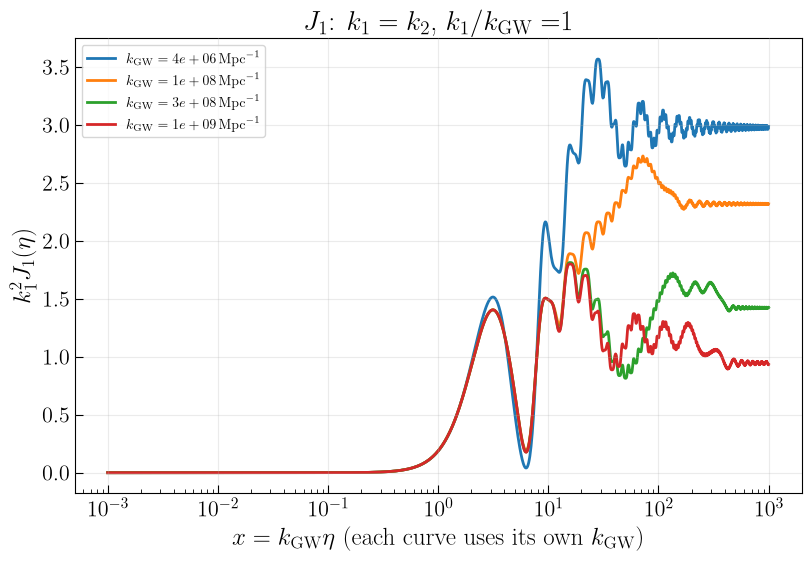

In [70]:
# Compare J1 at fixed k1/k_GW. Select plotted curves here.
# Use result['J1'] instead of result['J1_k1_scaled'] to plot unscaled J1.
J1_PLOT_K_GW_VALUES = list(j_compare_results)  # e.g. [4e6, 1e9]
SAVE_FIGURE = True
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
for k_gw in J1_PLOT_K_GW_VALUES:
    result = j_compare_results[float(k_gw)]
    ax.plot(result['x'], result['J1_k1_scaled'],
            label=rf'$k_{{\rm GW}}={k_gw:.2g}\,{{\rm Mpc}}^{{-1}}$')
ax.set_xscale('log')
ax.set_xlabel(r'$x=k_{\rm GW}\eta$ (each curve uses its own $k_{\rm GW}$)')
ax.set_ylabel(r'$k_1^2 J_1(\eta)$')
ax.set_title(r'$J_1$: $k_1=k_2$, $k_1/k_{\rm GW}=$' + f'{J_COMPARE_K1_OVER_K_GW:g}')
ax.grid(alpha=0.25)
ax.legend(fontsize=10)
if SAVE_FIGURE:
    figure_path = PROJECT_DIR / 'output' / 'kernel_analysis_J1_compare_kGW_model.png'
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=170)
    print('Saved figure:', figure_path)
plt.show()


Saved figure: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\kernel_analysis_J2_compare_kGW_model.png


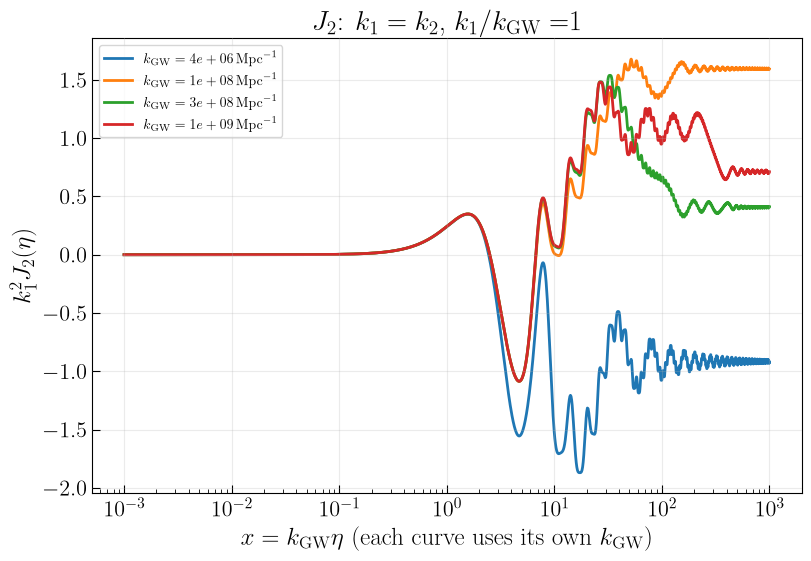

In [71]:
# Compare J2 at fixed k1/k_GW. Select plotted curves here.
# Use result['J2'] instead of result['J2_k1_scaled'] to plot unscaled J2.
J2_PLOT_K_GW_VALUES = list(j_compare_results)  # e.g. [4e6, 1e9]
SAVE_FIGURE = True
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
for k_gw in J2_PLOT_K_GW_VALUES:
    result = j_compare_results[float(k_gw)]
    ax.plot(result['x'], result['J2_k1_scaled'],
            label=rf'$k_{{\rm GW}}={k_gw:.2g}\,{{\rm Mpc}}^{{-1}}$')
ax.set_xscale('log')
ax.set_xlabel(r'$x=k_{\rm GW}\eta$ (each curve uses its own $k_{\rm GW}$)')
ax.set_ylabel(r'$k_1^2 J_2(\eta)$')
ax.set_title(r'$J_2$: $k_1=k_2$, $k_1/k_{\rm GW}=$' + f'{J_COMPARE_K1_OVER_K_GW:g}')
ax.grid(alpha=0.25)
ax.legend(fontsize=10)
if SAVE_FIGURE:
    figure_path = PROJECT_DIR / 'output' / 'kernel_analysis_J2_compare_kGW_model.png'
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=170)
    print('Saved figure:', figure_path)
plt.show()


Saved figure: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\kernel_analysis_I_model.png


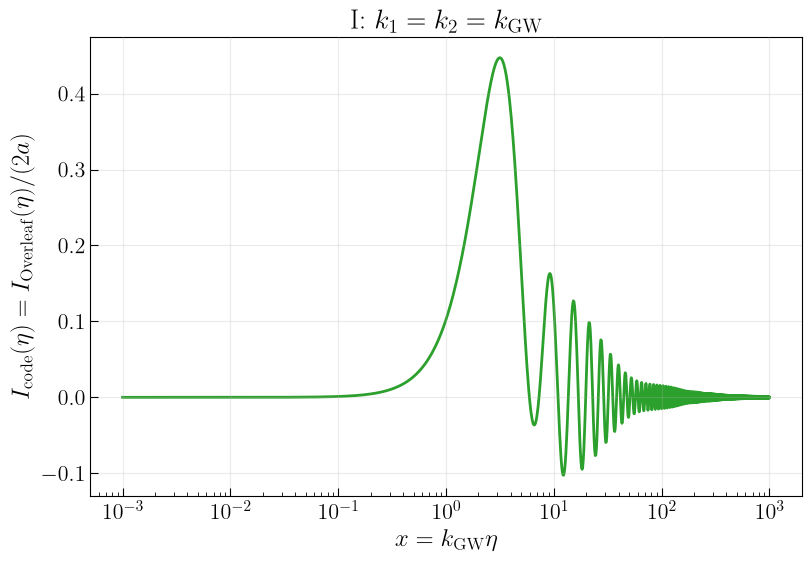

In [72]:
# I(eta): this cell draws only this figure.
result = kernel_analysis_result
x = result['x']  # x = k_GW eta
y = result['response']
SAVE_FIGURE = True

fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
ax.plot(x, y, color='C2')
ax.set_xscale('log')
ax.set_xlabel(r'$x=k_{\rm GW}\eta$')
ax.set_ylabel(r'$I_{\rm code}(\eta)=I_{\rm Overleaf}(\eta)/(2a)$')
ax.set_title(r'I: $k_1=k_2=k_{\rm GW}$')
ax.grid(alpha=0.25)
if SAVE_FIGURE:
    figure_path = PROJECT_DIR / 'output' / 'kernel_analysis_I_model.png'
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=170)
    print('Saved figure:', figure_path)
plt.show()


Saved figure: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\kernel_analysis_phase_average_model.png


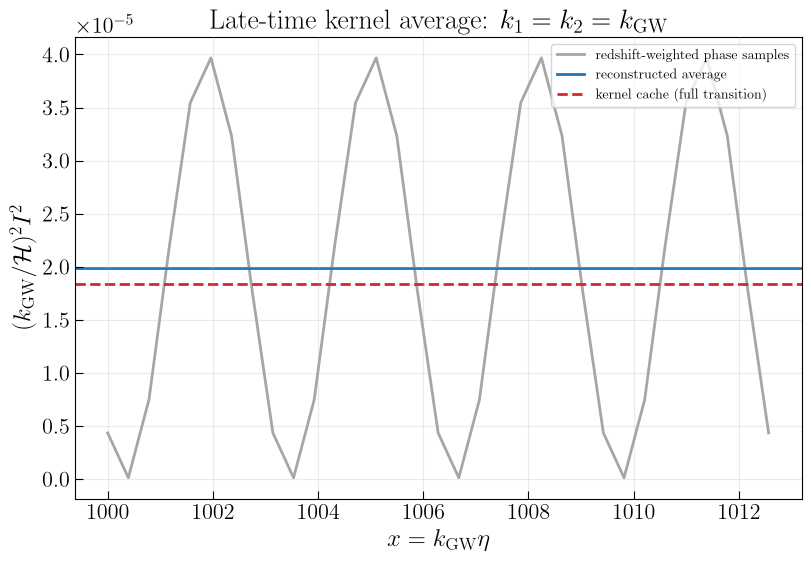

In [73]:
# Late-time phase average and stored kernel cache: one figure.
result = kernel_analysis_result
x_phase = result['x'][-1] + result['phase_offset']
scaled_phase = result['scaled_phase_weighted']
kernel_average = result['kernel_from_integrals']
# Read the full-transition cache here too, so rerunning this plot cell
# always uses the current stored cache for the same (k, s, t).
kernel_cache_path = Path(KERNEL_PATH)
if not kernel_cache_path.exists():
    raise FileNotFoundError(f'Kernel reference cache is missing: {kernel_cache_path}')
cache_eval = load_kernel_interpolator(kernel_cache_path)
cache_value = float(cache_eval(
    result['k_gw'], np.log10(result['s']), result['t'],
)) * result.get('redshift_factor', 1.0)
SAVE_FIGURE = True

fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
ax.plot(x_phase, scaled_phase, color='0.65', label='redshift-weighted phase samples')
ax.axhline(kernel_average, color='C0', label='reconstructed average')
ax.axhline(cache_value, color='C3', linestyle='--',
           label='kernel cache (full transition)')
ax.set_xlabel(r'$x=k_{\rm GW}\eta$')
ax.set_ylabel(r'$(k_{\rm GW}/\mathcal{H})^2 I^2$')
ax.set_title(r'Late-time kernel average: $k_1=k_2=k_{\rm GW}$')
ax.legend(fontsize=10)
ax.grid(alpha=0.25)
if SAVE_FIGURE:
    figure_path = PROJECT_DIR / 'output' / 'kernel_analysis_phase_average_model.png'
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=170)
    print('Saved figure:', figure_path)
plt.show()


## Direct kernel-cache check\n\n

In [74]:
# Direct pointwise comparison: cached cal K(k,u,v) versus kernel_analysis_running_integrals.
# The cache and the running-integrals calculation use the same physical choices:
# transition Phi, transition source f, transition a/H, and the saved transition Green cache.
# Redshift is deliberately disabled here: compare the generation-time cal K itself.
KERNEL_CACHE_COMPARE_POINTS = np.asarray([
    [4.0e6, np.sqrt(3.0) / 2.0, np.sqrt(3.0) / 2.0],
    [1.0e7, np.sqrt(3.0) / 2.0, np.sqrt(3.0) / 2.0],
    [1.0e8, np.sqrt(3.0) / 2.0, np.sqrt(3.0) / 2.0],
], dtype=float)
KERNEL_CACHE_COMPARE_N_TIME = KERNEL_N_TIME
KERNEL_CACHE_COMPARE_X_SOURCE = KERNEL_X_EVAL
KERNEL_CACHE_COMPARE_INCLUDE_REDSHIFT_FACTOR = False
KERNEL_CACHE_COMPARE_USE_TRANSITION_PHI = True
KERNEL_CACHE_COMPARE_USE_TRANSITION_F = True
KERNEL_CACHE_COMPARE_USE_TRANSITION_A = True

if KERNEL_CACHE_COMPARE_POINTS.ndim != 2 or KERNEL_CACHE_COMPARE_POINTS.shape[1] != 3:
    raise ValueError('Each comparison point must be [k_GW, u, v].')
if np.any(KERNEL_CACHE_COMPARE_POINTS[:, 0] <= 0.0):
    raise ValueError('All comparison k_GW values must be positive.')
if np.any(KERNEL_CACHE_COMPARE_POINTS[:, 1:] <= 0.0):
    raise ValueError('All comparison u and v values must be positive.')
if np.any(np.sum(KERNEL_CACHE_COMPARE_POINTS[:, 1:], axis=1) <= 1.0):
    raise ValueError('Every comparison point must satisfy u+v>1.')
if not (KERNEL_CACHE_COMPARE_USE_TRANSITION_PHI
        and KERNEL_CACHE_COMPARE_USE_TRANSITION_F
        and KERNEL_CACHE_COMPARE_USE_TRANSITION_A):
    raise ValueError('This direct check is intended to match the full-transition cache.')
if KERNEL_CACHE_COMPARE_INCLUDE_REDSHIFT_FACTOR:
    raise ValueError('Disable redshift for a direct generation-time cal K comparison.')

_kernel_compare_eval = load_kernel_interpolator(KERNEL_PATH)
_kernel_compare_green = load_green_cache()
_kernel_compare_phi = (
    phi_cache if phi_cache is not None else
    PiecewisePhiTransfer(cache_dir=PHI_CACHE_DIR, ignore_metadata=True)
)
_kernel_compare_rows = []
for k_gw, u_point, v_point in KERNEL_CACHE_COMPARE_POINTS:
    s_point = (u_point + v_point - 1.0) / np.sqrt(2.0)
    t_point = (u_point - v_point) / np.sqrt(2.0)
    cache_value = float(_kernel_compare_eval(k_gw, np.log10(s_point), t_point))
    running = kernel_analysis_running_integrals(
        u=float(u_point), v=float(v_point), k=float(k_gw),
        use_transition_phi=True,
        use_transition_f=True,
        use_transition_a=True,
        include_redshift_factor=False,
        run_frozen_basis=False,
        green_cache=_kernel_compare_green,
        phi_transfer=_kernel_compare_phi,
        x_source=KERNEL_CACHE_COMPARE_X_SOURCE,
        n_time=KERNEL_CACHE_COMPARE_N_TIME,
    )
    analysis_value = float(running['kernel_from_integrals_raw'])
    relative_difference = analysis_value / cache_value - 1.0
    _kernel_compare_rows.append([
        float(k_gw), float(u_point), float(v_point),
        cache_value, analysis_value, relative_difference,
    ])

kernel_cache_compare_results = np.asarray(_kernel_compare_rows, dtype=float)
print('Direct cal K comparison (no today redshift factor):')
print(' columns: k_GW, u, v, cache, running_integrals, (running/cache - 1)')
for row in kernel_cache_compare_results:
    print(
        f'k={row[0]:.6e}, u={row[1]:.6f}, v={row[2]:.6f}: '
        f'cache={row[3]:.8e}, running={row[4]:.8e}, '
        f'relative={row[5]:+.3e}'
    )


Loaded Green chunks: ['23', '310']
kernel from J integrals (raw) = 8.65358025e+01
redshift factor = 1.00000000e+00 (enabled=False, eta_f=0.0001)
kernel from J integrals (weighted) = 8.65358025e+01
kernel cache (transition reference, weighted) = 8.64997214e+01
relative difference       = +4.171e-04
kernel from J integrals (raw) = 1.32075401e+01
redshift factor = 1.00000000e+00 (enabled=False, eta_f=0.0001)
kernel from J integrals (weighted) = 1.32075401e+01
kernel cache (transition reference, weighted) = 1.32075316e+01
relative difference       = +6.485e-07
kernel from J integrals (raw) = 3.56555354e+00
redshift factor = 1.00000000e+00 (enabled=False, eta_f=0.0001)
kernel from J integrals (weighted) = 3.56555354e+00
kernel cache (transition reference, weighted) = 3.55893583e+00
relative difference       = +1.859e-03
Direct cal K comparison (no today redshift factor):
 columns: k_GW, u, v, cache, running_integrals, (running/cache - 1)
k=4.000000e+06, u=0.866025, v=0.866025: cache=8.64997

Saved figure: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\kernel_cache_vs_analysis_pointwise.png


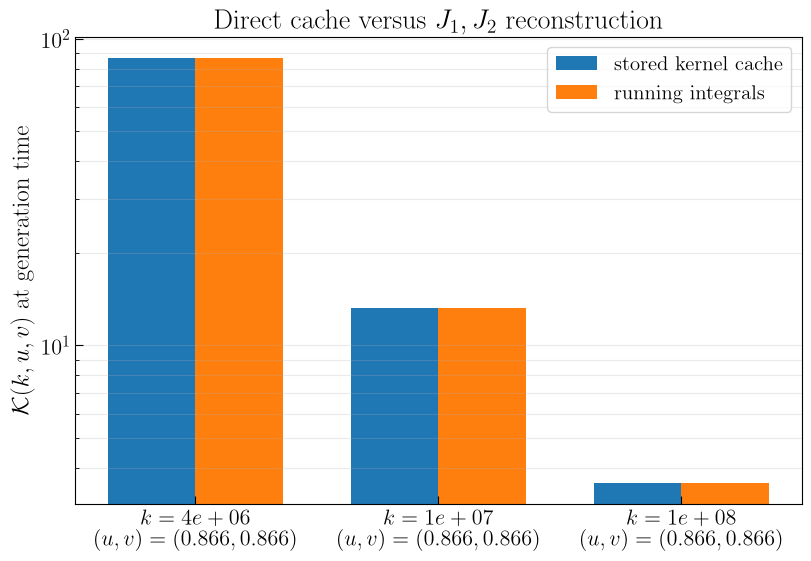

In [75]:
# Plot the pointwise cache-vs-analysis comparison from the preceding cell.
# Edit KERNEL_CACHE_COMPARE_PLOT_ROWS to choose which calculated points to show.
KERNEL_CACHE_COMPARE_PLOT_ROWS = np.arange(len(kernel_cache_compare_results))
SAVE_FIGURE = True

rows = kernel_cache_compare_results[np.asarray(KERNEL_CACHE_COMPARE_PLOT_ROWS, dtype=int)]
labels = [f'$k={row[0]:.2g}$\n$(u,v)=({row[1]:.3g},{row[2]:.3g})$' for row in rows]
x_plot = np.arange(len(rows), dtype=float)
width = 0.36
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
ax.bar(x_plot - width / 2.0, rows[:, 3], width, label='stored kernel cache')
ax.bar(x_plot + width / 2.0, rows[:, 4], width, label='running integrals')
ax.set_yscale('log')
ax.set_xticks(x_plot, labels)
ax.set_ylabel(r'$\mathcal K(k,u,v)$ at generation time')
ax.set_title(r'Direct cache versus $J_1,J_2$ reconstruction')
ax.grid(alpha=0.25, axis='y', which='both')
ax.legend()
if SAVE_FIGURE:
    figure_path = PROJECT_DIR / 'output' / 'kernel_cache_vs_analysis_pointwise.png'
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=180)
    print('Saved figure:', figure_path)
plt.show()


In [ ]:
# Coarse scan of the late-time kernel endpoint for k1=k2=u*kGW.
# The four curves select transition/radiation Phi and a independently.
# f follows KERNEL_ANALYSIS_USE_TRANSITION_F; Green is analytic radiation.
# Results are checkpointed in an npz file so the scan can be
# reused without repeating the integrations.

from itertools import product
import sys

# Non-uniform coarse scan: sparse on the left, dense across the rapid
# oscillation region on the right. This gives 129 unique points in total.
KERNEL_ENDPOINT_SCAN_K_GRID = np.unique(np.concatenate([
    np.geomspace(1.0e4, 1.0e8, 35),
    np.geomspace(1.0e8, 1.0e10, 95),
]))
KERNEL_ENDPOINT_SCAN_N_TIME = 2000
KERNEL_ENDPOINT_SCAN_X_SOURCE = KERNEL_X_EVAL
KERNEL_ENDPOINT_SCAN_FORCE = False
KERNEL_ENDPOINT_SCAN_USE_TRANSITION_F = bool(KERNEL_ANALYSIS_USE_TRANSITION_F)
KERNEL_ENDPOINT_SCAN_INCLUDE_REDSHIFT_FACTOR = True
KERNEL_ENDPOINT_SCAN_REDSHIFT_ETA_F = 1e-4
KERNEL_ENDPOINT_SCAN_U = 0.9  # u=v=k1/kGW; choose u>=1/2.


def _kernel_endpoint_scan_label(use_phi, use_a):
    return (
        f"Phi={'transition' if use_phi else 'radiation'}, "
        f"a={'transition' if use_a else 'radiation'}"
    )


def _kernel_endpoint_scan_transfer_objects():
    """Load two Phi objects and the analytic radiation Green basis once."""
    phi_objects = {
        True: phi_cache if phi_cache is not None else PiecewisePhiTransfer(
            cache_dir=PHI_CACHE_DIR, ignore_metadata=True
        ),
        False: RadiationPhiTransfer(),
    }
    return phi_objects, RadiationGreen()


def compute_kernel_endpoint_scan(
    k_grid=KERNEL_ENDPOINT_SCAN_K_GRID,
    n_time=KERNEL_ENDPOINT_SCAN_N_TIME,
    x_source=KERNEL_ENDPOINT_SCAN_X_SOURCE,
    use_transition_f=KERNEL_ENDPOINT_SCAN_USE_TRANSITION_F,
    include_redshift_factor=True, redshift_eta_f=1e-4,
    u=KERNEL_ENDPOINT_SCAN_U,
    cache_path=None,
    force=False,
):
    """Return the final phase-averaged kernel for all four (Phi, a) combinations."""
    k_grid = np.asarray(k_grid, dtype=float)
    if k_grid.ndim != 1 or np.any(k_grid <= 0.0) or np.any(np.diff(k_grid) <= 0.0):
        raise ValueError('k_grid must be a strictly increasing positive one-dimensional array.')
    use_transition_f = bool(use_transition_f)
    include_redshift_factor = bool(include_redshift_factor)
    redshift_eta_f = float(redshift_eta_f)
    u = float(u)
    if not np.isfinite(u) or u < 0.5:
        raise ValueError('Require finite u=k1/kGW>=1/2.')
    if cache_path is None:
        cache_path = DATA_DIR / (
            'kernel_endpoint_scan_phi_a_f_'
            + ('transition' if use_transition_f else 'radiation')
            + '_green_radiation_redshift_'
            + ('on' if include_redshift_factor else 'off')
            + '_etaf_' + format(redshift_eta_f, '.6g').replace('.', 'p')
            + '_u_' + format(u, '.17g').replace('.', 'p')
            + '_v3.npz'
        )
    cache_path = Path(cache_path)
    combination_order = np.asarray(
        list(product((True, False), (True, False))), dtype=bool
    )
    # Order is Phi, a; the first row is the full transition case.
    if cache_path.exists() and not force:
        try:
            with np.load(cache_path, allow_pickle=False) as cached:
                cached_k = np.asarray(cached['k_grid'], dtype=float)
                cached_switches = np.asarray(cached['switches'], dtype=bool)
                cached_values = np.asarray(cached['kernel_endpoint'], dtype=float)
                compatible = (
                    np.array_equal(cached_k, k_grid)
                    and np.array_equal(cached_switches, combination_order)
                    and cached_values.shape == (len(combination_order), len(k_grid))
                    and np.all(np.isfinite(cached_values))
                    and int(cached['n_time']) == int(n_time)
                    and np.isclose(float(cached['x_source']), float(x_source))
                    and bool(cached['use_transition_f']) == use_transition_f
                    and bool(cached['include_redshift_factor']) == include_redshift_factor
                    and np.isclose(float(cached['redshift_eta_f']), redshift_eta_f)
                    and str(cached['green']) == 'radiation'
                    and float(cached['u']) == u
                )
            if compatible:
                print('Reusing endpoint scan cache:', cache_path)
                return {
                    'k_grid': cached_k,
                    'switches': cached_switches,
                    'kernel_endpoint': cached_values,
                    'labels': [_kernel_endpoint_scan_label(*row) for row in cached_switches],
                    'cache_path': cache_path,
                    'use_transition_f': use_transition_f,
                    'include_redshift_factor': include_redshift_factor,
                    'redshift_eta_f': redshift_eta_f,
                    'u': u,
                }
        except (OSError, KeyError, ValueError):
            pass

    phi_objects, radiation_green = _kernel_endpoint_scan_transfer_objects()
    values = np.empty((len(combination_order), len(k_grid)), dtype=float)
    for ic, (use_phi, use_a) in enumerate(combination_order):
        label = _kernel_endpoint_scan_label(use_phi, use_a)
        print(f'Endpoint scan {ic + 1}/{len(combination_order)}: {label}')
        for ik, k_gw in enumerate(k_grid):
            result = kernel_analysis_running_integrals(
                k_gw=float(k_gw),
                k1=u * float(k_gw),
                x_source=float(x_source),
                n_time=int(n_time),
                use_transition_phi=bool(use_phi),
                use_transition_f=use_transition_f,
                use_transition_a=bool(use_a),
                phi_transfer=phi_objects[bool(use_phi)],
                green_cache=radiation_green,
                run_frozen_basis=False,
            )
            values[ic, ik] = result['kernel_from_integrals']
            print(f'  kGW={k_gw:.3e}: K_end={values[ic, ik]:.8e}')

    cache_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        cache_path,
        k_grid=k_grid,
        switches=combination_order,
        kernel_endpoint=values,
        n_time=int(n_time),
        x_source=float(x_source),
        use_transition_f=use_transition_f,
        include_redshift_factor=include_redshift_factor,
        redshift_eta_f=redshift_eta_f,
        green='radiation',
        u=u,
    )
    print('Saved endpoint scan cache:', cache_path)
    return {
        'k_grid': k_grid,
        'switches': combination_order,
        'kernel_endpoint': values,
        'labels': [_kernel_endpoint_scan_label(*row) for row in combination_order],
        'cache_path': cache_path,
        'use_transition_f': use_transition_f,
        'include_redshift_factor': include_redshift_factor,
        'redshift_eta_f': redshift_eta_f,
        'u': u,
    }


kernel_endpoint_scan = compute_kernel_endpoint_scan(
    use_transition_f=KERNEL_ENDPOINT_SCAN_USE_TRANSITION_F,
    include_redshift_factor=KERNEL_ENDPOINT_SCAN_INCLUDE_REDSHIFT_FACTOR,
    redshift_eta_f=KERNEL_ENDPOINT_SCAN_REDSHIFT_ETA_F,
    u=KERNEL_ENDPOINT_SCAN_U,
    force=KERNEL_ENDPOINT_SCAN_FORCE,
)


Saved figure: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\kernel_endpoint_scan_phi_a_f_transition_green_radiation_u_0p90000000000000002_redshift_on.png


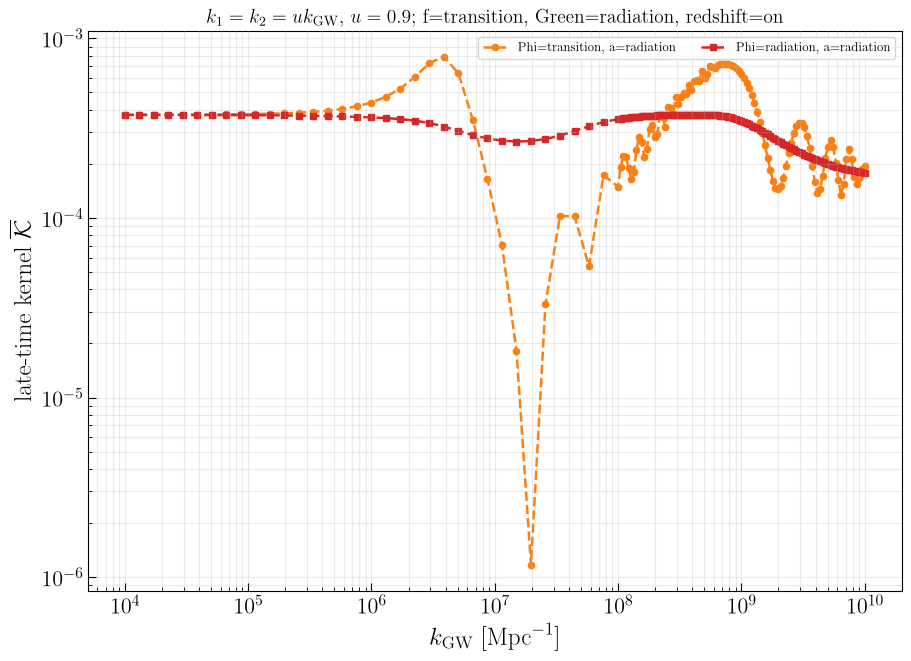

In [77]:
# Plot 1: late-time kernel. One cell creates exactly one figure.
# All four combinations are computed; edit PLOT_CASES to choose displayed lines.
# Each tuple is (transition Phi?, transition a?). f follows the calculation cell.
PLOT_CASES = [
    (True, False),
    (False, False),
    # (True, True),
    # (False, True),
]
SAVE_PLOT = True
OUTPUT_FILENAME = (
    'kernel_endpoint_scan_phi_a_f_'
    + ('transition' if kernel_endpoint_scan['use_transition_f'] else 'radiation')
    + '_green_radiation_u_'
    + format(kernel_endpoint_scan['u'], '.17g').replace('.', 'p')
    + '_redshift_' + ('on' if kernel_endpoint_scan['include_redshift_factor'] else 'off') + '.png'
)
if bool(KERNEL_ANALYSIS_USE_TRANSITION_F) != kernel_endpoint_scan['use_transition_f']:
    raise RuntimeError('f switch changed; rerun the coarse-scan calculation cell before plotting.')
if float(KERNEL_ENDPOINT_SCAN_U) != kernel_endpoint_scan['u']:
    raise RuntimeError('u changed; rerun the coarse-scan calculation cell before plotting.')
if bool(KERNEL_ENDPOINT_SCAN_INCLUDE_REDSHIFT_FACTOR) != kernel_endpoint_scan['include_redshift_factor']:
    raise RuntimeError('redshift switch changed; rerun the coarse-scan calculation cell before plotting.')

k_grid = kernel_endpoint_scan['k_grid']
kernel_values = kernel_endpoint_scan['kernel_endpoint']
switch_order = [tuple(row) for row in kernel_endpoint_scan['switches']]

fig, ax = plt.subplots(figsize=(9, 6.5), constrained_layout=True)
for case in PLOT_CASES:
    case = tuple(case)
    if case not in switch_order:
        raise ValueError(f'Unknown Phi/a combination: {case}')
    i = switch_order.index(case)
    ax.plot(
        k_grid, kernel_values[i],
        color=plt.get_cmap('tab10')(i),
        linestyle='-' if case[1] else '--',
        marker='o' if case[0] else 's',
        markersize=4.5, linewidth=1.8,
        label=kernel_endpoint_scan['labels'][i],
    )
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$k_{\rm GW}\;[\mathrm{Mpc}^{-1}]$')
ax.set_ylabel(r'late-time kernel $\overline{\mathcal K}$')
f_label = 'transition' if kernel_endpoint_scan['use_transition_f'] else 'radiation'
redshift_label = 'on' if kernel_endpoint_scan['include_redshift_factor'] else 'off'
ax.set_title(r'$k_1=k_2=u k_{\rm GW}$, '
             + rf'$u={kernel_endpoint_scan["u"]:.3g}$; '
             + f'f={f_label}, Green=radiation, redshift={redshift_label}', fontsize=14)
ax.grid(alpha=0.25, which='both')
ax.legend(fontsize=9, ncol=2)
if SAVE_PLOT:
    figure_path = PROJECT_DIR / 'output' / OUTPUT_FILENAME
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=180)
    print('Saved figure:', figure_path)
plt.show()


In [ ]:
# Physical equal-momentum kernel: transition Phi, f, Green, a and conformal H.
# Both a choices are computed on the same grid; plotting stays in separate cells.
from inspect import signature
if 'cache_eval' not in signature(kernel_analysis_running_integrals).parameters:
    raise RuntimeError('Rerun the Running source integrals definition cell, then this scan cell.')

KERNEL_UV_COMPARE_U = np.array([1.0])
KERNEL_UV_COMPARE_UV = np.column_stack((KERNEL_UV_COMPARE_U, KERNEL_UV_COMPARE_U))
KERNEL_UV_COMPARE_K_GRID = np.unique(np.concatenate([
    np.geomspace(1.0e4, 1.0e6, 20),
    np.geomspace(1.0e6, 1.0e8, 50),
    np.geomspace(1.0e8, 1.0e10, 95),
]))
KERNEL_UV_COMPARE_N_TIME = 4000
KERNEL_UV_COMPARE_X_SOURCE = KERNEL_X_EVAL
KERNEL_UV_COMPARE_FORCE = False
KERNEL_UV_COMPARE_USE_TRANSITION_F = True
KERNEL_UV_COMPARE_USE_TRANSITION_A = True
KERNEL_UV_COMPARE_INCLUDE_REDSHIFT_FACTOR = True
KERNEL_UV_COMPARE_REDSHIFT_ETA_F = 1e-4
KERNEL_UV_COMPARE_GREEN = 'transition'
KERNEL_UV_COMPARE_CACHE = DATA_DIR / (
    'kernel_phi_a_redshift_check_f_'
    + ('transition' if KERNEL_UV_COMPARE_USE_TRANSITION_F else 'radiation')
    + '_green_' + KERNEL_UV_COMPARE_GREEN + '_v1.npz'
)
phi_transition = phi_cache if phi_cache is not None else PiecewisePhiTransfer(
    cache_dir=PHI_CACHE_DIR, ignore_metadata=True
)
if KERNEL_UV_COMPARE_GREEN not in ('radiation', 'transition'):
    raise ValueError('Green must be radiation or transition.')
green_for_comparison = (RadiationGreen() if KERNEL_UV_COMPARE_GREEN == 'radiation'
                        else load_green_cache())
kernel_uv_cache_eval = load_kernel_interpolator(KERNEL_PATH)
kernel_redshift_compare = compute_a_redshift_comparison(
    KERNEL_UV_COMPARE_K_GRID, KERNEL_UV_COMPARE_UV,
    compute_kernel=kernel_analysis_running_integrals,
    phi_transfer=phi_transition, green_cache=green_for_comparison,
    cache_eval=kernel_uv_cache_eval,
    redshift_factor=today_redshift_factor,
    cache_path=KERNEL_UV_COMPARE_CACHE,
    n_time=KERNEL_UV_COMPARE_N_TIME, x_source=KERNEL_UV_COMPARE_X_SOURCE,
    eta_f=KERNEL_UV_COMPARE_REDSHIFT_ETA_F,
    use_transition_f=KERNEL_UV_COMPARE_USE_TRANSITION_F,
    green_name=KERNEL_UV_COMPARE_GREEN,
    phase_periods=KERNEL_PHASE_PERIODS, phase_samples=KERNEL_PHASE_SAMPLES,
    force=KERNEL_UV_COMPARE_FORCE,
)
kernel_uv_compare_values = kernel_redshift_compare['kernel_raw'][
    0 if KERNEL_UV_COMPARE_USE_TRANSITION_A else 1
].copy()
if KERNEL_UV_COMPARE_INCLUDE_REDSHIFT_FACTOR:
    kernel_uv_compare_values *= kernel_redshift_compare['end_factor']
kernel_uv_compare_settings = {
    'use_transition_phi': True,
    'use_transition_f': KERNEL_UV_COMPARE_USE_TRANSITION_F,
    'use_transition_a': KERNEL_UV_COMPARE_USE_TRANSITION_A,
    'include_redshift_factor': KERNEL_UV_COMPARE_INCLUDE_REDSHIFT_FACTOR,
    'redshift_eta_f': KERNEL_UV_COMPARE_REDSHIFT_ETA_F,
    'green': KERNEL_UV_COMPARE_GREEN,
}
print('Kernel scan settings:', kernel_uv_compare_settings)


Saved figure: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\omega_integrand_transition_phi_equal_uv_f_transition_a_transition_green_transition_redshift_on.png


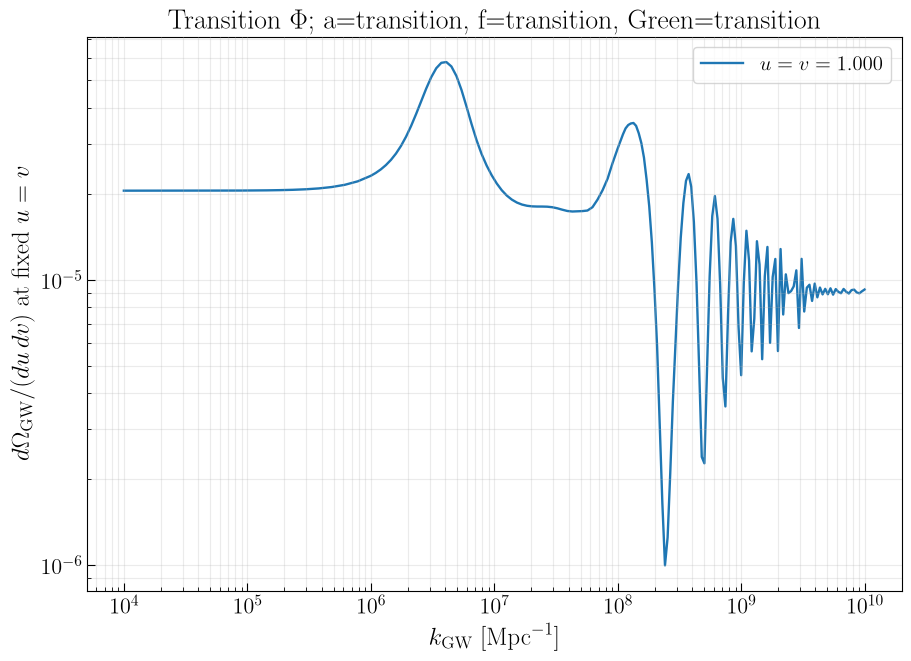

In [79]:
# Plot the flat-spectrum local uv integrand for selected u=v values.
# One figure per cell. Edit the indices to choose the displayed curves.
KERNEL_UV_COMPARE_PLOT_INDICES = list(range(len(KERNEL_UV_COMPARE_UV)))
KERNEL_UV_COMPARE_PLOT_P_ZETA = 1.0
SAVE_PLOT = True
OUTPUT_FILENAME = (
    'omega_integrand_transition_phi_equal_uv_f_'
    + ('transition' if KERNEL_UV_COMPARE_USE_TRANSITION_F else 'radiation')
    + '_a_' + ('transition' if KERNEL_UV_COMPARE_USE_TRANSITION_A else 'radiation')
    + '_green_' + KERNEL_UV_COMPARE_GREEN + '_redshift_'
    + ('on' if KERNEL_UV_COMPARE_INCLUDE_REDSHIFT_FACTOR else 'off') + '.png'
)
if globals().get('kernel_uv_compare_settings') != {
    'use_transition_phi': True, 'use_transition_f': KERNEL_UV_COMPARE_USE_TRANSITION_F,
    'use_transition_a': KERNEL_UV_COMPARE_USE_TRANSITION_A,
    'include_redshift_factor': KERNEL_UV_COMPARE_INCLUDE_REDSHIFT_FACTOR,
    'redshift_eta_f': KERNEL_UV_COMPARE_REDSHIFT_ETA_F,
    'green': KERNEL_UV_COMPARE_GREEN,
}:
    raise RuntimeError('Rerun the equal-u scan calculation cell before plotting.')

fig, ax = plt.subplots(figsize=(9, 6.5), constrained_layout=True)
for ip in KERNEL_UV_COMPARE_PLOT_INDICES:
    u_plot, v_plot = KERNEL_UV_COMPARE_UV[ip]
    # Omega_GW = (2/3) integral du dv P(u,v) K P_zeta(ku) P_zeta(kv).
    # No factor of 2: that factor applies only after folding the uv plane to t>=0.
    uv_prefactor = ((2.0 / 3.0) * float(projection_factor(u_plot, v_plot))
                    * KERNEL_UV_COMPARE_PLOT_P_ZETA**2)
    ax.plot(
        KERNEL_UV_COMPARE_K_GRID,
        uv_prefactor * kernel_uv_compare_values[ip],
        linewidth=1.7,
        label=rf'$u=v={u_plot:.3f}$',
    )
ax.set_xscale('log')
#ax.set_yscale('log')
ax.set_xlabel(r'$k_{\mathrm{GW}}\;[\mathrm{Mpc}^{-1}]$')
ax.set_ylabel(r'$d\Omega_{\rm GW}/(du\,dv)$ at fixed $u=v$')
f_label = 'transition' if KERNEL_UV_COMPARE_USE_TRANSITION_F else 'radiation'
a_label = 'transition' if KERNEL_UV_COMPARE_USE_TRANSITION_A else 'radiation'
ax.set_title(r'Transition $\Phi$; ' + f'a={a_label}, f={f_label}, Green={KERNEL_UV_COMPARE_GREEN}')
ax.grid(alpha=0.25, which='both')
ax.legend()
ax.set_yscale('log')
if SAVE_PLOT:
    figure_path = PROJECT_DIR / 'output' / OUTPUT_FILENAME
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=180)
    print('Saved figure:', figure_path)
plt.show()


C:\Users\23695\AppData\Local\Temp\ipykernel_6636\1186851107.py:51: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


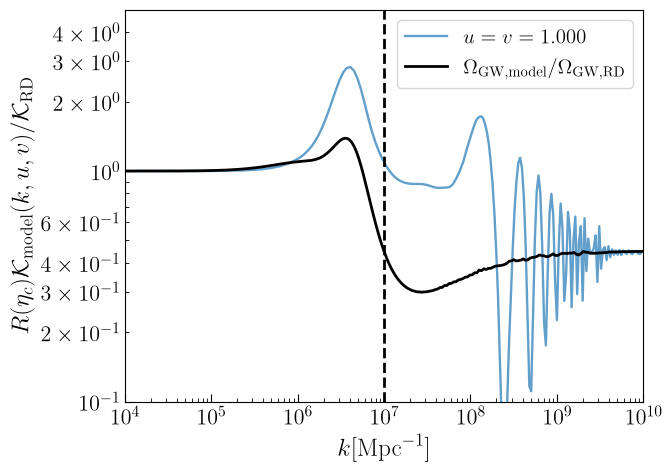

In [87]:
# Plot normalized local uv integrands against the saved flat-spectrum curve.
# One figure per cell. Edit the indices to choose the displayed curves.
KERNEL_UV_COMPARE_PLOT_INDICES = list(range(len(KERNEL_UV_COMPARE_UV)))
KERNEL_UV_COMPARE_PLOT_P_ZETA = 1.0
SAVE_PLOT = True
OUTPUT_FILENAME = (
    'omega_integrand_transition_phi_equal_uv_f_'
    + ('transition' if KERNEL_UV_COMPARE_USE_TRANSITION_F else 'radiation')
    + '_normalized_a_' + ('transition' if KERNEL_UV_COMPARE_USE_TRANSITION_A else 'radiation')
    + '_green_' + KERNEL_UV_COMPARE_GREEN + '.png'
)
if globals().get('kernel_uv_compare_settings') != {
    'use_transition_phi': True, 'use_transition_f': KERNEL_UV_COMPARE_USE_TRANSITION_F,
    'use_transition_a': KERNEL_UV_COMPARE_USE_TRANSITION_A,
    'include_redshift_factor': KERNEL_UV_COMPARE_INCLUDE_REDSHIFT_FACTOR,
    'redshift_eta_f': KERNEL_UV_COMPARE_REDSHIFT_ETA_F,
    'green': KERNEL_UV_COMPARE_GREEN,
}:
    raise RuntimeError('Rerun the equal-u scan calculation cell before plotting.')

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
for ip in KERNEL_UV_COMPARE_PLOT_INDICES:
    u_plot, v_plot = KERNEL_UV_COMPARE_UV[ip]
    # Omega_GW = (2/3) integral du dv P(u,v) K P_zeta(ku) P_zeta(kv).
    # No factor of 2: that factor applies only after folding the uv plane to t>=0.
    uv_prefactor = ((2.0 / 3.0) * float(projection_factor(u_plot, v_plot))
                    * KERNEL_UV_COMPARE_PLOT_P_ZETA**2)
    ax.plot(
        KERNEL_UV_COMPARE_K_GRID,
        uv_prefactor * kernel_uv_compare_values[ip]/ (uv_prefactor * kernel_uv_compare_values[ip][0]),
        linewidth=1.7,
        label=rf'$u=v={u_plot:.3f}$', alpha=0.7
    )
data = np.loadtxt(DATA_DIR / 'flat_model.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.plot(kspan,OmegaGW/OmegaGW[0],label=r'$\Omega_{\rm GW,model}/\Omega_{\rm GW,RD}$',color='black')

plt.axvline(x=1e7,color='black',ls='--')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$k[\mathrm{Mpc}^{-1}]$')
ax.set_ylim(0.1,5)
ax.set_xlim(1e4,1e10)
ax.set_ylabel(r'$R(\eta_c)\mathcal{K}_{\rm model}(k,u,v)/\mathcal{K}_{\rm RD}$')
f_label = 'transition' if KERNEL_UV_COMPARE_USE_TRANSITION_F else 'radiation'
a_label = 'transition' if KERNEL_UV_COMPARE_USE_TRANSITION_A else 'radiation'
#ax.set_title(r'Transition $\Phi$; ' + f'a={a_label}, f={f_label}, Green={KERNEL_UV_COMPARE_GREEN}')
#ax.grid(alpha=0.25, which='both')
ax.legend()
plt.tight_layout()
plt.savefig('plot/kernel_spectrum.pdf')
plt.show()


### Test: scale factor in the source integral versus redshift from $1/k$

Both curves below use transition $\Phi$ and radiation $f$, Green. 
Solid: transition $a$ inside/outside the integral and transition $\mathcal H$ in the kernel, 
then multiply by $R(\eta_c\to0)$. Dashed: radiation $a,\mathcal H$, 
then multiply by $R(1/k\to0)$ evaluated on the transition background. 
Each curve is normalized at the same smallest $k$. 
Equality would require the two styles of each color to overlap.


a=transition, u=1, v=1: 163 points
a=radiation, u=1, v=1: 163 points


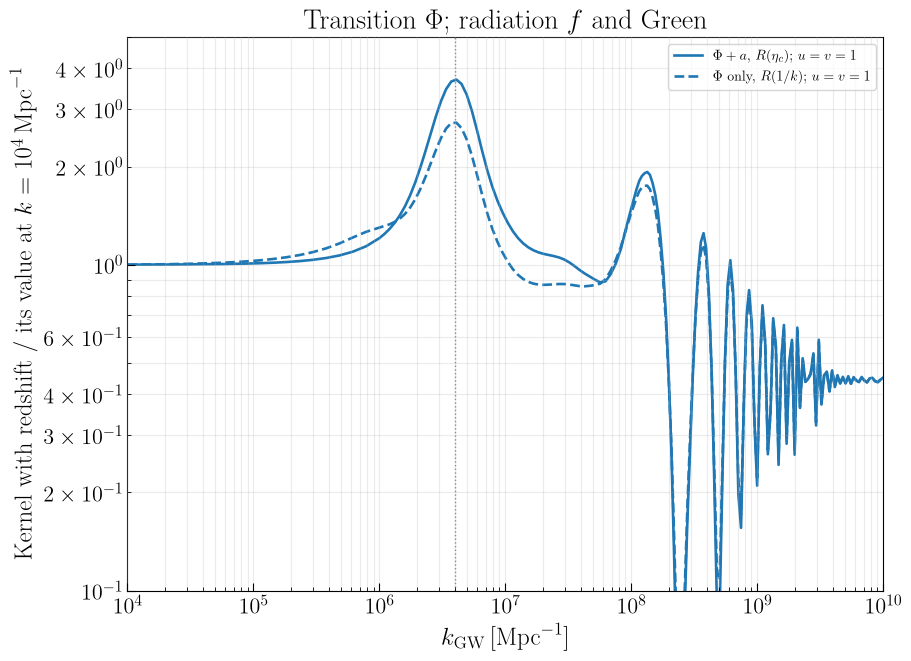

In [81]:
# Matched-redshift check: one figure; edit u indices and line settings here.
REDSHIFT_CHECK_PLOT_INDICES = list(range(len(KERNEL_UV_COMPARE_UV)))
SAVE_REDSHIFT_CHECK = True
# Keep this radiation f/Green control independent of the physical scan above.
redshift_check_compare = compute_a_redshift_comparison(
    KERNEL_UV_COMPARE_K_GRID, KERNEL_UV_COMPARE_UV,
    compute_kernel=kernel_analysis_running_integrals,
    phi_transfer=phi_transition, green_cache=RadiationGreen(),
    cache_eval=kernel_uv_cache_eval, redshift_factor=today_redshift_factor,
    cache_path=DATA_DIR / 'kernel_phi_a_redshift_check_f_radiation_green_radiation_v1.npz',
    n_time=KERNEL_UV_COMPARE_N_TIME, x_source=KERNEL_UV_COMPARE_X_SOURCE,
    eta_f=KERNEL_UV_COMPARE_REDSHIFT_ETA_F,
    use_transition_f=False, green_name='radiation',
    phase_periods=KERNEL_PHASE_PERIODS, phase_samples=KERNEL_PHASE_SAMPLES,
    force=KERNEL_UV_COMPARE_FORCE,
)
k_check = redshift_check_compare['k_grid']
fig, ax = plt.subplots(figsize=(9, 6.5), constrained_layout=True)
for ip in REDSHIFT_CHECK_PLOT_INDICES:
    u_check, v_check = redshift_check_compare['uv_values'][ip]
    color = plt.get_cmap('tab10')(ip)
    a_today = redshift_check_compare['kernel_a_today'][ip]
    phi_entry_today = redshift_check_compare['kernel_phi_entry_today'][ip]
    ax.plot(k_check, a_today / a_today[0], color=color, lw=1.9,
            label=rf'$\Phi+a$, $R(\eta_c)$; $u=v={u_check:g}$')
    ax.plot(k_check, phi_entry_today / phi_entry_today[0], color=color, ls='--', lw=1.9,
            label=rf'$\Phi$ only, $R(1/k)$; $u=v={u_check:g}$')
ax.axvline(4e6, color='gray', ls=':', lw=1.)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e4, 1e10)
ax.set_ylim(0.1, 5)
ax.set_xlabel(r'$k_{\rm GW}\,[\mathrm{Mpc}^{-1}]$')
ax.set_ylabel(r'Kernel with redshift / its value at $k=10^4\,\mathrm{Mpc}^{-1}$')
ax.set_title(r'Transition $\Phi$; radiation $f$ and Green')
ax.grid(alpha=0.25, which='both')
ax.legend(fontsize=10)
if SAVE_REDSHIFT_CHECK:
    fig.savefig(PROJECT_DIR / 'output' / 'kernel_a_vs_entry_redshift.png', dpi=180)
plt.show()


In [82]:
# Direct peak check: toggle one ingredient at a time; all values are IR normalized.
A_CHECK_K = 4e6
A_CHECK_K_IR = 1e4
A_CHECK_U = 0.9
A_CHECK_N_TIME = 4000
A_CHECK_ETA_F = 1e-4
# Each tuple is (transition f?, transition a?, transition Green?).
A_CHECK_CASES = [
    (False, False, False),
    (False, True, False),
    (True, True, False),
    (True, True, True),
]
import contextlib
import io
a_check_green_rd = RadiationGreen()
a_check_green_t = load_green_cache()
a_check_cache = load_kernel_interpolator(KERNEL_PATH)
a_check_rows = []
for use_f, use_a, use_green in A_CHECK_CASES:
    pair = []
    for k_check in [A_CHECK_K_IR, A_CHECK_K]:
        with contextlib.redirect_stdout(io.StringIO()):
            point = kernel_analysis_running_integrals(
                u=A_CHECK_U, v=A_CHECK_U, k=k_check,
                use_transition_phi=True, use_transition_f=use_f,
                use_transition_a=use_a,
                green_cache=a_check_green_t if use_green else a_check_green_rd,
                phi_transfer=phi_transition, cache_eval=a_check_cache,
                include_redshift_factor=False, run_frozen_basis=False,
                n_time=A_CHECK_N_TIME, x_source=KERNEL_UV_COMPARE_X_SOURCE,
            )
        pair.append(point)
    raw_ratio = pair[1]['kernel_from_integrals_raw'] / pair[0]['kernel_from_integrals_raw']
    end_ratio = (today_redshift_factor(pair[1]['eta_c'], eta_f=A_CHECK_ETA_F)
                 / today_redshift_factor(pair[0]['eta_c'], eta_f=A_CHECK_ETA_F))
    a_check_rows.append((use_f, use_a, use_green, raw_ratio, raw_ratio * end_ratio))

entry_ratio = (today_redshift_factor(1/A_CHECK_K, eta_f=A_CHECK_ETA_F)
               / today_redshift_factor(1/A_CHECK_K_IR, eta_f=A_CHECK_ETA_F))
print(f'k={A_CHECK_K:g}, k_IR={A_CHECK_K_IR:g} Mpc^-1; u=v={A_CHECK_U:g}')
print(' f(T)   a(T)  Green(T)     raw / raw_IR      [K R(eta_c)] / IR')
for use_f, use_a, use_green, raw, today in a_check_rows:
    print(f'{str(use_f):>6} {str(use_a):>6} {str(use_green):>8} {raw:17.6f} {today:22.6f}')
phi_row = next(row for row in a_check_rows if row[:3] == (False, False, False))
full_row = next(row for row in a_check_rows if row[:3] == (True, True, True))
print(f'Phi only times R(1/k), IR normalized: {phi_row[3] * entry_ratio:.6f}')
print(f'Entry-to-today factor / its IR value: {entry_ratio:.6f}')
print(f'Full transition with entry redshift removed: {full_row[4] / entry_ratio:.6f}')


Loaded Green chunks: ['23', '310']
k=4e+06, k_IR=10000 Mpc^-1; u=v=0.9
 f(T)   a(T)  Green(T)     raw / raw_IR      [K R(eta_c)] / IR
 False  False    False          2.448731               2.448731
 False   True    False          2.072254               2.072254
  True   True    False          1.759996               1.759996
  True   True     True          1.788854               1.788854
Phi only times R(1/k), IR normalized: 1.378005
Entry-to-today factor / its IR value: 0.562742
Full transition with entry redshift removed: 3.178814


### Cached kernel and the Overleaf \(I\) convention

In Eq. (kernel_general) of `overleaf/draft.tex`, call the source bracket \(F\) and its time integral \(I_{\rm OL}=k^2\int aGF\,d\tilde\eta\). The notebook's `source_f_from_prepared` equals \(F/2\), while `response` also includes the exterior \(1/a(\eta)\). Therefore
\[
I_{\rm code}(\eta)=\frac{I_{\rm OL}(\eta)}{2a(\eta)},\qquad
\mathcal K_{\rm cache}(k,u,v)
=\overline{\left(\frac{k}{\mathcal H}I_{\rm code}\right)^2}
=\overline{\left(\frac{k}{\mathcal H}\right)^2\frac{I_{\rm OL}^2}{4a^2}}.
\]
The production kernel cache already includes the \(a^{-2}\) required by the paper convention. The plotted present-day fixed-\((u,v)\) kernel is \(R(\eta_c)\mathcal K_{\rm cache}\), with \(\eta_c=10^3/[k\max(1,u,v)]\) and \(R\) from `today_redshift_factor`. The saved `flat_model.csv` curve is the momentum-integrated present-day spectrum; all lines below are divided by their own infrared value to compare their shapes, not absolute amplitudes.


Saved figure: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\kernel_cache_redshift_vs_flat_omega_model.png


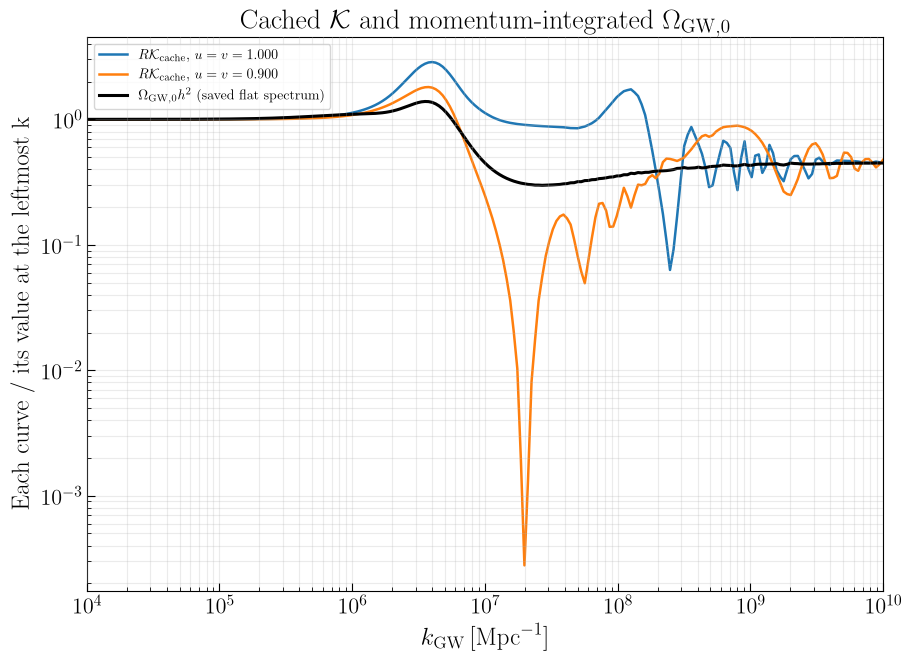

In [83]:
# Compare saved production-kernel cache with the saved flat-spectrum Omega_GW curve.
# Edit these u=v values and k limits directly. One cell draws one figure.
CACHE_OMEGA_COMPARE_U_VALUES = [1.0, 0.9]
CACHE_OMEGA_COMPARE_K_MIN = 1.0e4
CACHE_OMEGA_COMPARE_K_MAX = 1.0e10
CACHE_OMEGA_COMPARE_ETA_F = 1.0e-4
SAVE_FIGURE = True

# This cache stores (k/H)^2 <I_Overleaf^2/(4a^2)> already.
# Do not divide by a(eta_c)^2 again: the time-dependent division was done
# inside the cached response before its phase average.
cache_eval = load_kernel_interpolator(KERNEL_PATH)
omega_data = np.loadtxt(DATA_DIR / 'flat_model.csv', delimiter=',', skiprows=1)
k_saved = omega_data[:, 0]
omega_saved = omega_data[:, 1]
valid = ((k_saved >= CACHE_OMEGA_COMPARE_K_MIN)
         & (k_saved <= CACHE_OMEGA_COMPARE_K_MAX))
k_plot = k_saved[valid]
omega_plot = omega_saved[valid]
if len(k_plot) < 2 or np.any(omega_plot <= 0.0):
    raise ValueError('The saved Omega_GW curve has no valid positive points in this k range.')
if k_plot[0] < cache_eval.k_grid[0] or k_plot[-1] > cache_eval.k_grid[-1]:
    raise ValueError('The requested k range extends outside the stored kernel grid.')

fig, ax = plt.subplots(figsize=(9, 6.5), constrained_layout=True)
for u_value in CACHE_OMEGA_COMPARE_U_VALUES:
    u_value = float(u_value)
    v_value = u_value
    if u_value <= 0.5:
        raise ValueError('Require u=v>1/2 so that s>0.')
    s_value = (u_value + v_value - 1.0) / np.sqrt(2.0)
    t_value = (u_value - v_value) / np.sqrt(2.0)
    eta_c = KERNEL_X_EVAL / (k_plot * max(1.0, u_value, v_value))
    kernel_generation = cache_eval(k_plot, np.log10(s_value), t_value)
    redshift = today_redshift_factor(eta_c, eta_f=CACHE_OMEGA_COMPARE_ETA_F)
    kernel_today = kernel_generation * redshift
    if not np.all(np.isfinite(kernel_today)) or np.any(kernel_today <= 0.0):
        raise ValueError(f'Invalid cached kernel for u=v={u_value:g}.')
    ax.plot(k_plot, kernel_today / kernel_today[0], lw=1.8,
            label=rf'$R\mathcal{{K}}_{{\rm cache}}$, $u=v={u_value:.3f}$')

ax.plot(k_plot, omega_plot / omega_plot[0], color='black', lw=2.2,
        label=r'$\Omega_{\rm GW,0}h^2$ (saved flat spectrum)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(CACHE_OMEGA_COMPARE_K_MIN, CACHE_OMEGA_COMPARE_K_MAX)
ax.set_xlabel(r'$k_{\rm GW}\,[\mathrm{Mpc}^{-1}]$')
ax.set_ylabel('Each curve / its value at the leftmost k')
ax.set_title(r'Cached $\mathcal{K}$ and momentum-integrated $\Omega_{\rm GW,0}$')
ax.grid(alpha=0.25, which='both')
ax.legend(fontsize=10)
if SAVE_FIGURE:
    figure_path = PROJECT_DIR / 'output' / 'kernel_cache_redshift_vs_flat_omega_model.png'
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=180)
    print('Saved figure:', figure_path)
plt.show()


Saved figure: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\omega_integrand_transition_phi_equal_uv_f_transition_normalized_a_transition_green_transition_entry_removed.png


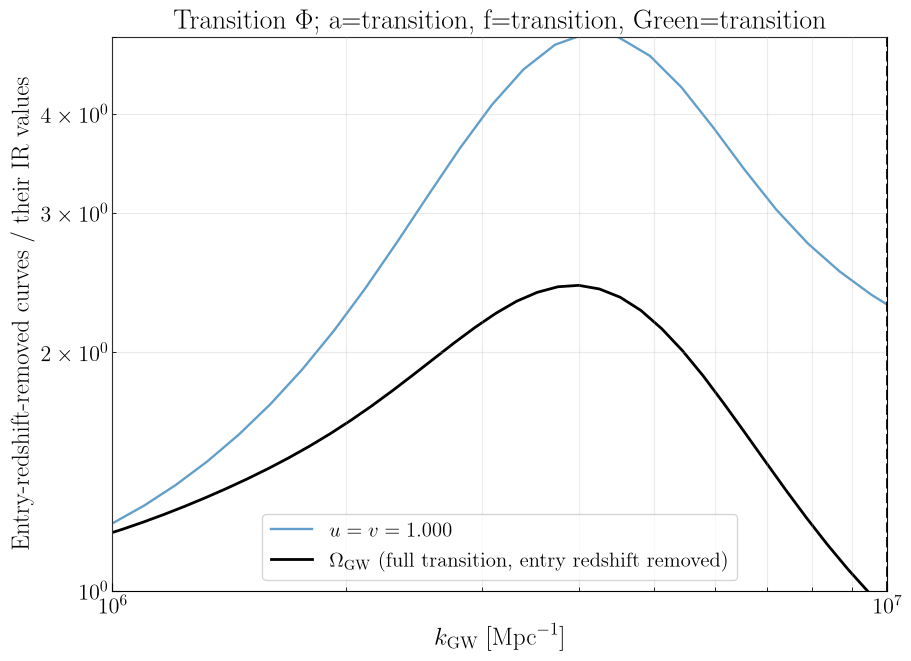

In [84]:
# Plot normalized local uv integrands against the saved flat-spectrum curve.
# One figure per cell. Edit the indices to choose the displayed curves.
KERNEL_UV_COMPARE_PLOT_INDICES = list(range(len(KERNEL_UV_COMPARE_UV)))
KERNEL_UV_COMPARE_PLOT_P_ZETA = 1.0
SAVE_PLOT = True
OUTPUT_FILENAME = (
    'omega_integrand_transition_phi_equal_uv_f_'
    + ('transition' if KERNEL_UV_COMPARE_USE_TRANSITION_F else 'radiation')
    + '_normalized_a_' + ('transition' if KERNEL_UV_COMPARE_USE_TRANSITION_A else 'radiation')
    + '_green_' + KERNEL_UV_COMPARE_GREEN + '_entry_removed.png'
)
if globals().get('kernel_uv_compare_settings') != {
    'use_transition_phi': True, 'use_transition_f': KERNEL_UV_COMPARE_USE_TRANSITION_F,
    'use_transition_a': KERNEL_UV_COMPARE_USE_TRANSITION_A,
    'include_redshift_factor': KERNEL_UV_COMPARE_INCLUDE_REDSHIFT_FACTOR,
    'redshift_eta_f': KERNEL_UV_COMPARE_REDSHIFT_ETA_F,
    'green': KERNEL_UV_COMPARE_GREEN,
}:
    raise RuntimeError('Rerun the equal-u scan calculation cell before plotting.')

kernel_uv_compare_early = kernel_redshift_compare['kernel_raw'][
    0 if KERNEL_UV_COMPARE_USE_TRANSITION_A else 1
] * kernel_redshift_compare['end_factor'] / kernel_redshift_compare['entry_factor'][None, :]

fig, ax = plt.subplots(figsize=(9, 6.5), constrained_layout=True)
for ip in KERNEL_UV_COMPARE_PLOT_INDICES:
    u_plot, v_plot = KERNEL_UV_COMPARE_UV[ip]
    # Omega_GW = (2/3) integral du dv P(u,v) K P_zeta(ku) P_zeta(kv).
    # No factor of 2: that factor applies only after folding the uv plane to t>=0.
    uv_prefactor = ((2.0 / 3.0) * float(projection_factor(u_plot, v_plot))
                    * KERNEL_UV_COMPARE_PLOT_P_ZETA**2)
    ax.plot(
        KERNEL_UV_COMPARE_K_GRID,
        kernel_uv_compare_early[ip] / kernel_uv_compare_early[ip, 0],
        linewidth=1.7,
        label=rf'$u=v={u_plot:.3f}$', alpha=0.7
    )
data = np.loadtxt(DATA_DIR / 'flat_model_early.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.plot(kspan,OmegaGW/OmegaGW[0],label=r'$\Omega_{\rm GW}$ (full transition, entry redshift removed)',color='black')
plt.axvline(x=1e7,color='black',ls='--')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$k_{\mathrm{GW}}\;[\mathrm{Mpc}^{-1}]$')
ax.set_ylim(1,5)
ax.set_xlim(1e6,1e7)
ax.set_ylabel('Entry-redshift-removed curves / their IR values')
f_label = 'transition' if KERNEL_UV_COMPARE_USE_TRANSITION_F else 'radiation'
a_label = 'transition' if KERNEL_UV_COMPARE_USE_TRANSITION_A else 'radiation'
ax.set_title(r'Transition $\Phi$; ' + f'a={a_label}, f={f_label}, Green={KERNEL_UV_COMPARE_GREEN}')
ax.grid(alpha=0.25, which='both')
ax.legend()
if SAVE_PLOT:
    figure_path = PROJECT_DIR / 'output' / OUTPUT_FILENAME
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=180)
    print('Saved figure:', figure_path)
plt.show()


In [ ]:
# Eight independent Phi/f/a combinations at u=v=sqrt(3)/2.
# Green uses the analytic radiation basis; f uses either transition w,H or radiation w=1/3,H=1/eta.
from itertools import product
import contextlib
import io

KERNEL_RESONANCE_U = np.sqrt(3.0) / 2.0
KERNEL_RESONANCE_K_GRID = KERNEL_ENDPOINT_SCAN_K_GRID.copy()
KERNEL_RESONANCE_N_TIME = KERNEL_ENDPOINT_SCAN_N_TIME
KERNEL_RESONANCE_X_SOURCE = KERNEL_ENDPOINT_SCAN_X_SOURCE
KERNEL_RESONANCE_INCLUDE_REDSHIFT_FACTOR = True
KERNEL_RESONANCE_REDSHIFT_ETA_F = 1e-4
KERNEL_RESONANCE_SWITCHES = np.asarray(
    list(product((True, False), (True, False), (True, False))), dtype=bool
)
KERNEL_RESONANCE_FORCE = False
KERNEL_RESONANCE_CACHE = DATA_DIR / (
    'kernel_endpoint_scan_resonance_phi_f_a_green_radiation_redshift_'
    + ('on' if KERNEL_RESONANCE_INCLUDE_REDSHIFT_FACTOR else 'off')
    + '_etaf_' + format(KERNEL_RESONANCE_REDSHIFT_ETA_F, '.6g').replace('.', 'p')
    + '_v2.npz'
)

kernel_resonance_values = np.full(
    (len(KERNEL_RESONANCE_SWITCHES), len(KERNEL_RESONANCE_K_GRID)), np.nan
)
if KERNEL_RESONANCE_CACHE.exists() and not KERNEL_RESONANCE_FORCE:
    try:
        with np.load(KERNEL_RESONANCE_CACHE, allow_pickle=False) as cached:
            compatible = (
                np.array_equal(cached['k_grid'], KERNEL_RESONANCE_K_GRID)
                and np.array_equal(cached['switches'], KERNEL_RESONANCE_SWITCHES)
                and np.isclose(float(cached['u']), KERNEL_RESONANCE_U)
                and int(cached['n_time']) == int(KERNEL_RESONANCE_N_TIME)
                and np.isclose(float(cached['x_source']), KERNEL_RESONANCE_X_SOURCE)
                and bool(cached['include_redshift_factor']) == KERNEL_RESONANCE_INCLUDE_REDSHIFT_FACTOR
                and np.isclose(float(cached['redshift_eta_f']), KERNEL_RESONANCE_REDSHIFT_ETA_F)
                and cached['kernel_endpoint'].shape == kernel_resonance_values.shape
                and str(cached['green']) == 'radiation'
            )
            if compatible:
                kernel_resonance_values[:] = cached['kernel_endpoint']
                print('Resuming/reusing resonance Phi/f/a cache:', KERNEL_RESONANCE_CACHE)
    except (OSError, KeyError, ValueError):
        pass

if np.isnan(kernel_resonance_values).any():
    phi_objects = {
        True: phi_cache if phi_cache is not None else PiecewisePhiTransfer(
            cache_dir=PHI_CACHE_DIR, ignore_metadata=True
        ),
        False: RadiationPhiTransfer(),
    }
    green_radiation = RadiationGreen()
    for ic, (use_phi, use_f, use_a) in enumerate(KERNEL_RESONANCE_SWITCHES):
        if np.all(np.isfinite(kernel_resonance_values[ic])):
            continue
        print(f'Computing resonance case {ic + 1}/8: '
              f"Phi={'transition' if use_phi else 'radiation'}, "
              f"f={'transition' if use_f else 'radiation'}, "
              f"a={'transition' if use_a else 'radiation'}")
        for ik, k_gw in enumerate(KERNEL_RESONANCE_K_GRID):
            if np.isfinite(kernel_resonance_values[ic, ik]):
                continue
            with contextlib.redirect_stdout(io.StringIO()):
                result = kernel_analysis_running_integrals(
                    u=float(KERNEL_RESONANCE_U), v=float(KERNEL_RESONANCE_U),
                    k=float(k_gw), use_transition_phi=bool(use_phi),
                    use_transition_f=bool(use_f), use_transition_a=bool(use_a),
                    include_redshift_factor=KERNEL_RESONANCE_INCLUDE_REDSHIFT_FACTOR,
                    redshift_eta_f=KERNEL_RESONANCE_REDSHIFT_ETA_F,
                    phi_transfer=phi_objects[bool(use_phi)],
                    green_cache=green_radiation, run_frozen_basis=False,
                    x_source=KERNEL_RESONANCE_X_SOURCE,
                    n_time=KERNEL_RESONANCE_N_TIME,
                )
            kernel_resonance_values[ic, ik] = result['kernel_from_integrals']
        KERNEL_RESONANCE_CACHE.parent.mkdir(parents=True, exist_ok=True)
        checkpoint_path = KERNEL_RESONANCE_CACHE.with_name(
            KERNEL_RESONANCE_CACHE.stem + '.building.npz'
        )
        np.savez_compressed(
            checkpoint_path, k_grid=KERNEL_RESONANCE_K_GRID,
            u=float(KERNEL_RESONANCE_U),
            switches=KERNEL_RESONANCE_SWITCHES,
            kernel_endpoint=kernel_resonance_values,
            n_time=int(KERNEL_RESONANCE_N_TIME),
            x_source=float(KERNEL_RESONANCE_X_SOURCE),
            include_redshift_factor=KERNEL_RESONANCE_INCLUDE_REDSHIFT_FACTOR,
            redshift_eta_f=KERNEL_RESONANCE_REDSHIFT_ETA_F,
            green='radiation',
        )
        checkpoint_path.replace(KERNEL_RESONANCE_CACHE)
        print('Saved checkpoint:', KERNEL_RESONANCE_CACHE)

if not np.all(np.isfinite(kernel_resonance_values)):
    raise RuntimeError('The resonance Phi/f/a scan is incomplete.')


Saved figure: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\omega_integrand_uv_resonance_phi_f_a_green_radiation.png
Applied uv prefactor = 0.2962962962962963
Included scan redshift factor = True


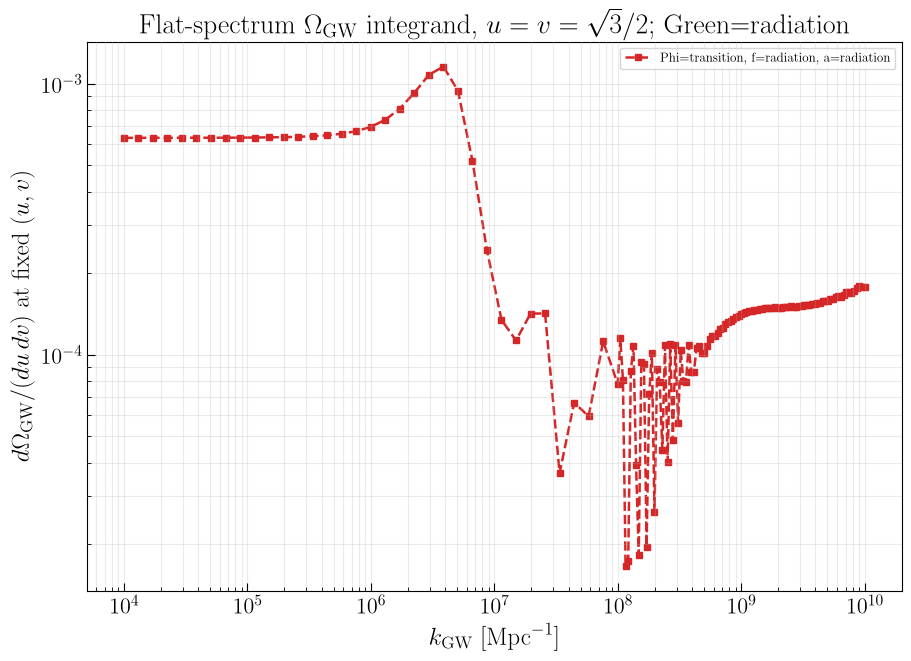

In [86]:
# Plot the Omega_GW local integrand at u=v=sqrt(3)/2.
# The prefactor is the one multiplying the kernel in the flat-spectrum uv integral.
# The scan values already include the selected redshift factor.
# Set KERNEL_RESONANCE_INCLUDE_REDSHIFT_FACTOR=False in the scan cell to remove it.
PLOT_CASES = [
    (True, False, False),
    # (True, True, False),
    # (False, True, False),
    # (False, False, False),
]
KERNEL_RESONANCE_PLOT_INCLUDE_TODAY_FACTOR = False
KERNEL_RESONANCE_PLOT_P_ZETA = 1.0
SAVE_PLOT = True
OUTPUT_FILENAME = 'omega_integrand_uv_resonance_phi_f_a_green_radiation.png'

u_plot = float(KERNEL_RESONANCE_U)
v_plot = float(KERNEL_RESONANCE_U)
projection_plot = float(projection_factor(u_plot, v_plot))
# This is dOmega/(du dv) at a fixed point. The factor of two belongs only
# to the folded t>=0 integration in omega_gw_h2, not to this local density.
omega_prefactor = (2.0 / 3.0) * projection_plot * KERNEL_RESONANCE_PLOT_P_ZETA**2
if KERNEL_RESONANCE_PLOT_INCLUDE_TODAY_FACTOR:
    raise ValueError(
        'The resonance scan already contains its redshift factor; '
        'turn it off in the scan cell instead of multiplying here.'
    )
omega_today_factor = np.ones_like(KERNEL_RESONANCE_K_GRID)

switch_order = [tuple(row) for row in KERNEL_RESONANCE_SWITCHES]
fig, ax = plt.subplots(figsize=(9, 6.5), constrained_layout=True)
for case in PLOT_CASES:
    case = tuple(case)
    if case not in switch_order:
        raise ValueError(f'Unknown Phi/f/a combination: {case}')
    i = switch_order.index(case)
    label_text = (
        f"Phi={'transition' if case[0] else 'radiation'}, "
        f"f={'transition' if case[1] else 'radiation'}, "
        f"a={'transition' if case[2] else 'radiation'}"
    )
    weighted_curve = (
        omega_prefactor * omega_today_factor * kernel_resonance_values[i]
    )
    ax.plot(
        KERNEL_RESONANCE_K_GRID, weighted_curve,
        color=plt.get_cmap('tab10')(i),
        linestyle='-' if case[1] else '--',
        marker='o' if case[2] else 's',
        markersize=4.0, linewidth=1.8, label=label_text,
    )
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$k_{\rm GW}\;[\mathrm{Mpc}^{-1}]$')
ax.set_ylabel(r'$d\Omega_{\rm GW}/(du\,dv)$ at fixed $(u,v)$')
ax.set_title(
    r'Flat-spectrum $\Omega_{\rm GW}$ integrand, '
    r'$u=v=\sqrt{3}/2$; Green=radiation'
)
ax.grid(alpha=0.25, which='both')
ax.legend(fontsize=9, ncol=2)
if SAVE_PLOT:
    figure_path = PROJECT_DIR / 'output' / OUTPUT_FILENAME
    figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_path, dpi=180)
    print('Saved figure:', figure_path)
print('Applied uv prefactor =', omega_prefactor)
print('Included scan redshift factor =', KERNEL_RESONANCE_INCLUDE_REDSHIFT_FACTOR)
plt.show()


# GW compute
## Momentum integral and present-day spectrum

The Gaussian scalar result is evaluated in the Domenech convention,

\[
\Omega_{\rm GW}(k,\eta_c)=\frac{2}{3}\int du\,dv\,\mathcal{P}(u,v)
\left(\frac{k}{\mathcal{H}_c}\right)^2\overline{I^2}\,P_\zeta(ku)P_\zeta(kv).
\]

The code multiplies by the redshift factor from arXiv:2307.01653 to return `Omega_GW h^2` today. If you want the generation-time fraction instead, set `include_today_factor=False`.


In [ ]:
def _gauss_legendre_interval(a, b, n):
    nodes, weights = leggauss(int(n))
    x = 0.5 * (b - a) * nodes + 0.5 * (a + b)
    w = 0.5 * (b - a) * weights
    return x, w


def _composite_gauss_legendre(grid, lower, upper, order):
    grid = np.asarray(grid, dtype=float)
    if lower < grid[0] or upper > grid[-1] or upper <= lower:
        raise ValueError(
            f'Integration interval [{lower:g}, {upper:g}] is outside '
            f'the kernel grid [{grid[0]:g}, {grid[-1]:g}].'
        )
    edges = np.concatenate(([lower], grid[(grid > lower) & (grid < upper)], [upper]))
    nodes, weights = leggauss(int(order))
    lo = edges[:-1, None]
    hi = edges[1:, None]
    x = 0.5 * (hi - lo) * nodes + 0.5 * (hi + lo)
    w = 0.5 * (hi - lo) * weights
    return x.ravel(), w.ravel()


def omega_gw_h2(
    k_values,
    P_zeta,
    kernel_eval,
    log10s_bounds=(-2.0, 2.0),
    n_s=160,
    n_t=80,
    include_today_factor=True,
    eta_f=None,
    x_eval=1e3,
    quadrature='auto',
    cell_order=4,
):
    k_values = np.atleast_1d(np.asarray(k_values, dtype=float))
    native_s = getattr(kernel_eval, 'log10s_grid', None)
    native_t = getattr(kernel_eval, 't_grid', None)
    use_composite = quadrature == 'kernel_grid' or (
        quadrature == 'auto' and native_s is not None and native_t is not None
    )
    if quadrature not in {'auto', 'kernel_grid', 'global'}:
        raise ValueError("quadrature must be 'auto', 'kernel_grid', or 'global'.")
    if quadrature == 'kernel_grid' and (native_s is None or native_t is None):
        raise ValueError('kernel_grid quadrature requires a kernel loaded by load_kernel_interpolator().')

    if use_composite:
        s_nodes, s_weights = _composite_gauss_legendre(
            native_s, log10s_bounds[0], log10s_bounds[1], cell_order
        )
        t_nodes, t_weights = _composite_gauss_legendre(
            native_t, 0.0, native_t[-1], cell_order
        )
    else:
        s_nodes, s_weights = _gauss_legendre_interval(log10s_bounds[0], log10s_bounds[1], n_s)
        t_nodes, t_weights = _gauss_legendre_interval(0.0, default_kernel_t_grid()[-1], n_t)
    S, T = np.meshgrid(s_nodes, t_nodes, indexing='xy')
    WS, WT = np.meshgrid(s_weights, t_weights, indexing='xy')
    U, V = st_to_uv(S, T)
    jac = 10.0**S * np.log(10.0)
    sym = 2.0  # integrate t >= 0 and use u-v symmetry
    geom = projection_factor(U, V)
    weight_2d = WS * WT

    out = []
    for k in k_values:
        K = kernel_eval(k, S, T)
        integrand = sym * (2.0 / 3.0) * jac * geom * K * P_zeta(U * k) * P_zeta(V * k)
        eta_c = x_eval / (k * np.maximum.reduce([np.ones_like(U), U, V]))
        if include_today_factor:
            integrand = integrand * today_redshift_factor(eta_c, eta_f=eta_f)
        else:
            integrand = integrand * today_redshift_factor(eta_c, eta_f=1/k)
        out.append(np.sum(weight_2d * integrand))
    out = np.array(out)
    return float(out[0]) if np.ndim(k_values) == 1 and len(k_values) == 1 else out


def P_log_normal(k, kp, width=0.01, amplitude=1.0):
    k = np.asarray(k, dtype=float)
    return amplitude * np.exp(-0.5 * (np.log(k / kp) / width)**2) / (np.sqrt(2.0 * np.pi) * width)


def P_flat(k, A_zeta=1.0):
    """Scale-invariant curvature spectrum, P_zeta(k)=A_zeta."""
    k = np.asarray(k, dtype=float)
    return np.full_like(k, float(A_zeta), dtype=float)


def omega_gw_delta_peak(
    k_values,
    kp,
    kernel_eval,
    amplitude=1.0,
    log10s_bounds=(-2.0, 2.0),
    t_max=0.7,
    include_today_factor=False,
    eta_f=None,
    x_eval=1e3,
):
    """Spectrum for P_zeta=A*delta(ln(k/kp)), reduced analytically."""
    scalar_input = np.ndim(k_values) == 0
    k_values = np.atleast_1d(np.asarray(k_values, dtype=float))
    if np.any(k_values <= 0.0) or kp <= 0.0:
        raise ValueError('k_values and kp must be positive.')

    r = k_values / float(kp)
    s = np.sqrt(2.0) * (1.0 / r - 0.5)
    s_min, s_max = 10.0**log10s_bounds[0], 10.0**log10s_bounds[1]
    out = np.zeros_like(r)
    valid = (r < 2.0) & (s >= s_min) & (s <= s_max) & (t_max >= 0.0)
    if np.any(valid):
        u = 1.0 / r[valid]
        geom = projection_factor(u, u)
        kernel = kernel_eval(
            k_values[valid],
            np.log10(s[valid]),
            np.zeros(np.count_nonzero(valid)),
        )
        values = (2.0 / 3.0) * amplitude**2 * u**2 * geom * kernel
        if include_today_factor:
            eta_c = x_eval / (k_values[valid] * np.maximum(1.0, u))
            values *= today_redshift_factor(eta_c, eta_f=eta_f)
        out[valid] = values
    return float(out[0]) if scalar_input else out


def omega_gw_lognormal_narrow(
    k_values,
    kp,
    kernel_eval,
    width=0.01,
    amplitude=1.0,
    n_gauss=120,
    sigma_cut=7.0,
    log10s_bounds=(-2.0, 2.0),
    t_max=0.7,
    include_today_factor=False,
    eta_f=None,
    x_eval=1e3,
    return_retained_weight=False,
):
    """Resolve a narrow log-normal spectrum in Gaussian peak coordinates.

    This avoids asking a broad fixed (log10(s), t) quadrature to find the
    Delta-wide peak.  The transformed variables are the independent Gaussian
    combinations of ln(u*k/kp) and ln(v*k/kp).
    """
    scalar_input = np.ndim(k_values) == 0
    k_values = np.atleast_1d(np.asarray(k_values, dtype=float))
    if np.any(k_values <= 0.0) or kp <= 0.0:
        raise ValueError('k_values and kp must be positive.')
    if width <= 0.0 or sigma_cut <= 0.0 or int(n_gauss) < 4:
        raise ValueError('width and sigma_cut must be positive, with n_gauss >= 4.')

    p, wp = _gauss_legendre_interval(-sigma_cut, sigma_cut, n_gauss)
    q, wq = _gauss_legendre_interval(0.0, sigma_cut, n_gauss)
    P, Q = np.meshgrid(p, q, indexing='xy')
    WP, WQ = np.meshgrid(wp, wq, indexing='xy')
    gaussian_weight = (WP * WQ / np.pi) * np.exp(-0.5 * (P**2 + Q**2))
    alpha = width * (P + Q) / np.sqrt(2.0)
    beta = width * (P - Q) / np.sqrt(2.0)
    exp_alpha = np.exp(alpha)
    exp_beta = np.exp(beta)
    s_min, s_max = 10.0**log10s_bounds[0], 10.0**log10s_bounds[1]

    out = np.zeros_like(k_values)
    retained = np.zeros_like(k_values)
    for index, k in enumerate(k_values):
        r = float(k / kp)
        u = exp_alpha / r
        v = exp_beta / r
        s = (u + v - 1.0) / np.sqrt(2.0)
        t = (u - v) / np.sqrt(2.0)
        valid = (s >= s_min) & (s <= s_max) & (t >= 0.0) & (t <= t_max)
        retained[index] = np.sum(gaussian_weight[valid])
        if not np.any(valid):
            continue
        geom = projection_factor(u[valid], v[valid])
        kernel = kernel_eval(
            np.full(np.count_nonzero(valid), k),
            np.log10(s[valid]),
            t[valid],
        )
        values = (2.0 / 3.0) * amplitude**2 * u[valid] * v[valid] * geom * kernel
        if include_today_factor:
            eta_c = x_eval / (k * np.maximum.reduce([np.ones(np.count_nonzero(valid)), u[valid], v[valid]]))
            values *= today_redshift_factor(eta_c, eta_f=eta_f)
        out[index] = np.sum(gaussian_weight[valid] * values)

    if scalar_input:
        spectrum_result = float(out[0])
        retained_result = float(retained[0])
    else:
        spectrum_result = out
        retained_result = retained
    return (spectrum_result, retained_result) if return_retained_weight else spectrum_result


def P_power_law_compact(k, A_zeta=1.0, k_star=2e7, n_s=1.0, k_min=1e5, k_max=1e8):
    k = np.asarray(k, dtype=float)
    out = A_zeta * (k / k_star)**(n_s - 1.0)
    out = np.where((k >= k_min) & (k <= k_max), out, 0.0)
    return out

# 先确认缓存文件确实存在
print(KERNEL_PATH, KERNEL_PATH.exists())

# 从 .npz cache 创建 (k, log10s, t) -> kernel 的插值函数
kernel_eval = load_kernel_interpolator(KERNEL_PATH)


C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\data\cache_model\kernel\kernel_grid_k1e2_1e10_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz True


In [ ]:

k_eval = np.geomspace(1e2, 10**10, 300)
omega_flat_today = omega_gw_h2(
    k_eval,
    lambda k: P_flat(k, 1.0),
    kernel_eval,
    x_eval=KERNEL_X_EVAL,
    include_today_factor = True
)


In [ ]:
import csv
with open('data/flat_model_ini.csv', 'w', newline='', encoding='utf-8') as csvfile:
    csv_writer = csv.writer(csvfile)
    
    csv_writer.writerow(['k', 'OmegaGW'])
    
    for row in zip(k_eval,omega_flat_today):
        csv_writer.writerow(row)


In [ ]:
import csv
with open(DATA_DIR / f'flat_model_entropy.csv', 'w', newline='', encoding='utf-8') as csvfile:
    csv_writer = csv.writer(csvfile)
    
    csv_writer.writerow(['k', 'entropy'])
    
    for row in zip(k_eval,    today_redshift_factor(1 / k_eval, 1e-4)/ today_redshift_factor(1e-1, 1e-4)):
        csv_writer.writerow(row)


In [ ]:
# OmegaGW
k_eval = np.geomspace(1e2, 10**10, 300)
omega_flat_today = omega_gw_h2(
    k_eval,
    lambda k: P_flat(k, 1.0),
    kernel_eval,
    x_eval=KERNEL_X_EVAL,
    include_today_factor = False
)


In [ ]:
import csv
with open('data/flat_model_early.csv', 'w', newline='', encoding='utf-8') as csvfile:
    csv_writer = csv.writer(csvfile)
    
    csv_writer.writerow(['k', 'OmegaGW'])
    
    for row in zip(k_eval,omega_flat_today):
        csv_writer.writerow(row)

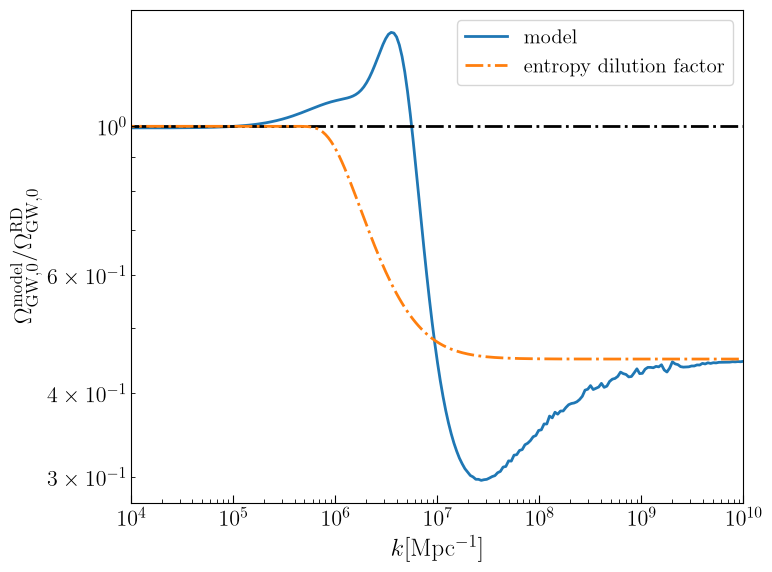

In [40]:
fig, ax = plt.subplots(figsize=(8, 6))
standard_flat = 3.45334986e-05
data = np.loadtxt('data/flat_model.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.plot(kspan,OmegaGW/standard_flat,label='model')
plt.xlabel(r'$k [\rm Mpc^{-1}]$')
plt.ylabel(r'$\Omega_{\mathrm{GW,0}}^{\rm model}/\Omega_{\mathrm{GW,0}}^{\rm RD}$')
plt.axhline(1,ls='-.',color='black')
plt.xlim(1e+4,1e+10)
plt.loglog(kspan, today_redshift_factor(1/kspan,1e-4)/today_redshift_factor(1e-3,1e-4),ls='-.',label=r'entropy dilution factor')
plt.legend()
plt.tight_layout()
plt.savefig('plot/flat_GWspectrum_model2.pdf')
plt.show()


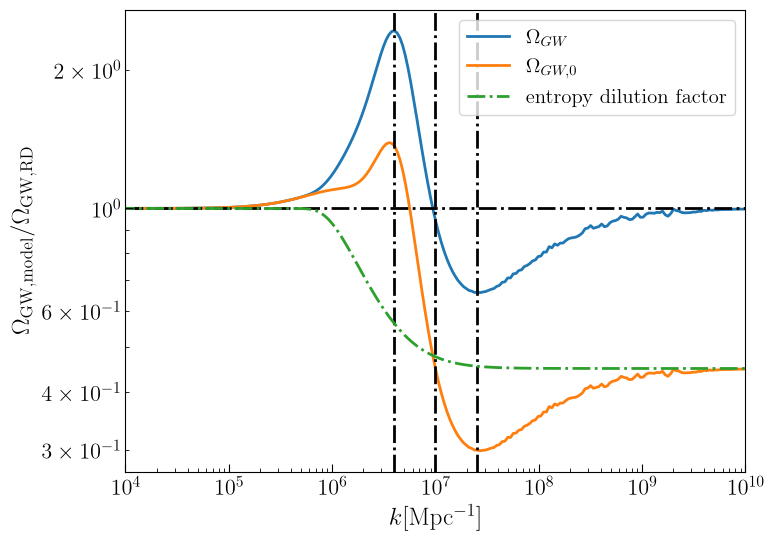

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
standard_flat = 3.45334986e-05
data = np.loadtxt('data/flat_model_early.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.plot(kspan,OmegaGW/OmegaGW[0],label=r'$\Omega_{GW}$')
data = np.loadtxt('data/flat_model.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.plot(kspan,OmegaGW/OmegaGW[0],label=r'$\Omega_{GW,0}$')
plt.xlabel(r'$k [\rm Mpc^{-1}]$')
plt.ylabel(r'$\Omega_{\mathrm{GW,model}}/\Omega_{\mathrm{GW,RD}}$')
plt.axhline(1,ls='-.',color='black')
plt.axvline(4e6,ls='-.',color='black')
plt.axvline(1e7,ls='-.',color='black')
plt.axvline(2.5e7,ls='-.',color='black')
plt.xlim(1e+4,1e+10)
plt.loglog(kspan, today_redshift_factor(1/kspan,1e-4)/today_redshift_factor(1e-3,1e-4),ls='-.',label=r'entropy dilution factor')
plt.legend()
plt.show()

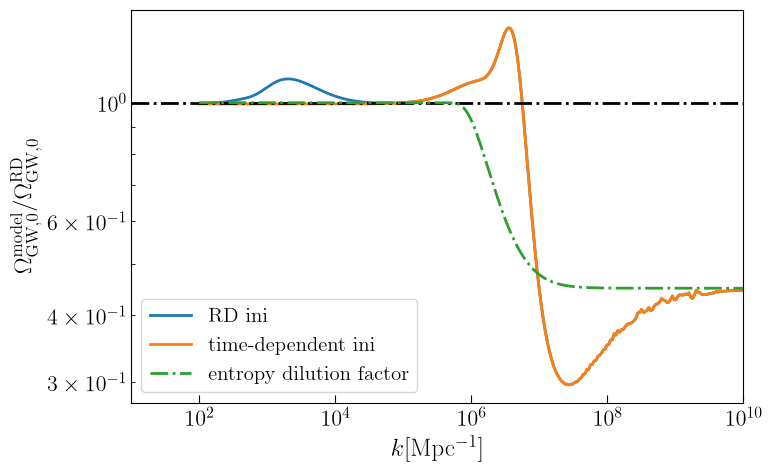

In [43]:
standard_flat = 3.45334986e-05
plt.figure(figsize=(8, 5))
data = np.loadtxt('data/flat_model_ini.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.plot(kspan,OmegaGW/standard_flat,label='RD ini')
data = np.loadtxt('data/flat_model.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.plot(kspan,OmegaGW/standard_flat,label='time-dependent ini')
plt.xlabel(r'$k [\rm Mpc^{-1}]$')
plt.ylabel(r'$\Omega_{\rm GW,0}^{\rm model}/\Omega_{\rm GW,0}^{\rm RD}$')
plt.axhline(1,ls='-.',color='black')
plt.xlim(1e+1,1e+10)
plt.loglog(kspan, today_redshift_factor(1/kspan,1e-4)/today_redshift_factor(1e-2,1e-4),ls='-.',label=r'entropy dilution factor')
plt.legend()
plt.tight_layout()
plt.savefig('plot/modelspectrum_initialcondition.pdf')
plt.show()


In [ ]:
standard_flat = 3.45334986e-05
data = np.loadtxt('data/flat_model.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
data = np.loadtxt('data/flat_model_ini.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW2 =data[:,1]
plt.loglog(kspan,abs(OmegaGW-OmegaGW2)/OmegaGW2,label='abs(sup-rad)/rad')
plt.xlabel(r'$k [\rm Mpc^{-1}]$')
plt.ylabel(r'$|\Omega_{sup}-\Omega_{rad}|/\Omega_{rad}$')
#plt.loglog(k_eval, today_redshift_factor(1/k_eval,1e-4)/today_redshift_factor(1e-2,1e-4),ls='-.',label=r'entropy dilution factor')
plt.legend()
plt.show()


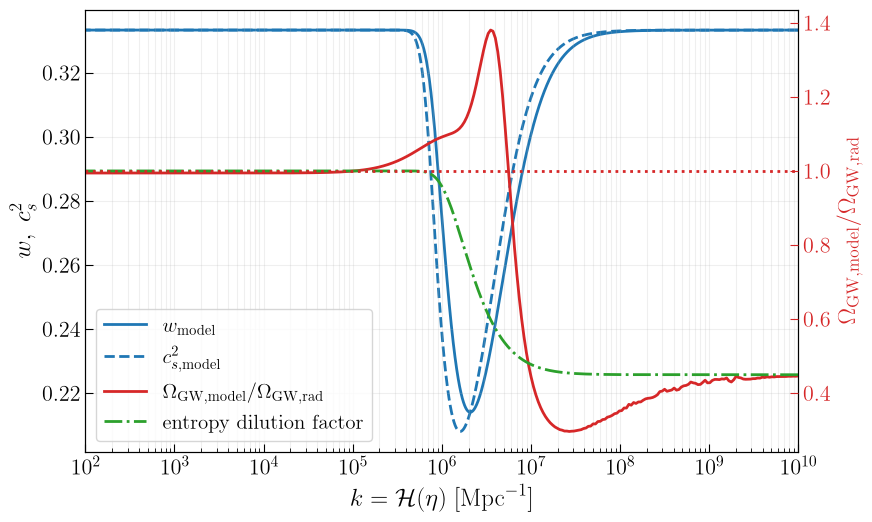

In [ ]:
# Plot the model background at horizon entry, k = calH(eta), with the flat SIGW ratio.
# calH is the conformal Hubble rate in Mpc^-1; this mapping labels each
# background epoch by the comoving mode entering the Hubble horizon then.
flat_table = np.loadtxt(DATA_DIR / 'flat_model.csv', delimiter=',', skiprows=1)
k_spectrum, omega_gw_model_h2 = flat_table.T
omega_gw_rad_h2 = 3.45334986e-05  # Same radiation benchmark as above.
if (np.any(np.diff(k_spectrum) <= 0) or np.any(k_spectrum <= 0)
        or np.any(~np.isfinite(omega_gw_model_h2))):
    raise ValueError('flat_model.csv must contain increasing positive k and finite OmegaGW.')
omega_ratio = omega_gw_model_h2 / omega_gw_rad_h2

eta_background = background['eta']
k_horizon = background['conH']  # k = aH = calH, not physical H.
w_background = eos(eta_background)
cs2_background = c_s_sq(eta_background)
# Normalize (a*calH)^2 to the late radiation era, where it is constant.
a_calH = background['a'] * k_horizon
entropy_dilution = (a_calH / a_calH[-1])**2
if np.any(np.diff(k_horizon) >= 0):
    raise ValueError('Expected calH(eta) to decrease throughout this background.')
in_spectrum_range = (k_horizon >= k_spectrum[0]) & (k_horizon <= k_spectrum[-1])

fig, ax_eos = plt.subplots(figsize=(9, 5.5))
ax_ratio = ax_eos.twinx()
ax_eos.plot(k_horizon[in_spectrum_range], w_background[in_spectrum_range],
            color='C0', lw=2, label=r'$w_{\mathrm{model}}$')
ax_eos.plot(k_horizon[in_spectrum_range], cs2_background[in_spectrum_range],
            color='C0',ls='--', lw=2, label=r'$c_{s,\mathrm{model}}^2$')

ax_ratio.plot(k_spectrum, omega_ratio, color='C3', lw=2,
              label=r'$\Omega_{\mathrm{GW,model}}/\Omega_{\mathrm{GW,rad}}$')
ax_ratio.plot(k_horizon[in_spectrum_range], entropy_dilution[in_spectrum_range],
              color='C2', ls='-.', lw=2, label=r'entropy dilution factor')
ax_ratio.axhline(1, color='C3', ls=':', lw=2)
ax_eos.set_xscale('log')
ax_eos.set_xlim(k_spectrum[0], k_spectrum[-1])
ax_eos.set_xlabel(r'$k=\mathcal{H}(\eta)\;[\mathrm{Mpc}^{-1}]$')
ax_eos.set_ylabel(r'$w,\ c_s^2$')
ax_ratio.set_ylabel(r'$\Omega_{\mathrm{GW,model}}/\Omega_{\mathrm{GW,rad}}$', color='C3')
ax_ratio.tick_params(axis='y', colors='C3')
ax_eos.grid(True, which='both', alpha=0.2)
lines = ax_eos.get_lines() + ax_ratio.get_lines()[:2]
ax_eos.legend(lines, [line.get_label() for line in lines], loc='best')
fig.tight_layout()
figure_path = PROJECT_DIR / 'output' / 'model_background_sigw_ratio.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()


## Delta-spectrum SIGWs over $10^4 \leq k_p \leq 10^{10}\,\mathrm{Mpc}^{-1}$

For $\mathcal{P}_\zeta(k)=A_\zeta\,\delta[\ln(k/k_p)]$, the momentum integral is reduced analytically by `omega_gw_delta_peak`. The scan below uses 31 logarithmically spaced $k_p$ values (five intervals per decade) and resolves both the broad support $0<k/k_p<2$ and the narrow radiation-era resonance. Results at generation and today are saved in long-table CSV form. The default $A_\zeta=1$ results scale exactly as $A_\zeta^2$.

The delta-spectrum scan uses the kernel over its current computed tensor-$k$ range. No additional kernel extension is applied in this section; the final plot therefore shows the native-kernel result directly.


In [ ]:
def delta_spectrum_ratio_grid(kernel_eval, ratio_min=0.03, ratio_max=1.99):
    """Resolve the broad delta spectrum and its narrow t=0 resonance."""
    resonance = 2.0 / np.sqrt(3.0)
    pieces = [
        np.geomspace(ratio_min, 0.30, 181),
        np.linspace(0.30, 0.90, 241),
        np.linspace(0.90, 1.35, 451),
        np.linspace(1.35, ratio_max, 321),
        np.linspace(resonance - 0.04, resonance + 0.04, 401),
        resonance + np.r_[
            -np.geomspace(1e-7, 0.02, 160)[::-1],
            0.0,
            np.geomspace(1e-7, 0.02, 160),
        ],
    ]
    native_log10s = getattr(kernel_eval, 'log10s_grid', None)
    if native_log10s is not None:
        native_s = 10.0**np.asarray(native_log10s, dtype=float)
        pieces.append(1.0 / (0.5 + native_s / np.sqrt(2.0)))
    ratio = np.unique(np.round(np.concatenate(pieces), 14))
    return ratio[(ratio >= ratio_min) & (ratio <= ratio_max)]


def compute_delta_spectrum_scan(
    kp_values, ratio, kernel_eval, amplitude=1.0, x_eval=KERNEL_X_EVAL
):
    """Compute generation-era and present-day spectra for each kp."""
    kp_values = np.asarray(kp_values, dtype=float)
    ratio = np.asarray(ratio, dtype=float)
    kernel_k = np.asarray(kernel_eval.k_grid, dtype=float)
    rows = []
    peaks = []
    for kp in kp_values:
        k = kp * ratio
        omega_c = omega_gw_delta_peak(
            k, kp, kernel_eval, amplitude=amplitude,
            include_today_factor=False, x_eval=x_eval,
        )
        u = 1.0 / ratio
        eta_c = x_eval / (k * np.maximum(1.0, u))
        omega_today = omega_c * today_redshift_factor(eta_c)
        extrapolated = (k < kernel_k[0]) | (k > kernel_k[-1])
        block = np.column_stack([
            np.full_like(ratio, kp),
            np.full_like(ratio, amplitude),
            ratio,
            k,
            k_mpc_to_hz(k),
            omega_c,
            omega_today,
            extrapolated.astype(int),
        ])
        rows.append(block)
        peak_index = int(np.argmax(omega_today))
        peaks.append(block[peak_index])
    return {
        'kp': kp_values,
        'ratio': ratio,
        'rows': np.vstack(rows),
        'peaks': np.vstack(peaks),
        'amplitude': float(amplitude),
    }


def save_delta_spectrum_scan(scan, output_dir):
    """Save the full spectra and one peak record per kp as CSV files."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    spectrum_path = output_dir / 'delta_spectrum_w=0.33_kp1e4_1e10.csv'
    peak_path = output_dir / 'delta_spectrum_w=0.33_kp1e4_1e10_peaks.csv'
    header = (
        'kp_Mpc^-1,A_zeta,k_over_kp,k_Mpc^-1,frequency_Hz,'
        'Omega_GW_c,Omega_GW_0_h2,kernel_extrapolated'
    )
    formats = [
        '%.10e', '%.10e', '%.14e', '%.10e',
        '%.10e', '%.14e', '%.14e', '%d',
    ]
    np.savetxt(
        spectrum_path, scan['rows'], delimiter=',', header=header,
        comments='', fmt=formats,
    )
    np.savetxt(
        peak_path, scan['peaks'], delimiter=',', header=header,
        comments='', fmt=formats,
    )
    return spectrum_path, peak_path


In [ ]:
DELTA_KP_VALUES = np.geomspace(1e4, 1e10, 31)
DELTA_A_ZETA = 1.0

if 'kernel_eval' not in globals():
    if not KERNEL_PATH.exists():
        raise FileNotFoundError(f'Generate the kernel cache first: {KERNEL_PATH}')
    kernel_eval = load_kernel_interpolator(KERNEL_PATH)

delta_ratio = delta_spectrum_ratio_grid(kernel_eval)
delta_scan = compute_delta_spectrum_scan(
    DELTA_KP_VALUES, delta_ratio, kernel_eval,
    amplitude=DELTA_A_ZETA, x_eval=KERNEL_X_EVAL,
)
delta_spectrum_path, delta_peak_path = save_delta_spectrum_scan(
    delta_scan, DATA_DIR
)
print(
    f'Computed {len(DELTA_KP_VALUES)} kp values x {len(delta_ratio)} k/kp values '
    f'for A_zeta={DELTA_A_ZETA:g}.'
)
print(
    'Rows outside native tensor-k range (excluded from final plot):',
    int(np.count_nonzero(delta_scan['rows'][:, -1])),
    '/', len(delta_scan['rows']),
)
print('Saved', delta_spectrum_path)
print('Saved', delta_peak_path)


Computed 31 kp values x 2444 k/kp values for A_zeta=1.
Rows outside native tensor-k range (excluded from final plot): 2088 / 75764
Saved C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\data\delta_spectrum_w=0.33_kp1e4_1e10.csv
Saved C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\data\delta_spectrum_w=0.33_kp1e4_1e10_peaks.csv


Saved C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\data\delta_and_flat_spectra_today.png


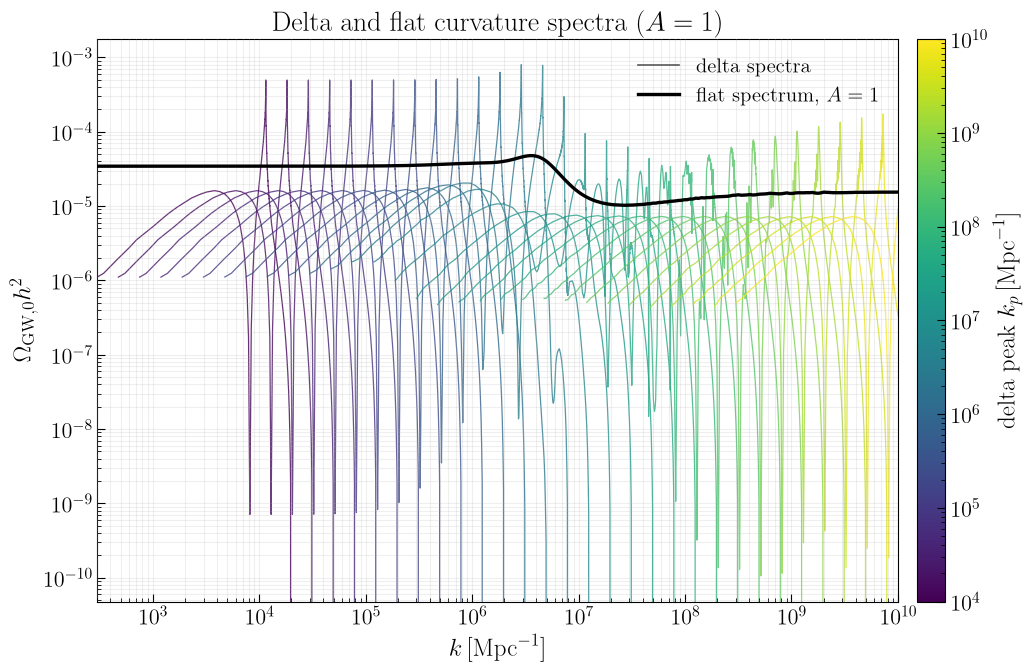

In [ ]:
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D

delta_plot_data = np.genfromtxt(
    DATA_DIR / 'delta_spectrum_w=0.33_kp1e4_1e10.csv',
    delimiter=',', names=True,
)
flat_plot_data = np.genfromtxt(
    DATA_DIR / 'flat_model.csv', delimiter=',', names=True,
)
delta_kp_values = np.unique(delta_plot_data['kp_Mpc1'])
color_norm = LogNorm(vmin=delta_kp_values.min(), vmax=delta_kp_values.max())
color_map = plt.colormaps['viridis']
fig, ax = plt.subplots(figsize=(11, 7))

for kp in delta_kp_values:
    block = delta_plot_data[delta_plot_data['kp_Mpc1'] == kp]
    color = color_map(color_norm(kp))
    in_grid = block['kernel_extrapolated'] == 0
    ax.loglog(
        block['k_Mpc1'],
        np.where(in_grid, block['Omega_GW_0_h2'], np.nan),
        color=color, lw=0.9, alpha=0.8,
    )

ax.loglog(
    flat_plot_data['k'], flat_plot_data['OmegaGW'],
    color='black', lw=2.4, zorder=5,
)
color_bar = fig.colorbar(
    plt.cm.ScalarMappable(norm=color_norm, cmap=color_map),
    ax=ax, pad=0.02,
)
color_bar.set_label(r'delta peak $k_p\,[\mathrm{Mpc}^{-1}]$')
legend_handles = [
    Line2D([0], [0], color='0.35', lw=1.2,
           label='delta spectra'),
    Line2D([0], [0], color='black', lw=2.4,
           label=r'flat spectrum, $A=1$'),
]
ax.legend(handles=legend_handles, frameon=False, loc='best')
ax.set_xlabel(r'$k\,[\mathrm{Mpc}^{-1}]$')
ax.set_ylabel(r'$\Omega_{\mathrm{GW},0}h^2$')
ax.set_title(r'Delta and flat curvature spectra ($A=1$)')
ax.grid(which='both', alpha=0.2)
native_plot_data = delta_plot_data[delta_plot_data['kernel_extrapolated'] == 0]
ax.set_xlim(native_plot_data['k_Mpc1'].min(), native_plot_data['k_Mpc1'].max())
fig.tight_layout()
delta_flat_figure_path = DATA_DIR / 'delta_and_flat_spectra_today.png'
#fig.savefig(delta_flat_figure_path, dpi=220, bbox_inches='tight')
print('Saved', delta_flat_figure_path)
plt.show()


## Model delta-spectrum comparison on $f/f_0=k/k_p$

Reuse the model scan above (`data/delta_spectrum_w=0.33_kp1e4_1e10.csv`), not the QCD scan. Interpolate $\ln\Omega_{\rm GW,0}h^2$ on $(\ln k_p,\ln x)$ with $x=k/k_p$. The saved spectrum already includes the present-day redshift factor. Normalize the cached scalar amplitude to $A=1$; scale the plotted spectrum by $A^2$. Below the first cached ratio attach a matched $x^2\ln^2x$ delta IR asymptote. Invalid native-kernel regions remain NaN; there is no nonzero UV continuation for a delta source. The last small interval above the scan endpoint (1.99) is set to zero, as in the earlier finite-support plotting convention.


In [ ]:
# Load the existing model delta cache; no scan or kernel is regenerated.
from pathlib import Path
import numpy as np
from scipy.interpolate import RegularGridInterpolator

MODEL_DELTA_PATH = DATA_DIR / 'delta_spectrum_w=0.33_kp1e4_1e10.csv'


def load_model_delta_spectrum(path=MODEL_DELTA_PATH):
    table = np.loadtxt(path, delimiter=',', skiprows=1)
    kp_grid = np.unique(table[:, 0])
    rows, masks = [], []
    x_grid = None
    for kp in kp_grid:
        block = table[table[:, 0] == kp]
        block = block[np.argsort(block[:, 2])]
        x = block[:, 2]  # explicitly k/kp, NOT physical k or frequency
        if x_grid is None:
            x_grid = x
        if x.shape != x_grid.shape or not np.allclose(x, x_grid, rtol=2e-10, atol=0):
            raise ValueError('Model delta scan has inconsistent x grids.')
        if np.any(block[:, 1] <= 0) or np.any(np.diff(x) <= 0):
            raise ValueError('Require positive amplitude and increasing x.')
        if not np.allclose(block[:, 3] / kp, x, rtol=2e-10, atol=0):
            raise ValueError('Physical-k and k/kp columns are inconsistent.')
        omega = block[:, 6] / block[:, 1]**2
        rows.append(omega)
        masks.append((block[:, 7] == 0) & np.isfinite(omega) & (omega > 0))
    log_interp = RegularGridInterpolator(
        (np.log(kp_grid), np.log(x_grid)),
        np.log(np.maximum(np.asarray(rows), np.finfo(float).tiny)), bounds_error=True)
    invalid_interp = RegularGridInterpolator(
        (np.log(kp_grid), np.log(x_grid)), (~np.asarray(masks)).astype(float), bounds_error=True)

    def spectrum(x, k_peak, amplitude=1.0):
        xa, ka = np.broadcast_arrays(np.asarray(x, float), np.asarray(k_peak, float))
        if np.any(xa <= 0) or np.any(ka <= 0) or not np.isfinite(amplitude) or amplitude < 0:
            raise ValueError('Require x,k_peak>0 and finite amplitude>=0.')
        if np.any(ka < kp_grid[0]) or np.any(ka > kp_grid[-1]):
            raise ValueError('k_peak outside model delta scan.')
        clipped = np.clip(xa, x_grid[0], x_grid[-1])
        points = np.column_stack((np.log(ka.ravel()), np.log(clipped.ravel())))
        out = np.exp(log_interp(points)).reshape(xa.shape)
        invalid = invalid_interp(points).reshape(xa.shape) > 1e-12
        out = np.where(invalid, np.nan, out)
        infrared = xa < x_grid[0]
        shape = (xa / x_grid[0])**2 * (np.log(xa) / np.log(x_grid[0]))**2
        out = np.where(infrared, out * shape, out)
        out = np.where(xa > x_grid[-1], 0.0, out) * amplitude**2
        return float(out) if out.ndim == 0 else out

    spectrum.k_peak_grid = kp_grid
    spectrum.x_grid = x_grid
    return spectrum


model_delta_spectrum = load_model_delta_spectrum()
print('Model delta cache:', MODEL_DELTA_PATH)
print('Loaded', len(model_delta_spectrum.k_peak_grid), 'peak scales; x range =',
      model_delta_spectrum.x_grid[[0, -1]])


Model delta cache: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\data\delta_spectrum_w=0.33_kp1e4_1e10.csv
Loaded 31 peak scales; x range = [0.03 1.99]


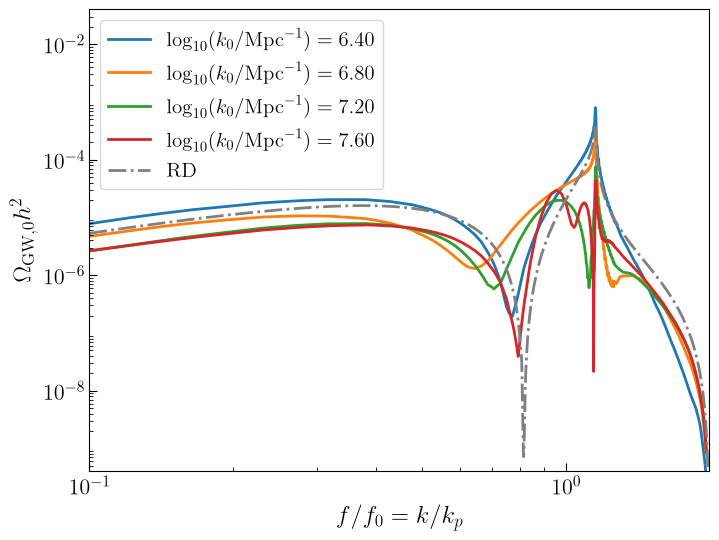

In [ ]:
# Same delta comparison layout as the QCD notebook, using MODEL spectra.
import matplotlib.ticker as mticker

MODEL_DELTA_KP_PLOT = np.geomspace(10**6.4, 10**7.6, 4)  # Mpc^-1
MODEL_DELTA_A_PLOT = 1.0
MODEL_DELTA_X_PLOT = np.geomspace(2e-2, 3.0, 10000)
MODEL_DELTA_SAVE_PLOT = False

fig, ax = plt.subplots(figsize=(8, 6))
model_delta_plot_spectra = {}
for kp in MODEL_DELTA_KP_PLOT:
    omega_model = model_delta_spectrum(MODEL_DELTA_X_PLOT, kp, MODEL_DELTA_A_PLOT)
    model_delta_plot_spectra[float(kp)] = omega_model
    ax.plot(MODEL_DELTA_X_PLOT, omega_model,
            label=fr'$\log_{{10}}(k_0/\mathrm{{Mpc}}^{{-1}})={np.log10(kp):.2f}$')

# RD delta table first column is x=k/kp; second column is the RD shape.
rd_delta = np.loadtxt(DATA_DIR / 'GW_ad_delta.csv', delimiter=',', skiprows=1)
ax.plot(rd_delta[:, 0], OMEGA_R0_H2 * MODEL_DELTA_A_PLOT**2 * rd_delta[:, 1],
        color='gray', ls='-.', label='RD')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$f/f_0=k/k_p$')
ax.set_ylabel(r'$\Omega_{\mathrm{GW},0}h^2$')
ax.legend()
ax.set_xlim(1e-1, 2)
ax.set_ylim(4e-10, 4e-2)
ax.set_xticks([0.1, 1])
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_yticks([1e-8, 1e-6, 1e-4, 1e-2])
if MODEL_DELTA_SAVE_PLOT:
    model_delta_figure_path = PROJECT_DIR.parents[2] / 'output' / 'delta_model.pdf'
    model_delta_figure_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(model_delta_figure_path, bbox_inches='tight')
    print('Saved', model_delta_figure_path)
plt.show()


k_0=2.511886e+06 Mpc^-1, eta=4/k_0=1.592429e-06 Mpc, c_s=0.548301, k_cancel=1.947753e+06 Mpc^-1, k_cancel/k_0=0.775415
k_0=6.309573e+06 Mpc^-1, eta=4/k_0=6.339573e-07 Mpc, c_s=0.457503, k_cancel=4.082341e+06 Mpc^-1, k_cancel/k_0=0.647007
k_0=1.584893e+07 Mpc^-1, eta=4/k_0=2.523829e-07 Mpc, c_s=0.511750, k_cancel=1.147024e+07 Mpc^-1, k_cancel/k_0=0.723723
k_0=3.981072e+07 Mpc^-1, eta=4/k_0=1.004755e-07 Mpc, c_s=0.559145, k_cancel=3.148037e+07 Mpc^-1, k_cancel/k_0=0.790751


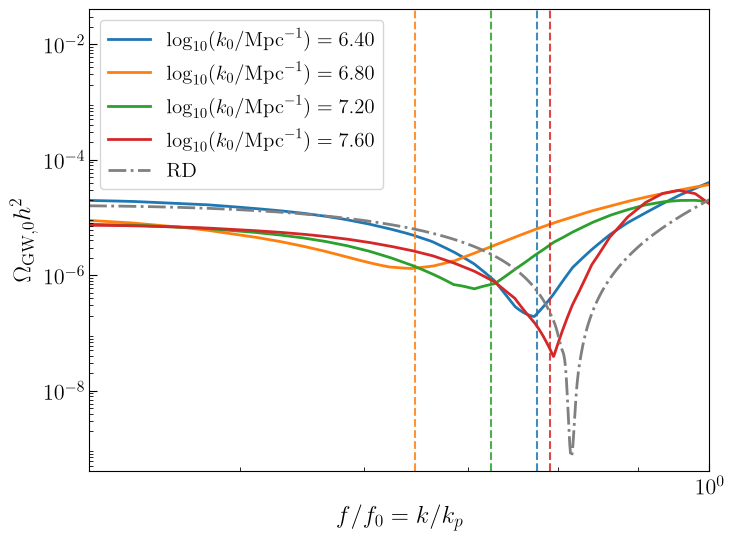

In [ ]:
# Repeat the comparison, marking k_cancel = sqrt(2) c_s(4/k_0) k_0.
fig, ax = plt.subplots(figsize=(8, 6))
for i, kp in enumerate(MODEL_DELTA_KP_PLOT):
    color = f'C{i}'  # Match the colors in the preceding figure.
    ax.plot(MODEL_DELTA_X_PLOT, model_delta_plot_spectra[float(kp)], color=color,
            label=fr'$\log_{{10}}(k_0/\mathrm{{Mpc}}^{{-1}})={np.log10(kp):.2f}$')
    eta_cancel = 4.0 / kp  # Physical conformal time in Mpc.
    cs2_at_eta = float(c_s_sq(eta_cancel))
    if not np.isfinite(cs2_at_eta) or cs2_at_eta <= 0:
        raise ValueError(f'Invalid c_s^2 at eta=4/k_0 for k_0={kp:g} Mpc^-1')
    cs = np.sqrt(cs2_at_eta)
    k_cancel = np.sqrt(2.0) * cs * kp
    ax.axvline(k_cancel / kp, color=color, ls='--', lw=1.5, alpha=0.85)
    print(f'k_0={kp:.6e} Mpc^-1, eta=4/k_0={eta_cancel:.6e} Mpc, '
          f'c_s={cs:.6f}, k_cancel={k_cancel:.6e} Mpc^-1, '
          f'k_cancel/k_0={k_cancel/kp:.6f}')

ax.plot(rd_delta[:, 0], OMEGA_R0_H2 * MODEL_DELTA_A_PLOT**2 * rd_delta[:, 1],
        color='gray', ls='-.', label='RD')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$f/f_0=k/k_p$')
ax.set_ylabel(r'$\Omega_{\mathrm{GW},0}h^2$')
ax.legend()
ax.set_xlim(4e-1, 1)
ax.set_ylim(4e-10, 4e-2)
#ax.set_xticks([0.1, 1])
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_yticks([1e-8, 1e-6, 1e-4, 1e-2])
plt.show()


### WKB amplitude check
$$
    \Phi_k(\eta)\sim\frac{C_k}{\sqrt{k c_s(\eta)}}
    \exp\left[-\frac32\int^\eta\mathcal H(1+c_s^2)\,d\tilde\eta\right]
    \exp\left[\pm ik\int^\eta c_s(\tilde\eta)d\tilde\eta\right],
$$
Phase delay
$$
    \Delta\theta(k,\eta)-\Delta\theta(k,\eta_W)
    \simeq k\int_{\eta_W}^{\eta}
    \left[c_s(\tilde\eta)-\frac{1}{\sqrt{3}}\right]d\tilde\eta,
$$

In [ ]:
# WKB amplitude factors: compare the MODEL background with w = c_s^2 = 1/3.
# The arbitrary overall normalization is removed by setting both F2 factors to
# unity at eta_wkb[0]; the ratios are therefore independent of this choice.
from scipy.integrate import cumulative_trapezoid

WKB_CHECK_K = 1.0e7       # Mpc^{-1}; only the absolute F1 normalization depends on k
# Start at horizon entry, eta >= 1/k, as a nominal lower bound; strict WKB requires k*c_s/H >> 1.
WKB_ETA_MIN = max(float(H_min_eta) * (1.0 + 1.0e-6), 1.0 / WKB_CHECK_K)
WKB_ETA_MAX = min(float(H_max_eta) * (1.0 - 1.0e-6), 1.0e-2)
if not WKB_ETA_MIN < WKB_ETA_MAX:
    raise ValueError(f'Invalid WKB eta interval: [{WKB_ETA_MIN:g}, {WKB_ETA_MAX:g}]')
eta_wkb = np.geomspace(WKB_ETA_MIN, WKB_ETA_MAX, 1200)

# First WKB factor: F1 = (k c_s)^(-1/2), with c_s = sqrt(c_s^2).
cs2_model = np.clip(np.asarray(c_s_sq(eta_wkb), dtype=float), 1.0e-15, None)
cs_model = np.sqrt(cs2_model)
cs_rad = np.sqrt(1.0 / 3.0)
F1_model = (WKB_CHECK_K * cs_model) ** (-0.5)
F1_rad = np.full_like(eta_wkb, (WKB_CHECK_K * cs_rad) ** (-0.5))

# Second WKB factor: F2 = exp[-3/2 integral H(1+c_s^2) d eta].
# For the radiation benchmark H = 1/eta, hence F2_rad = (eta/eta0)^(-2).
H_model = np.asarray(conH_interp(eta_wkb), dtype=float)
integrand_model = 1.5 * H_model * (1.0 + cs2_model)
log_F2_model = -np.concatenate(([0.0], cumulative_trapezoid(integrand_model, eta_wkb)))
F2_model = np.exp(log_F2_model)
F2_rad = (eta_wkb / eta_wkb[0]) ** (-2.0)

Famp_model = F1_model * F2_model
Famp_rad = F1_rad * F2_rad
ratio_F1 = F1_model / F1_rad
ratio_F2 = F2_model / F2_rad
ratio_Famp = Famp_model / Famp_rad

fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex='col')
absolute = ((F1_model, F1_rad, r'$F_1=(k c_s)^{-1/2}$'),
            (F2_model, F2_rad, r'$F_2=\exp[-\frac{3}{2}\int \mathcal{H}(1+c_s^2)d\eta]$'),
            (Famp_model, Famp_rad, r'$F_1F_2$'))
ratios = ((ratio_F1, r'$F_1/F_{1,\,\mathrm{rad}}$'),
          (ratio_F2, r'$F_2/F_{2,\,\mathrm{rad}}$'),
          (ratio_Famp, r'$(F_1F_2)/(F_1F_2)_{\mathrm{rad}}$'))
for ax, (model, rad, ylabel) in zip(axes[0], absolute):
    ax.loglog(eta_wkb, model, label='MODEL')
    ax.loglog(eta_wkb, rad, '--', label=r'$w=c_s^2=1/3$')
    ax.set_ylabel(ylabel)
    ax.grid(True, which='both', alpha=0.25)
    ax.legend(fontsize=11)
for ax, (ratio, ylabel) in zip(axes[1], ratios):
    ax.semilogx(eta_wkb, ratio, color='C3')
    ax.axhline(1.0, color='0.25', ls='--', lw=1.0)
    ax.set_ylabel(ylabel)
    ax.grid(True, which='both', alpha=0.25)
for ax in axes[1]:
    ax.set_xlabel(r'$\eta\,[\mathrm{Mpc}]$')
fig.suptitle(fr'WKB amplitude modulation, $k={WKB_CHECK_K:.2g}\,\mathrm{{Mpc}}^{{-1}}$')
fig.tight_layout()
plt.show()

print(f'Max |F1/F1_rad - 1| = {np.max(np.abs(ratio_F1 - 1.0)):.3e}')
print(f'Max |F2/F2_rad - 1| = {np.max(np.abs(ratio_F2 - 1.0)):.3e}')
print(f'Max |Famp/Famp_rad - 1| = {np.max(np.abs(ratio_Famp - 1.0)):.3e}')


In [ ]:
# Signed WKB phase shift across the MODEL interval relative to c_s^2 = 1/3.
# Here "MODEL interval" means cooling from 300 to 100 MeV; change these
# temperatures to test another explicit boundary convention.
MODEL_T_START_MEV = 300.0
MODEL_T_END_MEV = 100.0
PHASE_DELAY_K = WKB_CHECK_K  # Mpc^-1; phase shift scales linearly with k

def eta_at_temperature(temperature_mev, background_data):
    """Invert the monotone background T(eta) by interpolation in log space."""
    temperature_grid = np.asarray(background_data['temperature'], dtype=float)
    eta_grid = np.asarray(background_data['eta'], dtype=float)
    if not (temperature_grid[-1] <= temperature_mev <= temperature_grid[0]):
        raise ValueError('Requested temperature is outside the background grid.')
    return float(np.exp(np.interp(
        np.log(temperature_mev), np.log(temperature_grid[::-1]),
        np.log(eta_grid[::-1]),
    )))

def wkb_phase_delay_cycles(k, eta_start, eta_end, cs2_function, n_eta=10001):
    """Return (Delta theta, Delta theta/2pi) for c_s - 1/sqrt(3)."""
    if not (k > 0 and 0 < eta_start < eta_end and n_eta >= 3):
        raise ValueError('Require k > 0, 0 < eta_start < eta_end, n_eta >= 3.')
    eta_grid = np.geomspace(eta_start, eta_end, int(n_eta))
    cs2_grid = np.asarray(cs2_function(eta_grid), dtype=float)
    if np.any(~np.isfinite(cs2_grid)) or np.any(cs2_grid <= 0):
        raise ValueError('c_s^2 must be finite and positive on the integration grid.')
    delay_per_k = simpson(np.sqrt(cs2_grid) - 1.0 / np.sqrt(3.0), x=eta_grid)
    delta_theta = k * delay_per_k
    return delta_theta, delta_theta / (2.0 * np.pi)

eta_model_start = eta_at_temperature(MODEL_T_START_MEV, background)
eta_model_end = eta_at_temperature(MODEL_T_END_MEV, background)
phase_delay_rad, phase_delay_cycles = wkb_phase_delay_cycles(
    PHASE_DELAY_K, eta_model_start, eta_model_end, c_s_sq,
)
phase_delay_per_k_mpc = phase_delay_rad / PHASE_DELAY_K
print(f'MODEL interval: T={MODEL_T_START_MEV:g} -> {MODEL_T_END_MEV:g} MeV')
print(f'eta interval: {eta_model_start:.6e} -> {eta_model_end:.6e} Mpc')
print(f'Integral of (c_s - 1/sqrt(3)) d eta = {phase_delay_per_k_mpc:.9e} Mpc')
print(f'k={PHASE_DELAY_K:.3e} Mpc^-1: Delta theta = {phase_delay_rad:.6f} rad '
      f'= {phase_delay_cycles:.6f} cycles')
print(f'At MODEL start, k c_s / H = '
      f'{PHASE_DELAY_K * np.sqrt(c_s_sq(eta_model_start)) / conH_interp(eta_model_start):.3f}')


In [ ]:
# Peak-position and cumulative phase-delay check from the full ODE solution.
# A maximum of |Phi| between nodes occurs where dPhi/dx = 0 (excluding x=0).
from scipy.optimize import brentq

PEAK_SHIFT_K = 1.0e7  # Mpc^-1; set to WKB_CHECK_K to match the preceding diagnostic
PEAK_X_MAX = 100.0
PEAK_X_GRID = np.geomspace(X_INI, PEAK_X_MAX, 6000)

def phi_radiation_x(x):
    """Pure-radiation Phi per unit zeta, as a function of x=k*eta."""
    y = np.asarray(x, dtype=float) / np.sqrt(3.0)
    return -2.0 * (np.sin(y) - y * np.cos(y)) / y**3

def phi_radiation_prime_x(x):
    y = np.asarray(x, dtype=float) / np.sqrt(3.0)
    return (-2.0 / np.sqrt(3.0)
            * ((y**2 - 3.0) * np.sin(y) + 3.0 * y * np.cos(y)) / y**4)

def phi_absolute_peak_x(x_grid, phi, dphi_dx, x_min=1.0):
    """Locate oscillatory |Phi| peaks from roots of the signed Phi derivative."""
    phi_spline = CubicHermiteSpline(x_grid, phi, dphi_dx)
    brackets = np.flatnonzero(dphi_dx[:-1] * dphi_dx[1:] < 0)
    roots = [brentq(lambda x: phi_spline(x, 1), x_grid[i], x_grid[i + 1])
             for i in brackets]
    return np.asarray([root for root in roots if root >= x_min])

phi_model_grid, phi_prime_eta = solve_phi_transfer(
    PEAK_SHIFT_K, x_grid=PEAK_X_GRID, initial_condition='pure_radiation')
phi_rd_grid = phi_radiation_x(PEAK_X_GRID)
model_peaks_x = phi_absolute_peak_x(
    PEAK_X_GRID, phi_model_grid, phi_prime_eta / PEAK_SHIFT_K)
rd_peaks_x = phi_absolute_peak_x(
    PEAK_X_GRID, phi_rd_grid, phi_radiation_prime_x(PEAK_X_GRID))
# The peak counts can differ inside a fixed x-window.  Do not pair peaks
# only by ordinal number: after one missing oscillation, that would hide
# the accumulated phase delay.
PEAK_X_LEFT = 10.0
PEAK_X_RIGHT = 100.0
model_peaks_window = model_peaks_x[(model_peaks_x >= PEAK_X_LEFT) & (model_peaks_x <= PEAK_X_RIGHT)]
rd_peaks_window = rd_peaks_x[(rd_peaks_x >= PEAK_X_LEFT) & (rd_peaks_x <= PEAK_X_RIGHT)]
x_phase = np.geomspace(PEAK_X_LEFT, PEAK_X_RIGHT, 6000)
phase_integrand = np.sqrt(c_s_sq(x_phase / PEAK_SHIFT_K)) - 1.0 / np.sqrt(3.0)
phase_delay_x = cumulative_trapezoid(phase_integrand, x_phase, initial=0.0)
phase_delay_x_end = float(phase_delay_x[-1])
phase_delay_cycles_x_end = phase_delay_x_end / (2.0 * np.pi)

print(f'k = {PEAK_SHIFT_K:.3e} Mpc^-1; x = k eta; peaks of |Phi|')
print(f'Fixed window {PEAK_X_LEFT:g} <= x <= {PEAK_X_RIGHT:g}: '
      f'{len(model_peaks_window)} model peaks vs {len(rd_peaks_window)} RD peaks')
print(f'Cumulative WKB phase delay over this x-window: '
      f'{phase_delay_x_end:.6f} rad = {phase_delay_cycles_x_end:.6f} cycles')
print(' peak     x_RD       x_model     Delta x')
for i, (rd_x, model_x, shift) in enumerate(
        zip(rd_peaks_window[:10], model_peaks_window[:10],
            model_peaks_window[:10] - rd_peaks_window[:10]), start=1):
    print(f'{i:4d}  {rd_x:9.4f}  {model_x:9.4f}  {shift:9.4f}')

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(rd_peaks_window, model_peaks_window[:len(rd_peaks_window)] - rd_peaks_window[:len(model_peaks_window)],
        'o-', label=r'$x_{\rm model}-x_{\rm RD}$')
ax.axhline(0.0, color='0.4', ls='--', lw=1)
ax.set_xlabel(r'$x_{\rm peak,RD}=k\eta_{\rm peak,RD}$')
ax.set_ylabel(r'$\Delta x_{\rm peak}$')
ax.set_title(fr'$k={PEAK_SHIFT_K:.2g}\,\mathrm{{Mpc}}^{{-1}}$')
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


## Kernel cancellation diagnostic: signed integrands and Green basis

The following cells keep $\Phi$ in the transition background while using radiation $f$, radiation $a$, and the analytic radiation Green basis. They compare $k_{\rm GW}=4\times10^6$ and $10^7\,\mathrm{Mpc}^{-1}$ at $u=v=0.9$. The quantities plotted below are the signed integrands that enter the Green reconstruction, so their positive and negative areas show the cancellation directly.


In [ ]:
# Calculate the signed Green-reconstruction integrands and their cumulative integrals.
# This is a calculation cell only; the plotting cells below are intentionally bare.
from scipy.integrate import cumulative_simpson

KERNEL_CANCELLATION_U = 0.9
KERNEL_CANCELLATION_K_VALUES = np.array([4.0e6, 1.0e7])
KERNEL_CANCELLATION_X_SOURCE = 1.0e3
KERNEL_CANCELLATION_N_TIME = 12000
KERNEL_CANCELLATION_USE_TRANSITION_PHI = True
KERNEL_CANCELLATION_USE_TRANSITION_F = False
KERNEL_CANCELLATION_USE_TRANSITION_A = False
KERNEL_CANCELLATION_RESULTS = {}

if KERNEL_CANCELLATION_USE_TRANSITION_PHI:
    _cancellation_phi_transfer = (
        phi_cache if phi_cache is not None else
        PiecewisePhiTransfer(cache_dir=PHI_CACHE_DIR, ignore_metadata=True)
    )
else:
    _cancellation_phi_transfer = RadiationPhiTransfer()
_cancellation_green = RadiationGreen()
_cancellation_a = a_interp if KERNEL_CANCELLATION_USE_TRANSITION_A else (
    lambda eta: np.asarray(eta, dtype=float)
)

for _k in KERNEL_CANCELLATION_K_VALUES:
    _k = float(_k)
    _u = float(KERNEL_CANCELLATION_U)
    _v = _u
    _eta_min = float(choose_eta_min(_u, _v, _k))
    _eta_end = KERNEL_CANCELLATION_X_SOURCE / (_k * max(1.0, _u, _v))
    _eta_grid = _hybrid_source_eta_grid_many(
        np.array([_eta_min]), np.array([_eta_end]), _k,
        int(KERNEL_CANCELLATION_N_TIME)
    )[0]
    _x_grid = _k * _eta_grid
    _prepared_phi = _cancellation_phi_transfer.prepare_pair(
        np.array([_u]), np.array([_v]), _k
    )
    _prepared_green = _cancellation_green.prepare_k(_k)

    if KERNEL_CANCELLATION_USE_TRANSITION_F:
        _source_H = conH_interp(_eta_grid)
        _source_w = eos(_eta_grid)
    else:
        _source_H = 1.0 / _eta_grid
        _source_w = np.full_like(_eta_grid, 1.0 / 3.0)
    _source = source_f_from_prepared(
        np.array([[_u]]), np.array([[_v]]), _x_grid[None, :],
        _prepared_phi, _source_H[None, :], _source_w[None, :]
    )[0]

    _g1 = np.asarray(_prepared_green.basis['g1'](_x_grid), dtype=float)
    _g2 = np.asarray(_prepared_green.basis['g2'](_x_grid), dtype=float)
    _g1p = np.asarray(_prepared_green.basis['g1p'](_x_grid), dtype=float)
    _g2p = np.asarray(_prepared_green.basis['g2p'](_x_grid), dtype=float)
    _W = _g1p * _g2 - _g1 * _g2p
    _a_source = _cancellation_a(_eta_grid)
    _source_weight = _a_source * _source
    _q1 = _source_weight * _g1 / _W
    _q2 = _source_weight * _g2 / _W
    _C1 = cumulative_simpson(_q1, x=_eta_grid, initial=0.0)
    _C2 = cumulative_simpson(_q2, x=_eta_grid, initial=0.0)
    _phi_u = _prepared_phi.u_modes.phi((_u * _x_grid)[None, :])[0]
    _response = _k**2 * (_g1 * _C2 - _g2 * _C1) / _a_source
    _phi_zero_indices = np.flatnonzero(_phi_u[:-1] * _phi_u[1:] < 0.0)
    _phi_zero_first = np.nan
    if len(_phi_zero_indices):
        _iz = int(_phi_zero_indices[0])
        _phi_zero_first = float(
            _x_grid[_iz] - _phi_u[_iz] * (_x_grid[_iz + 1] - _x_grid[_iz])
            / (_phi_u[_iz + 1] - _phi_u[_iz])
        )

    KERNEL_CANCELLATION_RESULTS[_k] = {
        'k': _k, 'u': _u, 'v': _v,
        'x': _x_grid, 'eta': _eta_grid,
        'phi_u': np.asarray(_phi_u, dtype=float),
        'source': np.asarray(_source, dtype=float),
        'a': np.asarray(_a_source, dtype=float),
        'g1': _g1, 'g2': _g2, 'W': _W,
        'q1': _q1, 'q2': _q2,
        'C1': _C1, 'C2': _C2,
        'response': _response, 'phi_zero_first': _phi_zero_first,
    }
    _q1_positive = trapezoid(np.maximum(_q1, 0.0), _eta_grid)
    _q1_negative = trapezoid(np.minimum(_q1, 0.0), _eta_grid)
    _q2_positive = trapezoid(np.maximum(_q2, 0.0), _eta_grid)
    _q2_negative = trapezoid(np.minimum(_q2, 0.0), _eta_grid)
    print(
        f'k={_k:.3e}: C1(end)={_C1[-1]:+.6e}, '
        f'C2(end)={_C2[-1]:+.6e}, '
        f'max|q1|={np.max(np.abs(_q1)):.3e}, '
        f'max|q2|={np.max(np.abs(_q2)):.3e}'
    )
    print(
        f'  q1 positive={_q1_positive:+.6e}, negative={_q1_negative:+.6e}, '
        f'cancellation={1.0 - abs(_q1_positive + _q1_negative) / max(_q1_positive - _q1_negative, np.finfo(float).tiny):.3f}'
    )
    print(
        f'  q2 positive={_q2_positive:+.6e}, negative={_q2_negative:+.6e}, '
        f'cancellation={1.0 - abs(_q2_positive + _q2_negative) / max(_q2_positive - _q2_negative, np.finfo(float).tiny):.3f}'
    )


In [ ]:
# Figure 1: Phi and the two Green basis functions, shown together.
# Change KERNEL_CANCELLATION_K_VALUES above and rerun the calculation cell first.
fig, ax = plt.subplots(figsize=(10, 5.8), constrained_layout=True)
for _j, _k in enumerate(KERNEL_CANCELLATION_K_VALUES):
    _d = KERNEL_CANCELLATION_RESULTS[float(_k)]
    _x = _d['x']
    _mask = _x <= 80.0
    _phi_norm = _d['phi_u'] / np.max(np.abs(_d['phi_u']))
    _g1_norm = _d['g1'] / np.max(np.abs(_d['g1']))
    _g2_norm = _d['g2'] / np.max(np.abs(_d['g2']))
    _color = f'C{_j}'
    ax.plot(_x[_mask], _phi_norm[_mask], color=_color, lw=2.2,
            label=fr'$\\Phi$, $k_{{\\rm GW}}={_k:.0e}$')
    ax.plot(_x[_mask], _g1_norm[_mask], color=_color, ls='--', lw=1.5,
            label=fr'$g_1$ (norm.), $k_{{\\rm GW}}={_k:.0e}$')
    ax.plot(_x[_mask], _g2_norm[_mask], color=_color, ls=':', lw=1.5,
            label=fr'$g_2$ (norm.), $k_{{\\rm GW}}={_k:.0e}$')
ax.axhline(0.0, color='0.35', lw=0.9)
ax.set_xlabel(r'$x=k_{\\rm GW}\\eta$')
ax.set_ylabel('separately normalized amplitude')
ax.set_title(r'$u=v=0.9$: transition $\\Phi$ and radiation Green basis')
ax.set_xlim(0.0, 80.0)
ax.grid(alpha=0.25)
ax.legend(ncol=2, fontsize=10)
fig.savefig(PROJECT_DIR / 'output' / 'kernel_cancellation_phi_green.png', dpi=180, bbox_inches='tight')
plt.show()


In [ ]:
# Figure 2: the signed integrands q_i = a f g_i / W.
# Positive and negative lobes are the pieces that cancel in the time integral.
fig, ax = plt.subplots(figsize=(10, 5.8), constrained_layout=True)
for _j, _k in enumerate(KERNEL_CANCELLATION_K_VALUES):
    _d = KERNEL_CANCELLATION_RESULTS[float(_k)]
    _mask = _d['x'] <= 120.0
    _color = f'C{_j}'
    ax.plot(_d['x'][_mask], _d['q1'][_mask], color=_color, lw=1.7,
            label=fr'$q_1=a f g_1/W$, $k_{{\\rm GW}}={_k:.0e}$')
    ax.plot(_d['x'][_mask], _d['q2'][_mask], color=_color, ls='--', lw=1.7,
            label=fr'$q_2=a f g_2/W$, $k_{{\\rm GW}}={_k:.0e}$')
ax.axhline(0.0, color='k', lw=1.0)
ax.set_xlabel(r'$x=k_{\\rm GW}\\eta$')
ax.set_ylabel(r'$q_i(\\eta)=a(\\eta)f(\\eta)g_i(\\eta)/W(\\eta)$')
ax.set_title(r'Signed source integrands: positive/negative lobes cancel')
ax.set_xlim(0.0, 120.0)
ax.grid(alpha=0.25)
ax.legend(ncol=2, fontsize=10)
fig.savefig(PROJECT_DIR / 'output' / 'kernel_cancellation_signed_integrands.png', dpi=180, bbox_inches='tight')
plt.show()


In [ ]:
# Figure 3: cumulative signed integrals C_i(x) = integral q_i d eta.
# A plateau followed by a return toward zero is direct visual evidence of cancellation.
fig, ax = plt.subplots(figsize=(10, 5.8), constrained_layout=True)
for _j, _k in enumerate(KERNEL_CANCELLATION_K_VALUES):
    _d = KERNEL_CANCELLATION_RESULTS[float(_k)]
    _mask = _d['x'] <= 120.0
    _color = f'C{_j}'
    ax.plot(_d['x'][_mask], _d['C1'][_mask], color=_color, lw=2.0,
            label=fr'$C_1=\\int q_1d\\eta$, $k_{{\\rm GW}}={_k:.0e}$')
    ax.plot(_d['x'][_mask], _d['C2'][_mask], color=_color, ls='--', lw=2.0,
            label=fr'$C_2=\\int q_2d\\eta$, $k_{{\\rm GW}}={_k:.0e}$')
ax.axhline(0.0, color='k', lw=1.0)
ax.set_xlabel(r'$x=k_{\\rm GW}\\eta$')
ax.set_ylabel(r'cumulative coefficient $C_i(\\eta)$')
ax.set_title(r'Accumulated coefficients: later lobes undo earlier contributions')
ax.set_xlim(0.0, 120.0)
ax.grid(alpha=0.25)
ax.legend(ncol=2, fontsize=10)
fig.savefig(PROJECT_DIR / 'output' / 'kernel_cancellation_cumulative_integrals.png', dpi=180, bbox_inches='tight')
plt.show()


In [ ]:
# Figure 4: the reconstructed response shows how the two coefficients combine with g_i.
fig, ax = plt.subplots(figsize=(10, 5.8), constrained_layout=True)
for _j, _k in enumerate(KERNEL_CANCELLATION_K_VALUES):
    _d = KERNEL_CANCELLATION_RESULTS[float(_k)]
    _mask = _d['x'] <= 120.0
    _color = f'C{_j}'
    ax.plot(_d['x'][_mask], _d['response'][_mask], color=_color, lw=1.8,
            label=fr'$I(\\eta)$, $k_{{\\rm GW}}={_k:.0e}$')
ax.axhline(0.0, color='k', lw=1.0)
ax.set_xlabel(r'$x=k_{\\rm GW}\\eta$')
ax.set_ylabel(r'$I(\\eta)=k_{\\rm GW}^2(g_1C_2-g_2C_1)/a$')
ax.set_title(r'Green reconstruction: $g_1C_2-g_2C_1$')
ax.set_xlim(0.0, 120.0)
ax.grid(alpha=0.25)
ax.legend(fontsize=11)
fig.savefig(PROJECT_DIR / 'output' / 'kernel_cancellation_response.png', dpi=180, bbox_inches='tight')
plt.show()


In [ ]:
# Signed-lobe diagnostic for k_GW=4.0e+06.
# The filled areas show positive and negative contributions to q_i.
_k_plot = 4.0e+06
_d = KERNEL_CANCELLATION_RESULTS[_k_plot]
_x = _d['x']
_mask = _x <= 20.0
_q1 = (_k_plot**2) * _d['q1']
_q2 = (_k_plot**2) * _d['q2']
fig, ax = plt.subplots(figsize=(10, 5.8), constrained_layout=True)
ax.plot(_x[_mask], _q1[_mask], color='C0', lw=2.0, label=r'$k^2 q_1=k^2 a f g_1/W$')
ax.plot(_x[_mask], _q2[_mask], color='C1', lw=2.0, ls='--', label=r'$k^2 q_2=k^2 a f g_2/W$')
ax.fill_between(_x[_mask], 0.0, _q1[_mask], where=_q1[_mask]>=0.0, color='C0', alpha=0.18)
ax.fill_between(_x[_mask], 0.0, _q1[_mask], where=_q1[_mask]<0.0, color='C0', alpha=0.08)
ax.fill_between(_x[_mask], 0.0, _q2[_mask], where=_q2[_mask]>=0.0, color='C1', alpha=0.15)
ax.fill_between(_x[_mask], 0.0, _q2[_mask], where=_q2[_mask]<0.0, color='C1', alpha=0.07)
ax.axhline(0.0, color='k', lw=1.0)
ax.axvline(3.0*np.pi, color='C0', ls=':', lw=1.5, label=r'$g_1=0$ near $3\pi$')
ax.axvline(3.5*np.pi, color='C1', ls=':', lw=1.5, label=r'$g_2=0$ near $7\pi/2$')
ax.axvline(_d['phi_zero_first'], color='k', ls='-.', lw=1.6, label=fr'$\Phi=0$: x={_d["phi_zero_first"]:.2f}$')
ax.set_xlabel(r'$x=k_{\rm GW}\eta$')
ax.set_ylabel(r'$k_{\rm GW}^2 q_i$')
ax.set_title(r'$u=v=0.9$, transition $\Phi$; filled areas are the cancelling pieces')
ax.set_xlim(0.0, 20.0)
ax.grid(alpha=0.25)
ax.legend(fontsize=10, ncol=2)
fig.savefig(PROJECT_DIR / 'output' / 'kernel_cancellation_lobes_4e6.png', dpi=180, bbox_inches='tight')
plt.show()


In [ ]:
# Signed-lobe diagnostic for k_GW=1.0e+07.
# The filled areas show positive and negative contributions to q_i.
_k_plot = 1.0e+07
_d = KERNEL_CANCELLATION_RESULTS[_k_plot]
_x = _d['x']
_mask = _x <= 20.0
_q1 = (_k_plot**2) * _d['q1']
_q2 = (_k_plot**2) * _d['q2']
fig, ax = plt.subplots(figsize=(10, 5.8), constrained_layout=True)
ax.plot(_x[_mask], _q1[_mask], color='C0', lw=2.0, label=r'$k^2 q_1=k^2 a f g_1/W$')
ax.plot(_x[_mask], _q2[_mask], color='C1', lw=2.0, ls='--', label=r'$k^2 q_2=k^2 a f g_2/W$')
ax.fill_between(_x[_mask], 0.0, _q1[_mask], where=_q1[_mask]>=0.0, color='C0', alpha=0.18)
ax.fill_between(_x[_mask], 0.0, _q1[_mask], where=_q1[_mask]<0.0, color='C0', alpha=0.08)
ax.fill_between(_x[_mask], 0.0, _q2[_mask], where=_q2[_mask]>=0.0, color='C1', alpha=0.15)
ax.fill_between(_x[_mask], 0.0, _q2[_mask], where=_q2[_mask]<0.0, color='C1', alpha=0.07)
ax.axhline(0.0, color='k', lw=1.0)
ax.axvline(3.0*np.pi, color='C0', ls=':', lw=1.5, label=r'$g_1=0$ near $3\pi$')
ax.axvline(3.5*np.pi, color='C1', ls=':', lw=1.5, label=r'$g_2=0$ near $7\pi/2$')
ax.axvline(_d['phi_zero_first'], color='k', ls='-.', lw=1.6, label=fr'$\Phi=0$: x={_d["phi_zero_first"]:.2f}$')
ax.set_xlabel(r'$x=k_{\rm GW}\eta$')
ax.set_ylabel(r'$k_{\rm GW}^2 q_i$')
ax.set_title(r'$u=v=0.9$, transition $\Phi$; filled areas are the cancelling pieces')
ax.set_xlim(0.0, 20.0)
ax.grid(alpha=0.25)
ax.legend(fontsize=10, ncol=2)
fig.savefig(PROJECT_DIR / 'output' / 'kernel_cancellation_lobes_1e7.png', dpi=180, bbox_inches='tight')
plt.show()
